In [28]:
# ==================================================
# OTURUM KURTARMA - VERİ SETİNİ GERİ YÜKLEME
# ==================================================

from google.colab import drive
from pathlib import Path

import zipfile
import pandas as pd
import torch

# 1. Google Drive bağlantısı

drive.mount("/content/drive")

# 2. Dosya yolları

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

zip_yolu = proje_yolu / "Brain_Tumor_MRI_Dataset.zip"

csv_yolu = proje_yolu / "veri_bolunmesi_v3"

sonuc_klasoru = proje_yolu / "results" / "CNN_V2"

model_klasoru = proje_yolu / "modeller"

best_model_yolu = model_klasoru / "cnn_v2_best.pth"

dataset_root = Path("/content/CNN_V2_Dataset")

veri_yolu = dataset_root

# 3. ZIP dosyasını kontrol et

assert zip_yolu.is_file(), "ZIP dosyası bulunamadı."

# 4. Veri setini geri yükle

if not (
    (dataset_root / "Training").is_dir()
    and
    (dataset_root / "Testing").is_dir()
):

    print("Veri seti ZIP dosyasından çıkarılıyor...")

    dataset_root.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
        zip_ref.extractall(dataset_root)

    print("Veri seti çıkarıldı.")

else:

    print("Veri seti zaten hazır.")

# 5. Temizlenmiş V3 veri bölümlerini yükle

train_df = pd.read_csv(csv_yolu / "train.csv")

val_df = pd.read_csv(csv_yolu / "val.csv")

test_df = pd.read_csv(csv_yolu / "test.csv")

# 6. Test görüntülerini kontrol et

missing_files = [

    path

    for path in test_df["dosya"]

    if not (dataset_root / path).is_file()

]

# 7. GPU kontrolü

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 8. Sonuçları göster

print("\n" + "=" * 65)
print("CNN V2 - SESSION RECOVERY")
print("=" * 65)

print("Training görüntü sayısı:", len(train_df))
print("Validation görüntü sayısı:", len(val_df))
print("Testing görüntü sayısı:", len(test_df))

print("Eksik test görüntüsü:", len(missing_files))

print("Dataset root:", dataset_root)

print("Eğitilmiş model mevcut:", best_model_yolu.is_file())

print("Cihaz:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 9. Diğer değişkenleri kontrol et

print("\nMODEL DEĞİŞKENLERİ")
print("-" * 65)

required_variables = [

    "ConvBlock",
    "CNN_V2",
    "model",
    "test_model",
    "eval_transform",
    "predictions_df",
    "correct_samples",
    "incorrect_samples",
    "high_confidence_errors",
    "grafik_kaydet"

]

for variable in required_variables:

    status = (
        "HAZIR"
        if variable in globals()
        else "EKSİK"
    )

    print(f"{variable:25s}: {status}")

assert len(missing_files) == 0, "Eksik görüntüler var."

print("\nVeri seti başarıyla geri yüklendi.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Veri seti zaten hazır.

CNN V2 - SESSION RECOVERY
Training görüntü sayısı: 3870
Validation görüntü sayısı: 994
Testing görüntü sayısı: 1579
Eksik test görüntüsü: 0
Dataset root: /content/CNN_V2_Dataset
Eğitilmiş model mevcut: True
Cihaz: cuda
GPU: Tesla T4

MODEL DEĞİŞKENLERİ
-----------------------------------------------------------------
ConvBlock                : HAZIR
CNN_V2                   : HAZIR
model                    : HAZIR
test_model               : HAZIR
eval_transform           : HAZIR
predictions_df           : HAZIR
correct_samples          : HAZIR
incorrect_samples        : HAZIR
high_confidence_errors   : HAZIR
grafik_kaydet            : HAZIR

Veri seti başarıyla geri yüklendi.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# ==================================================
# CNN V2 - BEYİN TÜMÖRÜ SINIFLANDIRMA
# 1. KÜTÜPHANELER VE BAŞLANGIÇ AYARLARI
# ==================================================

# Genel kütüphaneler
import os
import random
import time
import zipfile
import copy

# Veri işleme
import numpy as np
import pandas as pd

# Görselleştirme
import matplotlib.pyplot as plt
import seaborn as sns

# Derin öğrenme
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

# Dosya ve görüntü işlemleri
from pathlib import Path
from PIL import Image

# Veri hazırlama
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Performans metrikleri
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from tqdm.auto import tqdm


# --------------------------------------------------
# 1.1. TEKRAR ÜRETİLEBİLİRLİK
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# --------------------------------------------------
# 1.2. GPU KONTROLÜ
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("CNN V2 - SİSTEM BİLGİLERİ")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Cihaz:", device)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )

    print(f"GPU Belleği: {gpu_memory:.2f} GB")

else:

    print("UYARI: GPU aktif değil.")


# --------------------------------------------------
# 1.3. SINIF TANIMLAMALARI
# --------------------------------------------------

SINIFLAR = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

CLASS_TO_IDX = {
    sinif: i
    for i, sinif in enumerate(SINIFLAR)
}

IDX_TO_CLASS = {
    i: sinif
    for sinif, i in CLASS_TO_IDX.items()
}

SINIF_ISIMLERI = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

print("\nSınıf kodlamaları:")
print(CLASS_TO_IDX)


# --------------------------------------------------
# 1.4. PROFESYONEL GRAFİK AYARLARI
# --------------------------------------------------

sns.set_theme(style="whitegrid")

RENKLER = {
    "glioma": "#2563EB",
    "meningioma": "#0D9488",
    "notumor": "#D97706",
    "pituitary": "#7C3AED",
    "Train": "#2563EB",
    "Validation": "#D97706",
    "Test": "#0D9488"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.20,
    "legend.frameon": False
})

print("\nCNN V2 başlangıç ayarları tamamlandı.")

CNN V2 - SİSTEM BİLGİLERİ
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Cihaz: cuda
GPU: Tesla T4
GPU Belleği: 14.56 GB

Sınıf kodlamaları:
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}

CNN V2 başlangıç ayarları tamamlandı.


In [3]:
# ==================================================
# 2. GOOGLE DRIVE VE VERİ SETİ HAZIRLIĞI
# ==================================================

from google.colab import drive

drive.mount("/content/drive")

# --------------------------------------------------
# 2.1. DOSYA YOLLARI
# --------------------------------------------------

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

zip_yolu = (
    proje_yolu / "Brain_Tumor_MRI_Dataset.zip"
)

csv_yolu = (
    proje_yolu / "veri_bolunmesi_v3"
)

model_klasoru = (
    proje_yolu / "modeller"
)

sonuc_klasoru = (
    proje_yolu / "results" / "CNN_V2"
)

model_klasoru.mkdir(
    parents=True,
    exist_ok=True
)

sonuc_klasoru.mkdir(
    parents=True,
    exist_ok=True
)

model_yolu = (
    model_klasoru / "cnn_v2_best.pth"
)

# Dosya kontrolleri
assert zip_yolu.is_file(), "ZIP dosyası bulunamadı."

for dosya in ["train.csv", "val.csv", "test.csv"]:

    assert (csv_yolu / dosya).is_file(), (
        f"{dosya} bulunamadı."
    )

print("=" * 60)
print("DOSYA YOLLARI KONTROLÜ")
print("=" * 60)

print("Proje klasörü:", proje_yolu)
print("Veri seti ZIP:", zip_yolu.exists())
print("V3 CSV klasörü:", csv_yolu.exists())
print("Model klasörü:", model_klasoru.exists())
print("Sonuç klasörü:", sonuc_klasoru.exists())

print("\nModel kayıt yolu:")
print(model_yolu)

print("\nDosya yolları hazır.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DOSYA YOLLARI KONTROLÜ
Proje klasörü: /content/drive/MyDrive/Beyin_Tumoru_Projesi
Veri seti ZIP: True
V3 CSV klasörü: True
Model klasörü: True
Sonuç klasörü: True

Model kayıt yolu:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/cnn_v2_best.pth

Dosya yolları hazır.


In [4]:
# OTURUM KURTARMA - DOSYA KONTROLÜ

print("=" * 60)
print("KAYDEDİLMİŞ DOSYALARIN KONTROLÜ")
print("=" * 60)

dosyalar = {
    "Eğitilmiş model": model_yolu,
    "Eğitim geçmişi": sonuc_klasoru / "training_history.csv",
    "Test tahminleri": sonuc_klasoru / "test_predictions.npz",
    "Test metrikleri": sonuc_klasoru / "test_metrics.json",
    "Görüntü bazlı tahminler": sonuc_klasoru / "test_image_predictions.csv",
    "Eğitim ayarları": sonuc_klasoru / "training_config.json"
}

for isim, yol in dosyalar.items():
    print(f"{isim}: {'HAZIR' if yol.exists() else 'EKSİK'}")

KAYDEDİLMİŞ DOSYALARIN KONTROLÜ
Eğitilmiş model: HAZIR
Eğitim geçmişi: HAZIR
Test tahminleri: HAZIR
Test metrikleri: HAZIR
Görüntü bazlı tahminler: HAZIR
Eğitim ayarları: HAZIR


In [5]:
# ==================================================
# OTURUM KURTARMA - KAYITLI SONUÇLARI YÜKLEME
# ==================================================

import json

# Eğitim geçmişini yükleme
history_yolu = sonuc_klasoru / "training_history.csv"

history_df = pd.read_csv(history_yolu)

BEST_EPOCH = int(
    history_df.loc[
        history_df["val_loss"].idxmin(), "epoch"
    ]
)

# Test tahminlerini yükleme
with np.load(
    sonuc_klasoru / "test_predictions.npz",
    allow_pickle=False
) as predictions:

    y_true = predictions["y_true"]
    y_pred = predictions["y_pred"]
    y_prob = predictions["y_prob"]

# Doğru ve yanlış tahmin sayıları
correct_predictions = int((y_true == y_pred).sum())
incorrect_predictions = int((y_true != y_pred).sum())

# Test metriklerini yükleme
with open(
    sonuc_klasoru / "test_metrics.json",
    "r",
    encoding="utf-8"
) as f:

    saved_metrics = json.load(f)

test_metrics = {
    "accuracy": saved_metrics["test_accuracy"],
    "precision": saved_metrics["macro_precision"],
    "recall": saved_metrics["macro_recall"],
    "f1": saved_metrics["macro_f1"],
    "loss": saved_metrics["test_loss"],
    "time": saved_metrics["test_time_seconds"]
}

# Veri bölünmelerini yükleme
train_df = pd.read_csv(csv_yolu / "train.csv")
val_df = pd.read_csv(csv_yolu / "val.csv")
test_df = pd.read_csv(csv_yolu / "test.csv")

# Görüntü bazlı tahminleri yükleme
predictions_df = pd.read_csv(
    sonuc_klasoru / "test_image_predictions.csv"
)

# Sınıf isimleri
CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

# En iyi modelin dosya yolu
best_model_yolu = model_yolu

# Grafik kaydetme fonksiyonu
def grafik_kaydet(fig, dosya_adi):

    fig.savefig(
        sonuc_klasoru / dosya_adi,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

# Verilerin doğruluğunu kontrol etme
assert len(y_true) == len(y_pred) == len(test_df)
assert y_prob.shape == (len(test_df), 4)
assert np.array_equal(y_pred, y_prob.argmax(axis=1))
assert np.isclose(
    test_metrics["accuracy"],
    correct_predictions / len(y_true)
)

# Sonuçları ekrana yazdırma
print("=" * 60)
print("OTURUM BAŞARIYLA KURTARILDI")
print("=" * 60)

print("Toplam epoch:", len(history_df))
print("En iyi epoch:", BEST_EPOCH)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nDoğru tahmin:", correct_predictions)
print("Yanlış tahmin:", incorrect_predictions)

print(f"\nTest Accuracy: %{test_metrics['accuracy'] * 100:.2f}")
print(f"Macro Precision: %{test_metrics['precision'] * 100:.2f}")
print(f"Macro Recall: %{test_metrics['recall'] * 100:.2f}")
print(f"Macro F1: %{test_metrics['f1'] * 100:.2f}")

print("\nANALİZ MODU HAZIR.")

OTURUM BAŞARIYLA KURTARILDI
Toplam epoch: 40
En iyi epoch: 33

Train: 3870
Validation: 994
Test: 1579

Doğru tahmin: 1415
Yanlış tahmin: 164

Test Accuracy: %89.61
Macro Precision: %91.06
Macro Recall: %89.49
Macro F1: %89.55

ANALİZ MODU HAZIR.


In [8]:
# ==================================================
# 2.2. GÖRÜNTÜ VERİ SETİNİN HAZIRLANMASI
# ==================================================

veri_yolu = Path("/content/CNN_V2_Dataset")

veri_yolu.mkdir(
    parents=True,
    exist_ok=True
)

# Görüntülerin çıkarılması
if (
    not (veri_yolu / "Training").is_dir()
    or not (veri_yolu / "Testing").is_dir()
):

    print("Veri seti ZIP dosyasından çıkarılıyor...")

    with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
        zip_ref.extractall(veri_yolu)

    print("ZIP çıkarma işlemi tamamlandı.")

else:

    print("Veri seti zaten çıkarılmış.")

dataset_root = veri_yolu

assert (dataset_root / "Training").is_dir()
assert (dataset_root / "Testing").is_dir()

print("\nVeri seti konumu:", dataset_root)

print("\nAlt klasörler:")

for klasor in dataset_root.iterdir():

    if klasor.is_dir():
        print("-", klasor.name)

Veri seti zaten çıkarılmış.

Veri seti konumu: /content/CNN_V2_Dataset

Alt klasörler:
- Training
- Testing


In [9]:
# ==================================================
# 2.3. TEMİZ CSV DOSYALARININ YÜKLENMESİ
# ==================================================

train_df = pd.read_csv(csv_yolu / "train.csv")
val_df = pd.read_csv(csv_yolu / "val.csv")
test_df = pd.read_csv(csv_yolu / "test.csv")

veri_gruplari = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

print("=" * 60)
print("CNN V2 - TEMİZ VERİ SETİ")
print("=" * 60)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

toplam = (
    len(train_df)
    + len(val_df)
    + len(test_df)
)

print("Toplam:", toplam)

# Sınıf dağılımı

sinif_dagilimi = pd.DataFrame({

    grup: df["sinif"].value_counts()

    for grup, df in veri_gruplari.items()

}).reindex(SINIFLAR).fillna(0).astype(int)

sinif_dagilimi["Toplam"] = (
    sinif_dagilimi.sum(axis=1)
)

print("\nSınıf dağılımı:")

display(sinif_dagilimi)

print("\nÖrnek eğitim kayıtları:")

display(train_df.head())

CNN V2 - TEMİZ VERİ SETİ
Train: 3870
Validation: 994
Test: 1579
Toplam: 6443

Sınıf dağılımı:


,Train,Validation,Test,Toplam
sinif,,,,
glioma,1116,280,383,1779
meningioma,1032,253,396,1681
notumor,642,183,400,1225
pituitary,1080,278,400,1758



Örnek eğitim kayıtları:


,dosya,sinif
0,Training/glioma/Tr-gl_1.jpg,glioma
1,Training/glioma/Tr-gl_100.jpg,glioma
2,Training/glioma/Tr-gl_1000.jpg,glioma
3,Training/glioma/Tr-gl_1001.jpg,glioma
4,Training/glioma/Tr-gl_1002.jpg,glioma


In [10]:
# ==================================================
# 2.4. VERİ SETİ DOĞRULAMA KONTROLLERİ
# ==================================================

eksik_dosyalar = []
hatali_etiketler = []
eksik_degerler = 0

for grup, df in veri_gruplari.items():

    assert {"dosya", "sinif"}.issubset(df.columns)

    eksik_degerler += (
        df[["dosya", "sinif"]].isna().sum().sum()
    )

    assert not df["dosya"].duplicated().any(), (
        f"{grup} içerisinde tekrar eden dosya yolu var."
    )

    for satir in df.itertuples(index=False):

        if pd.isna(satir.dosya) or pd.isna(satir.sinif):
            continue

        tam_yol = dataset_root / satir.dosya

        if not tam_yol.is_file():

            eksik_dosyalar.append({
                "grup": grup,
                "dosya": satir.dosya
            })

        if satir.sinif not in CLASS_TO_IDX:

            hatali_etiketler.append(satir.sinif)


# Veri kümeleri arasında dosya yolu kontrolü

train_paths = set(train_df["dosya"])
val_paths = set(val_df["dosya"])
test_paths = set(test_df["dosya"])

print("=" * 60)
print("VERİ DOĞRULAMA SONUÇLARI")
print("=" * 60)

print("Eksik görüntü:", len(eksik_dosyalar))
print("Hatalı sınıf etiketi:", len(hatali_etiketler))
print("Eksik değer:", eksik_degerler)

print("\nOrtak dosya yolu kontrolü:")

print(
    "Train - Validation:",
    len(train_paths & val_paths)
)

print(
    "Train - Test:",
    len(train_paths & test_paths)
)

print(
    "Validation - Test:",
    len(val_paths & test_paths)
)

# Zorunlu kontroller

assert len(eksik_dosyalar) == 0
assert len(hatali_etiketler) == 0
assert eksik_degerler == 0

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

assert len(train_df) == 3870
assert len(val_df) == 994
assert len(test_df) == 1579

print("\nBütün veri doğrulama kontrolleri başarılı.")
print("CNN V2 veri seti hazır.")

VERİ DOĞRULAMA SONUÇLARI
Eksik görüntü: 0
Hatalı sınıf etiketi: 0
Eksik değer: 0

Ortak dosya yolu kontrolü:
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

Bütün veri doğrulama kontrolleri başarılı.
CNN V2 veri seti hazır.


In [12]:
# ==================================================
# 3. DATA AUGMENTATION VE NORMALIZATION
# 3.1. EĞİTİM VERİSİ NORMALİZASYON ANALİZİ
# ==================================================

IMG_SIZE = 224

# Normalizasyon öncesi temel dönüşümler

istatistik_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Piksel istatistikleri

piksel_toplami = 0.0
piksel_kare_toplami = 0.0
toplam_piksel = 0

for dosya in tqdm(
    train_df["dosya"],
    desc="Mean ve Std hesaplanıyor"
):

    goruntu_yolu = dataset_root / dosya

    with Image.open(goruntu_yolu) as img:

        tensor = istatistik_transform(img)
        tensor = tensor.double()

        piksel_toplami += tensor.sum().item()

        piksel_kare_toplami += (
            tensor.pow(2).sum().item()
        )

        toplam_piksel += tensor.numel()


# Ortalama hesaplama

MEAN = piksel_toplami / toplam_piksel

# Standart sapma hesaplama

STD = np.sqrt(
    (piksel_kare_toplami / toplam_piksel)
    - MEAN**2
)

STD = float(STD)

assert STD > 0

print("=" * 60)
print("NORMALİZASYON İSTATİSTİKLERİ")
print("=" * 60)

print("Kullanılan veri kümesi: Train")
print("Görüntü sayısı:", len(train_df))
print("Görüntü boyutu:", IMG_SIZE, "x", IMG_SIZE)

print(f"\nMean: {MEAN:.6f}")
print(f"Std: {STD:.6f}")

print(f"\nToplam piksel sayısı: {toplam_piksel:,}")

print("\nNormalizasyon değerleri hazır.")

Mean ve Std hesaplanıyor:   0%|          | 0/3870 [00:00<?, ?it/s]

NORMALİZASYON İSTATİSTİKLERİ
Kullanılan veri kümesi: Train
Görüntü sayısı: 3870
Görüntü boyutu: 224 x 224

Mean: 0.176663
Std: 0.191029

Toplam piksel sayısı: 194,181,120

Normalizasyon değerleri hazır.


In [13]:
# ==================================================
# 3.2. DATA AUGMENTATION VE NORMALIZATION
# ==================================================

from torchvision.transforms import InterpolationMode

# --------------------------------------------------
# TRAIN TRANSFORM
# --------------------------------------------------

train_transform = transforms.Compose([

    transforms.Grayscale(
        num_output_channels=1
    ),

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
        interpolation=InterpolationMode.BILINEAR,
        fill=0
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[MEAN],
        std=[STD]
    )

])


# --------------------------------------------------
# VALIDATION VE TEST TRANSFORM
# --------------------------------------------------

eval_transform = transforms.Compose([

    transforms.Grayscale(
        num_output_channels=1
    ),

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[MEAN],
        std=[STD]
    )

])

val_transform = eval_transform
test_transform = eval_transform


# --------------------------------------------------
# TRANSFORM KONTROLÜ
# --------------------------------------------------

ornek_yol = dataset_root / train_df.iloc[0]["dosya"]

with Image.open(ornek_yol) as img:

    train_tensor = train_transform(img)
    eval_tensor = eval_transform(img)


print("=" * 60)
print("CNN V2 - TRANSFORM KONTROLÜ")
print("=" * 60)

print("\nTraining Transform:")
print(train_transform)

print("\nValidation ve Test Transform:")
print(eval_transform)

print("\nTraining Tensor Boyutu:", train_tensor.shape)
print("Evaluation Tensor Boyutu:", eval_tensor.shape)

print("\nTensor veri tipi:", train_tensor.dtype)

print("\nTraining Tensor:")
print(f"Minimum: {train_tensor.min().item():.4f}")
print(f"Maksimum: {train_tensor.max().item():.4f}")

print("\nEvaluation Tensor:")
print(f"Minimum: {eval_tensor.min().item():.4f}")
print(f"Maksimum: {eval_tensor.max().item():.4f}")

assert train_tensor.shape == (1, 224, 224)
assert eval_tensor.shape == (1, 224, 224)

assert torch.isfinite(train_tensor).all()
assert torch.isfinite(eval_tensor).all()

print("\nBütün transform kontrolleri başarılı.")

CNN V2 - TRANSFORM KONTROLÜ

Training Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.95, 1.05), interpolation=bilinear)
    ToTensor()
    Normalize(mean=[0.17666279376003613], std=[0.19102925562565193])
)

Validation ve Test Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.17666279376003613], std=[0.19102925562565193])
)

Training Tensor Boyutu: torch.Size([1, 224, 224])
Evaluation Tensor Boyutu: torch.Size([1, 224, 224])

Tensor veri tipi: torch.float32

Training Tensor:
Minimum: -0.9248
Maksimum: 3.4273

Evaluation Tensor:
Minimum: -0.9248
Maksimum: 3.7557

Bütün transform kontrolleri başarılı.


Seçilen örnek görüntüler:

glioma: Training/glioma/Tr-gl_859.jpg
meningioma: Training/meningioma/Tr-me_103.jpg
notumor: Training/notumor/Tr-no_1149.jpg
pituitary: Training/pituitary/Tr-pi_234.jpg


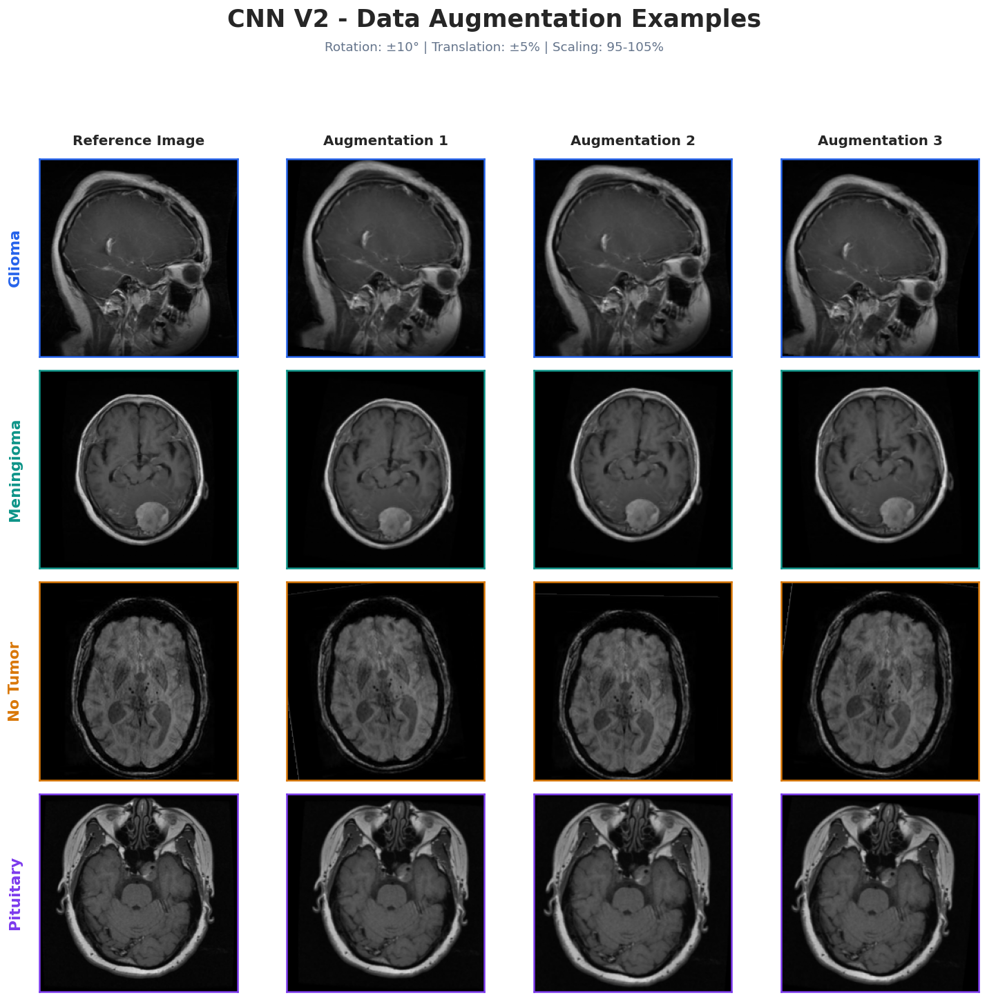

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/01_data_augmentation_examples.png

Data Augmentation görselleştirmesi tamamlandı.


In [14]:
# ==================================================
# 4. DATA AUGMENTATION GÖRSELLEŞTİRMESİ
# ==================================================

# --------------------------------------------------
# 4.1. GRAFİK KAYDETME FONKSİYONU
# --------------------------------------------------

def grafik_kaydet(fig, dosya_adi):

    kayit_yolu = sonuc_klasoru / dosya_adi

    fig.savefig(
        kayit_yolu,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("Grafik kaydedildi:")
    print(kayit_yolu)


# --------------------------------------------------
# 4.2. TERS NORMALİZASYON FONKSİYONU
# --------------------------------------------------

def denormalize(tensor):

    tensor = tensor.detach().cpu().clone()

    tensor = tensor * STD + MEAN

    tensor = torch.clamp(tensor, 0, 1)

    return tensor.squeeze(0).numpy()


# --------------------------------------------------
# 4.3. HER SINIFTAN ÖRNEK GÖRÜNTÜ SEÇİMİ
# --------------------------------------------------

ornekler = {}

for sinif in SINIFLAR:

    sinif_verileri = train_df[
        train_df["sinif"] == sinif
    ]

    ornek = sinif_verileri.sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    ornekler[sinif] = ornek["dosya"]


print("Seçilen örnek görüntüler:\n")

for sinif, dosya in ornekler.items():

    print(f"{sinif}: {dosya}")


# --------------------------------------------------
# 4.4. AUGMENTATION KARŞILAŞTIRMA GRAFİĞİ
# --------------------------------------------------

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(13, 13)
)

sutun_basliklari = [
    "Reference Image",
    "Augmentation 1",
    "Augmentation 2",
    "Augmentation 3"
]

# Görselleştirme için sabit rastgelelik
# Eğitimde kullanılacak RNG durumunu değiştirmez.

with torch.random.fork_rng(devices=[]):

    torch.random.default_generator.manual_seed(SEED)

    for i, sinif in enumerate(SINIFLAR):

        goruntu_yolu = (
            dataset_root / ornekler[sinif]
        )

        with Image.open(goruntu_yolu) as img:

            goruntuler = [
                eval_transform(img),
                train_transform(img),
                train_transform(img),
                train_transform(img)
            ]

        for j, tensor in enumerate(goruntuler):

            goruntu = denormalize(tensor)

            axes[i, j].imshow(
                goruntu,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            axes[i, j].grid(False)

            for spine in axes[i, j].spines.values():

                spine.set_visible(True)
                spine.set_color(RENKLER[sinif])
                spine.set_linewidth(1.5)

            if i == 0:

                axes[i, j].set_title(
                    sutun_basliklari[j],
                    fontsize=12,
                    fontweight="bold",
                    pad=12
                )

            if j == 0:

                axes[i, j].set_ylabel(
                    SINIF_ISIMLERI[i],
                    fontsize=13,
                    fontweight="bold",
                    color=RENKLER[sinif],
                    labelpad=15
                )


fig.suptitle(
    "CNN V2 - Data Augmentation Examples",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.94,
    "Rotation: ±10° | Translation: ±5% | "
    "Scaling: 95-105%",
    ha="center",
    fontsize=11,
    color="#64748B"
)

fig.tight_layout(
    rect=[0.02, 0.055, 0.98, 0.91]
)

grafik_kaydet(
    fig,
    "01_data_augmentation_examples.png"
)

print("\nData Augmentation görselleştirmesi tamamlandı.")

In [ ]:
# ==================================================
# 5. DATASET VE DATALOADER
# 5.1. CUSTOM DATASET SINIFI
# ==================================================

class BrainTumorDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root_dir,
        transform=None
    ):

        self.dataframe = (
            dataframe.reset_index(drop=True)
        )

        self.root_dir = Path(root_dir)

        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, idx):

        satir = self.dataframe.iloc[idx]

        goruntu_yolu = (
            self.root_dir / satir["dosya"]
        )

        sinif = satir["sinif"]

        label = CLASS_TO_IDX[sinif]

        with Image.open(goruntu_yolu) as img:

            image = img.convert("L")

        if self.transform is not None:

            image = self.transform(image)

        return image, label


# --------------------------------------------------
# DATASET NESNELERİ
# --------------------------------------------------

train_dataset = BrainTumorDataset(
    dataframe=train_df,
    root_dir=dataset_root,
    transform=train_transform
)

val_dataset = BrainTumorDataset(
    dataframe=val_df,
    root_dir=dataset_root,
    transform=val_transform
)

test_dataset = BrainTumorDataset(
    dataframe=test_df,
    root_dir=dataset_root,
    transform=test_transform
)


# --------------------------------------------------
# DATASET KONTROLÜ
# --------------------------------------------------

print("=" * 60)
print("CNN V2 - DATASET KONTROLÜ")
print("=" * 60)

print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Test Dataset:", len(test_dataset))

ornek_goruntu, ornek_label = train_dataset[0]

print("\nÖrnek görüntü boyutu:", ornek_goruntu.shape)
print("Sayısal etiket:", ornek_label)
print("Sınıf:", IDX_TO_CLASS[ornek_label])
print("Veri tipi:", ornek_goruntu.dtype)

assert ornek_goruntu.shape == (1, 224, 224)
assert ornek_label in range(4)

print("\nDataset kontrolleri başarılı.")

In [ ]:
# ==================================================
# 5.2. DATALOADER OLUŞTURULMASI
# ==================================================

BATCH_SIZE = 32
NUM_WORKERS = 2

PIN_MEMORY = device.type == "cuda"


# --------------------------------------------------
# TEKRAR ÜRETİLEBİLİRLİK
# --------------------------------------------------

def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)

    random.seed(worker_seed)


generator = torch.Generator()
generator.manual_seed(SEED)


# --------------------------------------------------
# TRAIN DATALOADER
# --------------------------------------------------

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    worker_init_fn=seed_worker,

    generator=generator,

    drop_last=False,

    persistent_workers=NUM_WORKERS > 0
)


# --------------------------------------------------
# VALIDATION DATALOADER
# --------------------------------------------------

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    drop_last=False,

    persistent_workers=NUM_WORKERS > 0
)


# --------------------------------------------------
# TEST DATALOADER
# --------------------------------------------------

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    drop_last=False,

    persistent_workers=NUM_WORKERS > 0
)


print("=" * 60)
print("CNN V2 - DATALOADER BİLGİLERİ")
print("=" * 60)

print("Batch Size:", BATCH_SIZE)
print("Num Workers:", NUM_WORKERS)
print("Pin Memory:", PIN_MEMORY)

print("\nTrain Batch Sayısı:", len(train_loader))

print("Validation Batch Sayısı:", len(val_loader))

print("Test Batch Sayısı:", len(test_loader))

print("\nDataLoader nesneleri hazır.")

In [ ]:
# ==================================================
# 5.3. BATCH DOĞRULAMA KONTROLÜ
# ==================================================

images, labels = next(iter(train_loader))

print("=" * 60)
print("CNN V2 - BATCH KONTROLÜ")
print("=" * 60)

print("Görüntü boyutu:", images.shape)

print("Etiket boyutu:", labels.shape)

print("Görüntü veri tipi:", images.dtype)

print("Etiket veri tipi:", labels.dtype)

print(f"\nMinimum: {images.min().item():.4f}")

print(f"Maksimum: {images.max().item():.4f}")

print("\nİlk batch sınıf dağılımı:")

for idx, sinif in IDX_TO_CLASS.items():

    adet = (labels == idx).sum().item()

    print(f"{sinif}: {adet}")


# Boyut kontrolleri

assert images.shape == (
    BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE
)

assert labels.shape == (BATCH_SIZE,)

assert labels.dtype == torch.int64

assert torch.isfinite(images).all()

assert labels.min().item() >= 0
assert labels.max().item() < 4


# GPU aktarım kontrolü

gpu_images = images.to(
    device,
    non_blocking=PIN_MEMORY
)

gpu_labels = labels.to(
    device,
    non_blocking=PIN_MEMORY
)

print("\nGörüntü cihazı:", gpu_images.device)

print("Etiket cihazı:", gpu_labels.device)

# Gereksiz GPU belleğini serbest bırak

del gpu_images, gpu_labels

print("\nBütün batch kontrolleri başarılı.")
print("CNN V2 eğitim verileri hazır.")

In [ ]:
# ==================================================
# 6. CLASS WEIGHTS - SINIF AĞIRLIKLARI
# 6.1. SINIF AĞIRLIKLARININ HESAPLANMASI
# ==================================================

from sklearn.utils.class_weight import compute_class_weight
import json

# Eğitim etiketlerini sayısal değerlere dönüştür

train_labels = (
    train_df["sinif"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

# Sınıf başına görüntü sayısı

class_counts = (
    train_df["sinif"]
    .value_counts()
    .reindex(SINIFLAR)
    .to_numpy()
)

# --------------------------------------------------
# CLASS WEIGHTS
# --------------------------------------------------

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(SINIFLAR)),
    y=train_labels
)

# PyTorch tensor oluştur ve GPU'ya aktar

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


# --------------------------------------------------
# SINIF AĞIRLIKLARI TABLOSU
# --------------------------------------------------

class_weight_df = pd.DataFrame({

    "Class": SINIF_ISIMLERI,

    "Class_Index": np.arange(len(SINIFLAR)),

    "Train_Count": class_counts,

    "Percentage": (
        class_counts / len(train_df) * 100
    ),

    "Class_Weight": class_weights

})

print("=" * 60)
print("CNN V2 - CLASS WEIGHTS")
print("=" * 60)

display(class_weight_df.round(4))

print("\nClass Weights Tensor:")
print(class_weights_tensor)

print("\nTensor cihazı:", class_weights_tensor.device)

assert len(class_weights_tensor) == 4

assert torch.isfinite(class_weights_tensor).all()

assert (class_weights_tensor > 0).all()


# CSV olarak kaydet

class_weight_df.to_csv(
    sonuc_klasoru / "class_weights.csv",
    index=False
)

# Modelin ön işleme ayarlarını kaydet

preprocessing_config = {
    "image_size": IMG_SIZE,
    "channels": 1,
    "mean": float(MEAN),
    "std": float(STD),
    "class_to_idx": CLASS_TO_IDX,
    "class_weights": class_weights.tolist(),
    "dataset_version": "veri_bolunmesi_v3"
}

with open(
    sonuc_klasoru / "preprocessing_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

print("\nSınıf ağırlıkları başarıyla hesaplandı.")
print("Ön işleme ayarları kaydedildi.")

In [ ]:
# ==================================================
# 6.2. SINIF AĞIRLIKLARI GÖRSELLEŞTİRMESİ
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

sinif_renkleri = [
    RENKLER[sinif]
    for sinif in SINIFLAR
]

# --------------------------------------------------
# SOL GRAFİK - TRAINING CLASS DISTRIBUTION
# --------------------------------------------------

bars1 = axes[0].bar(
    SINIF_ISIMLERI,
    class_counts,
    color=sinif_renkleri,
    width=0.62
)

axes[0].set_title(
    "Training Class Distribution",
    pad=15
)

axes[0].set_ylabel("Number of Images")

axes[0].set_ylim(
    0,
    max(class_counts) * 1.20
)

axes[0].bar_label(
    bars1,
    padding=5,
    fontsize=11,
    fontweight="bold"
)

axes[0].grid(axis="x", visible=False)


# --------------------------------------------------
# SAĞ GRAFİK - CLASS WEIGHTS
# --------------------------------------------------

bars2 = axes[1].bar(
    SINIF_ISIMLERI,
    class_weights,
    color=sinif_renkleri,
    width=0.62
)

axes[1].set_title(
    "Balanced Class Weights",
    pad=15
)

axes[1].set_ylabel("Class Weight")

axes[1].set_ylim(
    0,
    max(class_weights) * 1.25
)

axes[1].bar_label(
    bars2,
    fmt="%.3f",
    padding=5,
    fontsize=11,
    fontweight="bold"
)

axes[1].axhline(
    y=1.0,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Reference Weight (1.0)"
)

axes[1].legend(loc="upper left")

axes[1].grid(axis="x", visible=False)


# --------------------------------------------------
# ANA BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Class Distribution and Loss Weights",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.91,
    "Training Dataset | 3,870 Images | "
    "Inverse Frequency Weighting",
    ha="center",
    fontsize=11,
    color="#64748B"
)

fig.tight_layout(
    rect=[0, 0.02, 1, 0.86]
)

grafik_kaydet(
    fig,
    "02_class_distribution_and_weights.png"
)

print("\nSınıf ağırlıkları grafiği tamamlandı.")

In [15]:
# ==================================================
# 7. CNN V2 MODEL MİMARİSİ
# 7.1. CONVOLUTION BLOCK
# ==================================================

class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.1
    ):

        super().__init__()

        self.block = nn.Sequential(

            # Birinci Convolution
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            # İkinci Convolution
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            # Boyut azaltma
            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            # Regularization
            nn.Dropout2d(p=dropout)

        )


    def forward(self, x):

        return self.block(x)


print("ConvBlock sınıfı başarıyla oluşturuldu.")

ConvBlock sınıfı başarıyla oluşturuldu.


In [16]:
# ==================================================
# 7.2. CNN V2 MODEL SINIFI
# ==================================================

class CNN_V2(nn.Module):

    def __init__(self, num_classes=4):

        super().__init__()

        # ------------------------------------------
        # FEATURE EXTRACTION
        # ------------------------------------------

        self.features = nn.Sequential(

            ConvBlock(
                in_channels=1,
                out_channels=32,
                dropout=0.05
            ),

            ConvBlock(
                in_channels=32,
                out_channels=64,
                dropout=0.10
            ),

            ConvBlock(
                in_channels=64,
                out_channels=128,
                dropout=0.15
            ),

            ConvBlock(
                in_channels=128,
                out_channels=256,
                dropout=0.20
            )

        )

        # ------------------------------------------
        # ADAPTIVE AVERAGE POOLING
        # ------------------------------------------

        self.avgpool = nn.AdaptiveAvgPool2d(
            output_size=(4, 4)
        )

        # ------------------------------------------
        # CLASSIFIER
        # ------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 4 * 4, 512),

            nn.BatchNorm1d(512),

            nn.ReLU(inplace=True),

            nn.Dropout(0.40),

            nn.Linear(512, 128),

            nn.BatchNorm1d(128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.30),

            nn.Linear(128, num_classes)

        )

        # Ağırlıkların başlatılması

        self._initialize_weights()


    # ----------------------------------------------
    # WEIGHT INITIALIZATION
    # ----------------------------------------------

    def _initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Conv2d):

                nn.init.kaiming_normal_(
                    m.weight,
                    mode="fan_in",
                    nonlinearity="relu"
                )

            elif isinstance(
                m,
                (nn.BatchNorm2d, nn.BatchNorm1d)
            ):

                nn.init.ones_(m.weight)

                nn.init.zeros_(m.bias)

            elif isinstance(m, nn.Linear):

                nn.init.kaiming_normal_(
                    m.weight,
                    mode="fan_in",
                    nonlinearity="relu"
                )

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

        # Son sınıflandırma katmanı
        nn.init.xavier_uniform_(
            self.classifier[-1].weight
        )


    # ----------------------------------------------
    # FORWARD PASS
    # ----------------------------------------------

    def forward(self, x):

        x = self.features(x)

        x = self.avgpool(x)

        x = self.classifier(x)

        return x


print("CNN V2 model sınıfı oluşturuldu.")

CNN V2 model sınıfı oluşturuldu.


In [17]:
# ==================================================
# 7.3. MODEL OLUŞTURMA VE FORWARD PASS
# ==================================================

torch.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)

model = CNN_V2(
    num_classes=len(SINIFLAR)
).to(device)


# --------------------------------------------------
# PARAMETRE SAYILARI
# --------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("CNN V2 - MODEL BİLGİLERİ")
print("=" * 60)

print("Model:", model.__class__.__name__)

print("Cihaz:", next(model.parameters()).device)

print(f"Toplam parametre: {total_params:,}")

print(f"Eğitilebilir parametre: {trainable_params:,}")

print(
    f"Eğitilemeyen parametre: "
    f"{total_params - trainable_params:,}"
)


# --------------------------------------------------
# FORWARD PASS
# --------------------------------------------------

model.eval()

dummy_input = torch.randn(
    2, 1, IMG_SIZE, IMG_SIZE,
    device=device
)

with torch.inference_mode():

    dummy_output = model(dummy_input)

    probabilities = torch.softmax(
        dummy_output,
        dim=1
    )


print("\nGiriş boyutu:", dummy_input.shape)

print("Çıkış boyutu:", dummy_output.shape)

print("\nÖrnek model çıktısı:")

print(dummy_output)

print("\nÖrnek sınıf olasılıkları:")

print(probabilities)

print("\nOlasılık toplamları:")

print(probabilities.sum(dim=1))


# --------------------------------------------------
# MODEL DOĞRULAMA
# --------------------------------------------------

assert dummy_output.shape == (2, 4)

assert torch.isfinite(dummy_output).all()

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(2, device=device),
    atol=1e-6
)

del dummy_input, dummy_output, probabilities

model.train()

print("\nForward Pass kontrolü başarılı.")

print("CNN V2 modeli eğitim için hazır.")

CNN V2 - MODEL BİLGİLERİ
Model: CNN_V2
Cihaz: cuda:0
Toplam parametre: 3,337,764
Eğitilebilir parametre: 3,337,764
Eğitilemeyen parametre: 0

Giriş boyutu: torch.Size([2, 1, 224, 224])
Çıkış boyutu: torch.Size([2, 4])

Örnek model çıktısı:
tensor([[ 2.0156,  3.9847,  1.7868, -4.7791],
        [ 1.6550,  3.9384,  1.9486, -4.6460]], device='cuda:0')

Örnek sınıf olasılıkları:
tensor([[1.1159e-01, 7.9950e-01, 8.8778e-02, 1.2495e-04],
        [8.2285e-02, 8.0721e-01, 1.1036e-01, 1.5095e-04]], device='cuda:0')

Olasılık toplamları:
tensor([1., 1.], device='cuda:0')

Forward Pass kontrolü başarılı.
CNN V2 modeli eğitim için hazır.


In [18]:
# ==================================================
# 8. MODEL MİMARİSİ VE PARAMETRE ANALİZİ
# 8.1. MODEL SUMMARY
# ==================================================

!pip install -q torchinfo

from torchinfo import summary

model_summary = summary(
    model,

    input_size=(1, 1, IMG_SIZE, IMG_SIZE),

    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "kernel_size",
        "trainable",
        "mult_adds"
    ],

    depth=4,

    device=str(device),

    mode="eval",

    verbose=0
)

print(model_summary)


# Model özetini Drive'a kaydet

summary_yolu = (
    sonuc_klasoru / "model_summary.txt"
)

with open(
    summary_yolu,
    "w",
    encoding="utf-8"
) as f:

    f.write(str(model_summary))


print("\nModel özeti kaydedildi:")

print(summary_yolu)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape              Trainable                 Mult-Adds
CNN_V2                                   [1, 1, 224, 224]          [1, 4]                    --                        --                        True                      --
├─Sequential: 1-1                        [1, 1, 224, 224]          [1, 256, 14, 14]          --                        --                        True                      --
│    └─ConvBlock: 2-1                    [1, 1, 224, 224]          [1, 32, 112, 112]         --                        --                        True                      --
│    │    └─Sequential: 3-1              [1, 1, 224, 224]          [1, 32, 112, 112]         --                        --                        True                      --
│    │    │    └─Conv2d: 4-1             [1, 1, 224, 224]          [1, 32, 224, 224]         288                       [3, 

In [19]:
# ==================================================
# 8.2. BLOK BAZINDA MİMARİ ANALİZİ
# ==================================================

mimari_kayitlari = []

model.eval()

x = torch.zeros(
    1, 1, IMG_SIZE, IMG_SIZE,
    device=device
)

with torch.inference_mode():

    # Convolution blokları

    for i, block in enumerate(model.features):

        giris_boyutu = tuple(x.shape[1:])

        x = block(x)

        cikis_boyutu = tuple(x.shape[1:])

        parametre = sum(
            p.numel()
            for p in block.parameters()
        )

        mimari_kayitlari.append({

            "Layer": f"Conv Block {i + 1}",

            "Input_Shape": giris_boyutu,

            "Output_Shape": cikis_boyutu,

            "Parameters": parametre,

            "Channels": x.shape[1],

            "Height": x.shape[2],

            "Width": x.shape[3]

        })


    # Adaptive Average Pooling

    giris_boyutu = tuple(x.shape[1:])

    x = model.avgpool(x)

    mimari_kayitlari.append({

        "Layer": "Adaptive AvgPool",

        "Input_Shape": giris_boyutu,

        "Output_Shape": tuple(x.shape[1:]),

        "Parameters": 0,

        "Channels": x.shape[1],

        "Height": x.shape[2],

        "Width": x.shape[3]

    })


    # Classifier

    giris_boyutu = tuple(x.shape[1:])

    x = model.classifier(x)

    mimari_kayitlari.append({

        "Layer": "Classifier",

        "Input_Shape": giris_boyutu,

        "Output_Shape": tuple(x.shape[1:]),

        "Parameters": sum(
            p.numel()
            for p in model.classifier.parameters()
        ),

        "Channels": None,

        "Height": None,

        "Width": None

    })


# DataFrame oluştur

architecture_df = pd.DataFrame(
    mimari_kayitlari
)

architecture_df["Parameter_Percentage"] = (

    architecture_df["Parameters"]
    / total_params * 100

)

print("=" * 60)
print("CNN V2 - MİMARİ ANALİZİ")
print("=" * 60)

display(architecture_df.round(2))


# Parametre doğrulaması

assert (
    architecture_df["Parameters"].sum()
    == total_params
)

assert x.shape == (1, 4)


# CSV kaydı

architecture_df.to_csv(

    sonuc_klasoru / "model_architecture.csv",

    index=False

)

del x

model.train()

print("\nMimari analizi başarıyla tamamlandı.")

CNN V2 - MİMARİ ANALİZİ


,Layer,Input_Shape,Output_Shape,Parameters,Channels,Height,Width,Parameter_Percentage
0,Conv Block 1,"(1, 224, 224)","(32, 112, 112)",9632,32.0,112.0,112.0,0.29
1,Conv Block 2,"(32, 112, 112)","(64, 56, 56)",55552,64.0,56.0,56.0,1.66
2,Conv Block 3,"(64, 56, 56)","(128, 28, 28)",221696,128.0,28.0,28.0,6.64
3,Conv Block 4,"(128, 28, 28)","(256, 14, 14)",885760,256.0,14.0,14.0,26.54
4,Adaptive AvgPool,"(256, 14, 14)","(256, 4, 4)",0,256.0,4.0,4.0,0.00
5,Classifier,"(256, 4, 4)","(4,)",2165124,NaN,NaN,NaN,64.87



Mimari analizi başarıyla tamamlandı.


In [ ]:
# ==================================================
# 8.3. MODEL MİMARİSİ GÖRSELLEŞTİRMESİ
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6)
)

blok_renkleri = [
    "#2563EB",
    "#0D9488",
    "#D97706",
    "#7C3AED",
    "#94A3B8",
    "#475569"
]


# --------------------------------------------------
# GRAFİK 1 - PARAMETRE DAĞILIMI
# --------------------------------------------------

bars = axes[0].barh(

    architecture_df["Layer"],

    architecture_df["Parameters"],

    color=blok_renkleri

)

axes[0].invert_yaxis()

axes[0].set_title(
    "Parameters by Layer",
    pad=15
)

axes[0].set_xlabel("Number of Parameters")

axes[0].set_xlim(
    0,
    architecture_df["Parameters"].max() * 1.35
)

axes[0].bar_label(

    bars,

    labels=[
        f"{int(p):,}"
        for p in architecture_df["Parameters"]
    ],

    padding=5,

    fontsize=10

)

axes[0].ticklabel_format(
    style="plain",
    axis="x"
)

axes[0].grid(axis="y", visible=False)


# --------------------------------------------------
# GRAFİK 2 - SPATIAL SIZE
# --------------------------------------------------

katmanlar = [
    "Input",
    "Block 1",
    "Block 2",
    "Block 3",
    "Block 4",
    "AvgPool"
]

spatial_sizes = [

    IMG_SIZE,

    *architecture_df["Height"]
    .dropna()
    .astype(int)
    .tolist()

]

axes[1].plot(

    katmanlar,

    spatial_sizes,

    marker="o",

    markersize=8,

    linewidth=2.5,

    color="#2563EB"

)

axes[1].fill_between(

    katmanlar,

    spatial_sizes,

    alpha=0.08,

    color="#2563EB"

)

for i, size in enumerate(spatial_sizes):

    axes[1].annotate(

        f"{size} × {size}",

        (i, size),

        xytext=(0, 12),

        textcoords="offset points",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

axes[1].set_title(
    "Spatial Dimension Reduction",
    pad=15
)

axes[1].set_ylabel("Spatial Size (px)")

axes[1].set_ylim(0, 265)

axes[1].tick_params(
    axis="x",
    rotation=30
)


# --------------------------------------------------
# GRAFİK 3 - FEATURE CHANNELS
# --------------------------------------------------

channel_sizes = [

    1,

    *architecture_df["Channels"]
    .dropna()
    .astype(int)
    .tolist()

]

bars = axes[2].bar(

    katmanlar,

    channel_sizes,

    color=[
        "#94A3B8",
        "#2563EB",
        "#0D9488",
        "#D97706",
        "#7C3AED",
        "#94A3B8"
    ],

    width=0.65

)

axes[2].bar_label(
    bars,
    padding=5,
    fontweight="bold"
)

axes[2].set_title(
    "Feature Channel Progression",
    pad=15
)

axes[2].set_ylabel("Number of Channels")

axes[2].set_ylim(0, 310)

axes[2].tick_params(
    axis="x",
    rotation=30
)

axes[2].grid(axis="x", visible=False)


# --------------------------------------------------
# ANA BAŞLIK
# --------------------------------------------------

fig.suptitle(

    "CNN V2 - Model Architecture Analysis",

    fontsize=21,

    fontweight="bold",

    y=0.98

)

fig.text(

    0.5,

    0.91,

    f"8 Convolutional Layers | "
    f"4 Convolution Blocks | "
    f"{total_params:,} Trainable Parameters",

    ha="center",

    fontsize=12,

    color="#64748B"

)

fig.tight_layout(
    rect=[0.01, 0.02, 0.99, 0.85]
)

grafik_kaydet(

    fig,

    "03_model_architecture_analysis.png"

)

print("\nModel mimarisi grafikleri tamamlandı.")

In [ ]:
# ==================================================
# 9. OPTIMIZER, LOSS FUNCTION VE SCHEDULER
# 9.1. EĞİTİM HİPERPARAMETRELERİ
# ==================================================

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

NUM_EPOCHS = 40

EARLY_STOPPING_PATIENCE = 8

SCHEDULER_PATIENCE = 3

SCHEDULER_FACTOR = 0.5

MIN_LR = 1e-6

MIN_DELTA = 1e-4

MAX_GRAD_NORM = 1.0


# --------------------------------------------------
# WEIGHTED CROSS ENTROPY LOSS
# --------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)


# --------------------------------------------------
# ADAMW OPTIMIZER
# --------------------------------------------------

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY

)


print("=" * 60)
print("CNN V2 - OPTIMIZER VE LOSS")
print("=" * 60)

print("\nLoss Function:")
print(criterion)

print("\nClass Weights:")
print(criterion.weight)

print("\nOptimizer:")
print(optimizer.__class__.__name__)

print("Learning Rate:", LEARNING_RATE)

print("Weight Decay:", WEIGHT_DECAY)

print("Maximum Epoch:", NUM_EPOCHS)

print("Gradient Clipping:", MAX_GRAD_NORM)

print("\nOptimizer ve Loss Function hazır.")

In [ ]:
# ==================================================
# 9.2. LEARNING RATE SCHEDULER
# ==================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=SCHEDULER_FACTOR,

    patience=SCHEDULER_PATIENCE,

    threshold=MIN_DELTA,

    threshold_mode="abs",

    min_lr=MIN_LR

)


print("=" * 60)
print("CNN V2 - LEARNING RATE SCHEDULER")
print("=" * 60)

print("Scheduler:", scheduler.__class__.__name__)

print("Monitoring Metric: Validation Loss")

print("Mode:", scheduler.mode)

print("Factor:", scheduler.factor)

print("Patience:", scheduler.patience)

print("Minimum LR:", MIN_LR)

print("Threshold:", MIN_DELTA)

print(
    "\nBaşlangıç Learning Rate:",
    optimizer.param_groups[0]["lr"]
)

print("\nLearning Rate Scheduler hazır.")

In [ ]:
# ==================================================
# 9.3. MIXED PRECISION TRAINING (AMP)
# ==================================================

USE_AMP = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

AMP_DTYPE = torch.float16


print("=" * 60)
print("CNN V2 - MIXED PRECISION TRAINING")
print("=" * 60)

print("AMP Enabled:", USE_AMP)

print("AMP Data Type:", AMP_DTYPE)

print("GradScaler Enabled:", scaler.is_enabled())

print("Initial Scale:", scaler.get_scale())

print("\nMixed Precision ayarları hazır.")

In [ ]:
# ==================================================
# 9.4. TRAINING CONFIGURATION
# ==================================================

training_config = {

    "model_name": "CNN_V2",

    "dataset_version": "veri_bolunmesi_v3",

    "seed": SEED,

    "image_size": IMG_SIZE,

    "batch_size": BATCH_SIZE,

    "num_workers": NUM_WORKERS,

    "num_classes": len(SINIFLAR),

    "total_parameters": total_params,

    "trainable_parameters": trainable_params,

    "optimizer": "AdamW",

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "loss_function": "Weighted Cross Entropy",

    "class_weights": class_weights.tolist(),

    "scheduler": "ReduceLROnPlateau",

    "scheduler_patience": SCHEDULER_PATIENCE,

    "scheduler_factor": SCHEDULER_FACTOR,

    "min_lr": MIN_LR,

    "max_epochs": NUM_EPOCHS,

    "early_stopping_patience": EARLY_STOPPING_PATIENCE,

    "min_delta": MIN_DELTA,

    "gradient_clipping": MAX_GRAD_NORM,

    "mixed_precision": USE_AMP,

    "mean": float(MEAN),

    "std": float(STD),

    "class_to_idx": CLASS_TO_IDX,

    "augmentation": {
        "rotation": 10,
        "translation": [0.05, 0.05],
        "scale": [0.95, 1.05],
        "horizontal_flip": False,
        "vertical_flip": False
    },

    "device": str(device),

    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )

}

config_yolu = sonuc_klasoru / "training_config.json"

with open(
    config_yolu,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_config,
        f,
        indent=4
    )


print("=" * 60)
print("CNN V2 - TRAINING CONFIGURATION")
print("=" * 60)

display(
    pd.DataFrame([
        {
            "Parameter": key,
            "Value": str(value)
        }
        for key, value in training_config.items()
    ])
)

print("\nEğitim konfigürasyonu kaydedildi:")

print(config_yolu)

print("\nBütün eğitim ayarları hazır.")

In [ ]:
# ==================================================
# 10. EĞİTİM VE DOĞRULAMA FONKSİYONLARI
# 10.1. PERFORMANS METRİKLERİ
# ==================================================

def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        labels=list(range(len(SINIFLAR))),
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        labels=list(range(len(SINIFLAR))),
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(len(SINIFLAR))),
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1)
    }


print("Performans metrikleri fonksiyonu hazır.")

In [ ]:
# ==================================================
# 10.2. TRAINING FUNCTION
# ==================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    scaler,
    epoch
):

    model.train()

    total_loss = 0.0
    total_weight = 0.0

    all_labels = []
    all_predictions = []

    start_time = time.perf_counter()

    progress_bar = tqdm(
        dataloader,
        desc=f"Epoch {epoch:02d} | Train",
        leave=False
    )

    for images, labels in progress_bar:

        # GPU'ya aktarım

        images = images.to(
            device,
            non_blocking=PIN_MEMORY
        )

        labels = labels.to(
            device,
            non_blocking=PIN_MEMORY
        )

        # Önceki gradyanları temizle

        optimizer.zero_grad(set_to_none=True)

        # ------------------------------------------
        # FORWARD PASS - MIXED PRECISION
        # ------------------------------------------

        with torch.amp.autocast(
            device_type=device.type,
            dtype=AMP_DTYPE,
            enabled=USE_AMP
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        # Geçersiz loss kontrolü

        if not torch.isfinite(loss).item():

            raise RuntimeError(
                f"Epoch {epoch}: Geçersiz loss tespit edildi."
            )

        # ------------------------------------------
        # BACKWARD PASS
        # ------------------------------------------

        scaler.scale(loss).backward()

        # Gradient Clipping öncesi ölçeği kaldır

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=MAX_GRAD_NORM
        )

        # Model ağırlıklarını güncelle

        scaler.step(optimizer)

        scaler.update()

        # ------------------------------------------
        # LOSS HESAPLAMA
        # ------------------------------------------

        batch_weight = (
            class_weights_tensor[labels]
            .sum()
            .item()
        )

        total_loss += loss.item() * batch_weight

        total_weight += batch_weight

        # ------------------------------------------
        # TAHMİNLER
        # ------------------------------------------

        predictions = outputs.detach().argmax(dim=1)

        all_labels.extend(
            labels.cpu().tolist()
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        progress_bar.set_postfix(
            loss=f"{total_loss / total_weight:.4f}"
        )

    # ----------------------------------------------
    # EPOCH SONU METRİKLERİ
    # ----------------------------------------------

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    metrics["loss"] = total_loss / total_weight

    metrics["time"] = (
        time.perf_counter() - start_time
    )

    return metrics


print("Training fonksiyonu başarıyla oluşturuldu.")

In [ ]:
# ==================================================
# 10.3. VALIDATION FUNCTION
# ==================================================

@torch.inference_mode()
def validate_one_epoch(
    model,
    dataloader,
    criterion,
    epoch
):

    model.eval()

    total_loss = 0.0
    total_weight = 0.0

    all_labels = []
    all_predictions = []

    start_time = time.perf_counter()

    progress_bar = tqdm(
        dataloader,
        desc=f"Epoch {epoch:02d} | Validation",
        leave=False
    )

    for images, labels in progress_bar:

        images = images.to(
            device,
            non_blocking=PIN_MEMORY
        )

        labels = labels.to(
            device,
            non_blocking=PIN_MEMORY
        )

        # ------------------------------------------
        # FORWARD PASS
        # ------------------------------------------

        with torch.amp.autocast(
            device_type=device.type,
            dtype=AMP_DTYPE,
            enabled=USE_AMP
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        if not torch.isfinite(loss).item():

            raise RuntimeError(
                f"Epoch {epoch}: Geçersiz validation loss."
            )

        # ------------------------------------------
        # LOSS HESAPLAMA
        # ------------------------------------------

        batch_weight = (
            class_weights_tensor[labels]
            .sum()
            .item()
        )

        total_loss += loss.item() * batch_weight

        total_weight += batch_weight

        # ------------------------------------------
        # TAHMİNLER
        # ------------------------------------------

        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.cpu().tolist()
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        progress_bar.set_postfix(
            loss=f"{total_loss / total_weight:.4f}"
        )

    # ----------------------------------------------
    # EPOCH SONU METRİKLERİ
    # ----------------------------------------------

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    metrics["loss"] = total_loss / total_weight

    metrics["time"] = (
        time.perf_counter() - start_time
    )

    return metrics


print("Validation fonksiyonu başarıyla oluşturuldu.")

In [ ]:
# ==================================================
# 10.4. FUNCTION SANITY CHECK
# ==================================================

print("=" * 60)
print("CNN V2 - FONKSİYON KONTROLÜ")
print("=" * 60)

# --------------------------------------------------
# METRİK FONKSİYONU KONTROLÜ
# --------------------------------------------------

sample_true = [0, 1, 2, 3]
sample_pred = [0, 1, 2, 3]

sample_metrics = calculate_metrics(
    sample_true,
    sample_pred
)

print("\nMetrik fonksiyonu kontrolü:")

for key, value in sample_metrics.items():

    print(f"{key.capitalize()}: {value:.4f}")

    assert np.isclose(value, 1.0)


# --------------------------------------------------
# VALIDATION FONKSİYONU KONTROLÜ
# --------------------------------------------------

sample_batch = next(iter(val_loader))

sample_validation_loader = [sample_batch]

sample_results = validate_one_epoch(
    model=model,
    dataloader=sample_validation_loader,
    criterion=criterion,
    epoch=0
)

print("\nValidation fonksiyonu kontrolü:")

for key, value in sample_results.items():

    print(f"{key.capitalize()}: {value:.4f}")

    assert np.isfinite(value)

    if key in ["accuracy", "precision", "recall", "f1"]:

        assert 0 <= value <= 1

assert sample_results["loss"] >= 0

model.train()

del sample_batch
del sample_validation_loader

print("\nMetrik fonksiyonu: Başarılı")
print("Validation fonksiyonu: Başarılı")

print("Training fonksiyonu: Tanımlandı")

print("\nModel ağırlıkları güncellenmedi.")

print("Bütün ön eğitim fonksiyonları hazır.")

In [ ]:
# ==================================================
# 11. EARLY STOPPING VE CHECKPOINT
# 11.1. EARLY STOPPING SINIFI
# ==================================================

class EarlyStopping:

    def __init__(
        self,
        patience=8,
        min_delta=1e-4
    ):

        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = float("inf")
        self.best_epoch = 0

        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss, epoch):

        improved = (
            val_loss < self.best_loss - self.min_delta
        )

        if improved:

            self.best_loss = val_loss
            self.best_epoch = epoch
            self.counter = 0

        else:

            self.counter += 1

            if self.counter >= self.patience:

                self.early_stop = True

        return improved

    def state_dict(self):

        return {
            "patience": self.patience,
            "min_delta": self.min_delta,
            "best_loss": self.best_loss,
            "best_epoch": self.best_epoch,
            "counter": self.counter,
            "early_stop": self.early_stop
        }

    def load_state_dict(self, state):

        for key, value in state.items():

            setattr(self, key, value)


early_stopping = EarlyStopping(
    patience=EARLY_STOPPING_PATIENCE,
    min_delta=MIN_DELTA
)

print("=" * 60)
print("CNN V2 - EARLY STOPPING")
print("=" * 60)

print("Patience:", early_stopping.patience)
print("Min Delta:", early_stopping.min_delta)
print("Best Loss:", early_stopping.best_loss)
print("Counter:", early_stopping.counter)
print("Early Stop:", early_stopping.early_stop)

print("\nEarly Stopping sistemi hazır.")

In [ ]:
# ==================================================
# 11.2. CHECKPOINT KAYIT SİSTEMİ
# ==================================================

best_model_yolu = model_klasoru / "cnn_v2_best.pth"

last_model_yolu = model_klasoru / "cnn_v2_last.pth"

history_yolu = sonuc_klasoru / "training_history.csv"


# --------------------------------------------------
# GÜVENLİ DOSYA KAYDETME
# --------------------------------------------------

def atomic_torch_save(data, path):

    path = Path(path)

    temp_path = path.with_suffix(".tmp")

    torch.save(data, temp_path)

    os.replace(temp_path, path)


# --------------------------------------------------
# CHECKPOINT FONKSİYONU
# --------------------------------------------------

def save_checkpoint(
    epoch,
    history,
    val_metrics,
    is_best=False
):

    checkpoint = {

        "epoch": epoch,

        "model_name": "CNN_V2",

        "model_state_dict": model.state_dict(),

        "optimizer_state_dict": optimizer.state_dict(),

        "scheduler_state_dict": scheduler.state_dict(),

        "scaler_state_dict": scaler.state_dict(),

        "early_stopping_state": early_stopping.state_dict(),

        "history": history,

        "val_loss": val_metrics["loss"],

        "val_acc": val_metrics["accuracy"],

        "val_f1": val_metrics["f1"],

        "class_to_idx": CLASS_TO_IDX,

        "preprocessing_config": preprocessing_config,

        "training_config": training_config,

        "dataset_version": "veri_bolunmesi_v3",

        # Rastgelelik durumları

        "torch_rng_state": torch.get_rng_state(),

        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),

        "numpy_rng_state": np.random.get_state(),

        "python_rng_state": random.getstate(),

        "dataloader_rng_state": generator.get_state()

    }

    # Son tamamlanan epoch

    atomic_torch_save(
        checkpoint,
        last_model_yolu
    )

    # Şimdiye kadarki en düşük validation loss

    if is_best:

        atomic_torch_save(
            checkpoint,
            best_model_yolu
        )

        print(
            f"En iyi model kaydedildi | "
            f"Epoch {epoch} | "
            f"Loss: {val_metrics['loss']:.4f}"
        )

    # Eğitim geçmişini CSV olarak kaydet

    pd.DataFrame(history).to_csv(
        history_yolu,
        index=False
    )


print("=" * 60)
print("CNN V2 - CHECKPOINT SİSTEMİ")
print("=" * 60)

print("\nBest Model:")
print(best_model_yolu)

print("\nLast Model:")
print(last_model_yolu)

print("\nTraining History:")
print(history_yolu)

print("\nCheckpoint kayıt fonksiyonu hazır.")

In [ ]:
# ==================================================
# 11.3. RESUME TRAINING
# ==================================================

def load_checkpoint(checkpoint_path):

    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.exists():

        raise FileNotFoundError(checkpoint_path)

    # Yalnızca kendi oluşturduğumuz güvenilir
    # checkpoint dosyaları için kullanılmalıdır.

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["model_name"] == "CNN_V2"

    assert (
        checkpoint["dataset_version"]
        == "veri_bolunmesi_v3"
    )

    assert checkpoint["class_to_idx"] == CLASS_TO_IDX

    # Model ve optimizer

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # Scheduler ve Mixed Precision

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    # Early Stopping

    early_stopping.load_state_dict(
        checkpoint["early_stopping_state"]
    )

    # Rastgelelik durumları

    torch.set_rng_state(
        checkpoint["torch_rng_state"]
    )

    if (
        torch.cuda.is_available()
        and checkpoint["cuda_rng_state"] is not None
    ):

        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

    np.random.set_state(
        checkpoint["numpy_rng_state"]
    )

    random.setstate(
        checkpoint["python_rng_state"]
    )

    generator.set_state(
        checkpoint["dataloader_rng_state"]
    )

    start_epoch = checkpoint["epoch"] + 1

    history = checkpoint["history"]

    print("=" * 60)
    print("CHECKPOINT YÜKLENDİ")
    print("=" * 60)

    print("Son tamamlanan epoch:", checkpoint["epoch"])
    print("Devam edilecek epoch:", start_epoch)

    print("En iyi epoch:", early_stopping.best_epoch)

    print(
        "En iyi kabul edilen loss:",
        early_stopping.best_loss
    )

    print(
        "Güncel Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    return start_epoch, history


print("Checkpoint yükleme fonksiyonu hazır.")

In [ ]:
# ==================================================
# 11.4. TRAINING HISTORY
# ==================================================

history_columns = [

    "epoch",

    "train_loss",
    "val_loss",

    "train_accuracy",
    "val_accuracy",

    "train_precision",
    "val_precision",

    "train_recall",
    "val_recall",

    "train_f1",
    "val_f1",

    "learning_rate",
    "next_learning_rate",

    "train_time",
    "val_time",
    "epoch_time",

    "early_stopping_counter",

    "is_best"

]


# --------------------------------------------------
# EĞİTİM BAŞLANGIÇ AYARLARI
# --------------------------------------------------

RESUME_TRAINING = False

history = []

start_epoch = 1

best_val_loss = float("inf")

best_epoch = 0


if RESUME_TRAINING:

    start_epoch, history = load_checkpoint(
        last_model_yolu
    )

    if history:

        best_record = min(
            history,
            key=lambda row: row["val_loss"]
        )

        best_val_loss = best_record["val_loss"]

        best_epoch = best_record["epoch"]

else:

    if last_model_yolu.exists() or best_model_yolu.exists():

        raise RuntimeError(
            "Mevcut CNN V2 checkpoint bulundu. "
            "Dosyaların üzerine yazmadan önce "
            "eğitime devam etme durumunu kontrol et."
        )

    print("Yeni eğitim başlatılacak.")


print("=" * 60)
print("CNN V2 - EĞİTİM BAŞLANGIÇ DURUMU")
print("=" * 60)

print("Resume Training:", RESUME_TRAINING)

print("Başlangıç Epoch:", start_epoch)

print("Maximum Epoch:", NUM_EPOCHS)

print("History kayıt sayısı:", len(history))

print("Best Validation Loss:", best_val_loss)

print("Best Epoch:", best_epoch)

print("\nKaydedilecek metrikler:")

display(
    pd.DataFrame(columns=history_columns)
)

print("\nEğitim geçmişi hazır.")

In [ ]:
# ==================================================
# 11.5. EARLY STOPPING SANITY CHECK
# ==================================================

test_stopper = EarlyStopping(
    patience=3,
    min_delta=1e-4
)

sample_losses = [
    1.20,
    0.90,
    0.70,
    0.72,
    0.74,
    0.76
]

test_results = []

for epoch, loss in enumerate(
    sample_losses,
    start=1
):

    improved = test_stopper(loss, epoch)

    test_results.append({

        "Epoch": epoch,

        "Validation_Loss": loss,

        "Improved": improved,

        "Counter": test_stopper.counter,

        "Early_Stop": test_stopper.early_stop

    })

    if test_stopper.early_stop:

        break


print("=" * 60)
print("EARLY STOPPING DOĞRULAMA TESTİ")
print("=" * 60)

display(pd.DataFrame(test_results))

print("En iyi epoch:", test_stopper.best_epoch)

print("En iyi loss:", test_stopper.best_loss)

print("Early Stop:", test_stopper.early_stop)


assert test_stopper.best_epoch == 3

assert np.isclose(test_stopper.best_loss, 0.70)

assert test_stopper.early_stop

assert early_stopping.counter == 0 or RESUME_TRAINING


print("\nEarly Stopping doğrulaması başarılı.")

print("Gerçek eğitim durumunda değişiklik yapılmadı.")

print("\nCNN V2 eğitim başlatılmaya hazır.")

In [ ]:
# ==================================================
# 12. CNN V2 MODEL EĞİTİMİ
# 12.1. EĞİTİM ÖNCESİ SON KONTROL
# ==================================================

gerekli_degiskenler = [
    "model",
    "optimizer",
    "criterion",
    "scheduler",
    "scaler",
    "early_stopping",
    "train_loader",
    "val_loader",
    "train_one_epoch",
    "validate_one_epoch",
    "save_checkpoint",
    "generator",
    "preprocessing_config",
    "training_config",
    "history",
    "start_epoch",
    "best_val_loss",
    "best_epoch"
]

eksik_degiskenler = [
    isim
    for isim in gerekli_degiskenler
    if isim not in globals()
]

assert not eksik_degiskenler, (
    f"Eksik değişkenler: {eksik_degiskenler}"
)

assert next(model.parameters()).device.type == device.type

assert criterion.weight.device.type == device.type

assert len(train_loader) == 121

assert len(val_loader) == 32

print("=" * 60)
print("CNN V2 - EĞİTİM ÖNCESİ SON KONTROL")
print("=" * 60)

print("Model cihazı:", next(model.parameters()).device)

print("Training Batch:", len(train_loader))

print("Validation Batch:", len(val_loader))

print("Başlangıç Epoch:", start_epoch)

print("Maximum Epoch:", NUM_EPOCHS)

print("Learning Rate:", optimizer.param_groups[0]["lr"])

print("Mixed Precision:", USE_AMP)

print("\nEksik değişken:", len(eksik_degiskenler))

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    free_memory, total_memory = torch.cuda.mem_get_info()

    print(
        f"Kullanılabilir GPU belleği: "
        f"{free_memory / 1024**3:.2f} GB"
    )

print("\nBütün eğitim kontrolleri başarılı.")
print("CNN V2 eğitime hazır.")

In [ ]:
# ==================================================
# 12.2. CNN V2 - MAIN TRAINING LOOP
# ==================================================

print("=" * 75)
print("CNN V2 - MODEL TRAINING")
print("=" * 75)

print("Device:", device)
print("Maximum Epochs:", NUM_EPOCHS)
print("Training Images:", len(train_loader.dataset))
print("Validation Images:", len(val_loader.dataset))
print("Starting Epoch:", start_epoch)

print("=" * 75)

training_start_time = time.perf_counter()


# ==================================================
# EPOCH DÖNGÜSÜ
# ==================================================

if early_stopping.early_stop:

    print("Early Stopping daha önce gerçekleşmiş.")

else:

    for epoch in range(start_epoch, NUM_EPOCHS + 1):

        epoch_start_time = time.perf_counter()

        current_lr = optimizer.param_groups[0]["lr"]

        print(f"\nEpoch {epoch:02d}/{NUM_EPOCHS}")
        print("-" * 75)


        # ------------------------------------------
        # 1. TRAINING
        # ------------------------------------------

        train_metrics = train_one_epoch(

            model=model,
            dataloader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            epoch=epoch

        )


        # ------------------------------------------
        # 2. VALIDATION
        # ------------------------------------------

        val_metrics = validate_one_epoch(

            model=model,
            dataloader=val_loader,
            criterion=criterion,
            epoch=epoch

        )


        # ------------------------------------------
        # 3. EN İYİ MODEL KONTROLÜ
        # ------------------------------------------

        is_best = val_metrics["loss"] < best_val_loss

        if is_best:

            best_val_loss = val_metrics["loss"]
            best_epoch = epoch


        # ------------------------------------------
        # 4. EARLY STOPPING
        # ------------------------------------------

        early_stopping(
            val_metrics["loss"],
            epoch
        )


        # ------------------------------------------
        # 5. LEARNING RATE SCHEDULER
        # ------------------------------------------

        scheduler.step(
            val_metrics["loss"]
        )

        next_lr = optimizer.param_groups[0]["lr"]


        # ------------------------------------------
        # 6. EPOCH HISTORY
        # ------------------------------------------

        epoch_record = {

            "epoch": epoch,

            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],

            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],

            "train_precision": train_metrics["precision"],
            "val_precision": val_metrics["precision"],

            "train_recall": train_metrics["recall"],
            "val_recall": val_metrics["recall"],

            "train_f1": train_metrics["f1"],
            "val_f1": val_metrics["f1"],

            "learning_rate": current_lr,
            "next_learning_rate": next_lr,

            "train_time": train_metrics["time"],
            "val_time": val_metrics["time"],

            "epoch_time": (
                time.perf_counter() - epoch_start_time
            ),

            "early_stopping_counter": (
                early_stopping.counter
            ),

            "is_best": is_best

        }

        history.append(epoch_record)


        # ------------------------------------------
        # 7. CHECKPOINT KAYDI
        # ------------------------------------------

        save_checkpoint(

            epoch=epoch,

            history=history,

            val_metrics=val_metrics,

            is_best=is_best

        )


        # ------------------------------------------
        # 8. EPOCH SONUÇLARI
        # ------------------------------------------

        print(
            f"{'Metric':<18}"
            f"{'Training':>15}"
            f"{'Validation':>15}"
        )

        print("-" * 48)

        print(
            f"{'Loss':<18}"
            f"{train_metrics['loss']:>15.4f}"
            f"{val_metrics['loss']:>15.4f}"
        )

        print(
            f"{'Accuracy (%)':<18}"
            f"{train_metrics['accuracy'] * 100:>15.2f}"
            f"{val_metrics['accuracy'] * 100:>15.2f}"
        )

        print(
            f"{'Precision (%)':<18}"
            f"{train_metrics['precision'] * 100:>15.2f}"
            f"{val_metrics['precision'] * 100:>15.2f}"
        )

        print(
            f"{'Recall (%)':<18}"
            f"{train_metrics['recall'] * 100:>15.2f}"
            f"{val_metrics['recall'] * 100:>15.2f}"
        )

        print(
            f"{'F1 Score (%)':<18}"
            f"{train_metrics['f1'] * 100:>15.2f}"
            f"{val_metrics['f1'] * 100:>15.2f}"
        )

        print("-" * 48)

        print(f"Learning Rate: {current_lr:.8f}")

        print(
            f"Epoch Time: "
            f"{time.perf_counter() - epoch_start_time:.2f} s"
        )

        print(
            f"Best Validation Loss: "
            f"{best_val_loss:.4f}"
        )

        print(f"Best Epoch: {best_epoch}")

        print(
            f"Early Stopping Counter: "
            f"{early_stopping.counter}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )


        # ------------------------------------------
        # 9. LEARNING RATE DEĞİŞİMİ
        # ------------------------------------------

        if next_lr < current_lr:

            print(
                f"\nLearning Rate azaltıldı: "
                f"{current_lr:.8f} -> {next_lr:.8f}"
            )

        if is_best:

            print("Status: NEW BEST MODEL")


        # ------------------------------------------
        # 10. EARLY STOPPING KONTROLÜ
        # ------------------------------------------

        if early_stopping.early_stop:

            print("\n" + "=" * 75)

            print("EARLY STOPPING TRIGGERED")

            print("Training stopped at epoch:", epoch)

            print("Best model epoch:", best_epoch)

            print("=" * 75)

            break


# ==================================================
# EĞİTİM SONU
# ==================================================

total_training_time = (
    time.perf_counter() - training_start_time
)

history_df = pd.DataFrame(history)

history_df.to_csv(
    history_yolu,
    index=False
)

print("\n" + "=" * 75)
print("CNN V2 - TRAINING COMPLETED")
print("=" * 75)

print("Completed Epochs:", len(history_df))

print("Best Epoch:", best_epoch)

print(f"Best Validation Loss: {best_val_loss:.4f}")

print(
    f"Bu oturumdaki eğitim süresi: "
    f"{total_training_time / 60:.2f} dakika"
)

print("\nBest Model:", best_model_yolu)

print("Last Model:", last_model_yolu)

print("Training History:", history_yolu)

print("=" * 75)

In [ ]:
# ==================================================
# 13. ÖĞRENME GRAFİKLERİ VE EĞİTİM ANALİZİ
# 13.1. TRAINING HISTORY ANALYSIS
# ==================================================

history_df = pd.read_csv(history_yolu)

assert not history_df.empty

assert not history_df.isna().any().any()

assert history_df["epoch"].is_unique

best_loss_row = history_df.loc[
    history_df["val_loss"].idxmin()
]

best_acc_row = history_df.loc[
    history_df["val_accuracy"].idxmax()
]

best_f1_row = history_df.loc[
    history_df["val_f1"].idxmax()
]

last_row = history_df.iloc[-1]

BEST_EPOCH = int(best_loss_row["epoch"])


print("=" * 65)
print("CNN V2 - TRAINING HISTORY ANALYSIS")
print("=" * 65)

print("Toplam Epoch:", len(history_df))

print("\nEn düşük Validation Loss:")

print(f"Epoch: {BEST_EPOCH}")

print(f"Loss: {best_loss_row['val_loss']:.4f}")

print(
    f"Accuracy: "
    f"{best_loss_row['val_accuracy'] * 100:.2f}%"
)

print(
    f"Macro F1: "
    f"{best_loss_row['val_f1'] * 100:.2f}%"
)


print("\nEn yüksek Validation Accuracy:")

print(f"Epoch: {int(best_acc_row['epoch'])}")

print(
    f"Accuracy: "
    f"{best_acc_row['val_accuracy'] * 100:.2f}%"
)


print("\nEn yüksek Validation F1 Score:")

print(f"Epoch: {int(best_f1_row['epoch'])}")

print(
    f"F1 Score: "
    f"{best_f1_row['val_f1'] * 100:.2f}%"
)


print("\nSon Epoch:")

print(f"Epoch: {int(last_row['epoch'])}")

print(f"Train Loss: {last_row['train_loss']:.4f}")

print(f"Validation Loss: {last_row['val_loss']:.4f}")

print(
    f"Train Accuracy: "
    f"{last_row['train_accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{last_row['val_accuracy'] * 100:.2f}%"
)

print(
    f"Early Stopping Counter: "
    f"{int(last_row['early_stopping_counter'])}"
)


print("\nİlk 5 Epoch:")

display(history_df.head().round(4))


print("\nSon 5 Epoch:")

display(history_df.tail().round(4))

print("\nEğitim geçmişi analiz edildi.")

In [ ]:
# ==================================================
# 13.2. EPOCH PERFORMANCE COMPARISON
# ==================================================

selected_epochs = [

    ("First Epoch", history_df.iloc[0]),

    ("Best Epoch", best_loss_row),

    ("Last Epoch", last_row)

]

comparison_records = []

for stage, record in selected_epochs:

    comparison_records.append({

        "Stage": stage,

        "Epoch": int(record["epoch"]),

        "Train_Loss": record["train_loss"],

        "Validation_Loss": record["val_loss"],

        "Train_Accuracy (%)":
            record["train_accuracy"] * 100,

        "Validation_Accuracy (%)":
            record["val_accuracy"] * 100,

        "Validation_Precision (%)":
            record["val_precision"] * 100,

        "Validation_Recall (%)":
            record["val_recall"] * 100,

        "Validation_F1 (%)":
            record["val_f1"] * 100

    })


epoch_comparison_df = pd.DataFrame(
    comparison_records
)

print("=" * 65)
print("CNN V2 - EPOCH PERFORMANCE COMPARISON")
print("=" * 65)

display(epoch_comparison_df.round(4))


epoch_comparison_df.to_csv(

    sonuc_klasoru / "epoch_performance_comparison.csv",

    index=False

)


# Train - Validation başarı farkı

accuracy_gap = (

    best_loss_row["train_accuracy"]

    - best_loss_row["val_accuracy"]

) * 100


loss_gap = (

    best_loss_row["val_loss"]

    - best_loss_row["train_loss"]

)


print("\nEn iyi epoch için:")

print(f"Accuracy Gap: {accuracy_gap:.2f} yüzde puan")

print(f"Loss Gap: {loss_gap:.4f}")

print("\nEpoch karşılaştırma tablosu kaydedildi.")

In [ ]:
# ==================================================
# 13.3. ACCURACY AND LOSS LEARNING CURVES
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6.5)
)

epochs = history_df["epoch"]

TRAIN_COLOR = RENKLER["Train"]

VAL_COLOR = RENKLER["Validation"]

BEST_COLOR = "#16A34A"


# --------------------------------------------------
# GRAPH 1 - ACCURACY
# --------------------------------------------------

ax = axes[0]

ax.plot(

    epochs,

    history_df["train_accuracy"] * 100,

    color=TRAIN_COLOR,

    linewidth=2.4,

    marker="o",

    markersize=3,

    label="Training Accuracy"

)

ax.plot(

    epochs,

    history_df["val_accuracy"] * 100,

    color=VAL_COLOR,

    linewidth=2.4,

    marker="o",

    markersize=3,

    label="Validation Accuracy"

)

ax.axvline(

    BEST_EPOCH,

    color=BEST_COLOR,

    linestyle="--",

    linewidth=1.5,

    alpha=0.8,

    label=f"Best Model (Epoch {BEST_EPOCH})"

)

best_accuracy = (
    best_loss_row["val_accuracy"] * 100
)

ax.scatter(

    BEST_EPOCH,

    best_accuracy,

    color=BEST_COLOR,

    s=95,

    edgecolor="white",

    linewidth=1.5,

    zorder=5

)

ax.annotate(

    f"{best_accuracy:.2f}%",

    xy=(BEST_EPOCH, best_accuracy),

    xytext=(-12, -32),

    textcoords="offset points",

    ha="center",

    fontweight="bold",

    color=BEST_COLOR,

    arrowprops={
        "arrowstyle": "->",
        "color": BEST_COLOR
    }

)

ax.set_title("Training and Validation Accuracy")

ax.set_xlabel("Epoch")

ax.set_ylabel("Accuracy (%)")

ax.set_ylim(0, 105)

ax.set_xlim(1, len(history_df) + 1)

ax.legend(loc="lower right")


# --------------------------------------------------
# GRAPH 2 - LOSS
# --------------------------------------------------

ax = axes[1]

ax.plot(

    epochs,

    history_df["train_loss"],

    color=TRAIN_COLOR,

    linewidth=2.4,

    marker="o",

    markersize=3,

    label="Training Loss"

)

ax.plot(

    epochs,

    history_df["val_loss"],

    color=VAL_COLOR,

    linewidth=2.4,

    marker="o",

    markersize=3,

    label="Validation Loss"

)

ax.axvline(

    BEST_EPOCH,

    color=BEST_COLOR,

    linestyle="--",

    linewidth=1.5,

    alpha=0.8,

    label=f"Best Model (Epoch {BEST_EPOCH})"

)

ax.scatter(

    BEST_EPOCH,

    best_loss_row["val_loss"],

    color=BEST_COLOR,

    s=95,

    edgecolor="white",

    linewidth=1.5,

    zorder=5

)

ax.annotate(

    f"{best_loss_row['val_loss']:.4f}",

    xy=(
        BEST_EPOCH,
        best_loss_row["val_loss"]
    ),

    xytext=(-15, 40),

    textcoords="offset points",

    ha="center",

    fontweight="bold",

    color=BEST_COLOR,

    arrowprops={
        "arrowstyle": "->",
        "color": BEST_COLOR
    }

)

ax.set_title("Training and Validation Loss")

ax.set_xlabel("Epoch")

ax.set_ylabel("Weighted Cross Entropy Loss")

ax.set_ylim(bottom=0)

ax.set_xlim(1, len(history_df) + 1)

ax.legend(loc="upper right")


# --------------------------------------------------
# MAIN TITLE
# --------------------------------------------------

fig.suptitle(

    "CNN V2 - Learning Curves",

    fontsize=22,

    fontweight="bold",

    y=0.98

)

fig.text(

    0.5,

    0.91,

    f"{len(history_df)} Epochs | "
    f"Best Model: Epoch {BEST_EPOCH} | "
    "AdamW + Weighted Cross Entropy",

    ha="center",

    fontsize=12,

    color="#64748B"

)

fig.tight_layout(
    rect=[0.01, 0.02, 0.99, 0.85]
)

grafik_kaydet(

    fig,

    "04_accuracy_loss_curves.png"

)

print("\nAccuracy ve Loss grafikleri kaydedildi.")

In [ ]:
# ==================================================
# 13.4. PRECISION, RECALL AND F1 LEARNING CURVES
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

metrics_list = [

    ("precision", "Macro Precision"),

    ("recall", "Macro Recall"),

    ("f1", "Macro F1 Score")

]


for ax, (metric, title) in zip(
    axes, metrics_list
):

    ax.plot(

        epochs,

        history_df[f"train_{metric}"] * 100,

        color=TRAIN_COLOR,

        linewidth=2.3,

        marker="o",

        markersize=3,

        label="Training"

    )

    ax.plot(

        epochs,

        history_df[f"val_{metric}"] * 100,

        color=VAL_COLOR,

        linewidth=2.3,

        marker="o",

        markersize=3,

        label="Validation"

    )

    ax.axvline(

        BEST_EPOCH,

        color=BEST_COLOR,

        linestyle="--",

        linewidth=1.5,

        alpha=0.8

    )

    best_value = (

        best_loss_row[f"val_{metric}"] * 100

    )

    ax.scatter(

        BEST_EPOCH,

        best_value,

        color=BEST_COLOR,

        s=85,

        edgecolor="white",

        linewidth=1.5,

        zorder=5

    )

    ax.annotate(

        f"{best_value:.2f}%",

        xy=(BEST_EPOCH, best_value),

        xytext=(-10, -30),

        textcoords="offset points",

        ha="center",

        color=BEST_COLOR,

        fontweight="bold"

    )

    ax.set_title(title)

    ax.set_xlabel("Epoch")

    ax.set_ylabel("Score (%)")

    ax.set_ylim(0, 105)

    ax.set_xlim(1, len(history_df) + 1)

    ax.legend(loc="lower right")


fig.suptitle(

    "CNN V2 - Classification Metric Curves",

    fontsize=22,

    fontweight="bold",

    y=0.98

)

fig.text(

    0.5,

    0.91,

    "Macro-Averaged Metrics | "
    f"Selected Model: Epoch {BEST_EPOCH}",

    ha="center",

    fontsize=12,

    color="#64748B"

)

fig.tight_layout(
    rect=[0.01, 0.02, 0.99, 0.85]
)

grafik_kaydet(

    fig,

    "05_classification_metric_curves.png"

)

print("\nPrecision, Recall ve F1 grafikleri kaydedildi.")

In [ ]:
# ==================================================
# 13.5. LEARNING STABILITY ANALYSIS
# ==================================================

stability_records = []

periods = [

    ("All Epochs", history_df),

    ("First 10 Epochs", history_df.head(10)),

    ("Last 10 Epochs", history_df.tail(10))

]


for period_name, period_df in periods:

    accuracy_changes = (

        period_df["val_accuracy"]

        .diff()

        .abs()

        .dropna() * 100

    )

    loss_changes = (

        period_df["val_loss"]

        .diff()

        .abs()

        .dropna()

    )

    stability_records.append({

        "Period": period_name,

        "Mean_Val_Accuracy (%)":
            period_df["val_accuracy"].mean() * 100,

        "Accuracy_Std (pp)":
            period_df["val_accuracy"].std(ddof=0) * 100,

        "Mean_Accuracy_Change (pp)":
            accuracy_changes.mean(),

        "Max_Accuracy_Change (pp)":
            accuracy_changes.max(),

        "Mean_Loss_Change":
            loss_changes.mean()

    })


stability_df = pd.DataFrame(
    stability_records
)

print("=" * 65)
print("CNN V2 - LEARNING STABILITY ANALYSIS")
print("=" * 65)

display(stability_df.round(4))


stability_df.to_csv(

    sonuc_klasoru / "learning_stability_analysis.csv",

    index=False

)

print("\nÖğrenme kararlılığı analizi kaydedildi.")

In [ ]:
# ==================================================
# 14. LEARNING RATE ANALYSIS
# 14.1. LEARNING RATE CHANGES
# ==================================================

lr_changes = history_df.loc[
    history_df["next_learning_rate"]
    < history_df["learning_rate"],
    [
        "epoch",
        "learning_rate",
        "next_learning_rate",
        "val_loss",
        "val_accuracy"
    ]
].copy()

lr_changes["Reduction (%)"] = (
    1 - (
        lr_changes["next_learning_rate"]
        / lr_changes["learning_rate"]
    )
) * 100

lr_changes["val_accuracy"] *= 100

print("=" * 60)
print("CNN V2 - LEARNING RATE ANALYSIS")
print("=" * 60)

print(
    f"Başlangıç LR: "
    f"{history_df.iloc[0]['learning_rate']:.8f}"
)

print(
    f"Son LR: "
    f"{history_df.iloc[-1]['next_learning_rate']:.8f}"
)

print("LR azaltılma sayısı:", len(lr_changes))

print("\nLearning Rate değişimleri:")

display(
    lr_changes.style.format({
        "learning_rate": "{:.8f}",
        "next_learning_rate": "{:.8f}",
        "val_loss": "{:.4f}",
        "val_accuracy": "{:.2f}",
        "Reduction (%)": "{:.2f}"
    })
)

lr_changes.to_csv(
    sonuc_klasoru / "learning_rate_changes.csv",
    index=False
)

print("\nLearning Rate analizi kaydedildi.")

In [ ]:
# ==================================================
# 14.2. LEARNING RATE VISUALIZATION
# ==================================================

from matplotlib.ticker import FormatStrFormatter

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

epochs = history_df["epoch"]

LR_COLOR = "#0D9488"
CHANGE_COLOR = "#DC2626"
BEST_COLOR = "#16A34A"

# --------------------------------------------------
# GRAPH 1 - LEARNING RATE
# --------------------------------------------------

ax = axes[0]

ax.step(
    epochs,
    history_df["learning_rate"],
    where="post",
    color=LR_COLOR,
    linewidth=2.8,
    label="Learning Rate"
)

ax.fill_between(
    epochs,
    history_df["learning_rate"],
    step="post",
    color=LR_COLOR,
    alpha=0.08
)

for _, row in lr_changes.iterrows():

    change_epoch = int(row["epoch"]) + 1

    ax.axvline(
        change_epoch,
        color=CHANGE_COLOR,
        linestyle="--",
        alpha=0.7
    )

    ax.annotate(
        f"LR: {row['next_learning_rate']:.6f}",
        xy=(
            change_epoch,
            row["next_learning_rate"]
        ),
        xytext=(-15, 30),
        textcoords="offset points",
        ha="right",
        color=CHANGE_COLOR,
        fontweight="bold",
        arrowprops={
            "arrowstyle": "->",
            "color": CHANGE_COLOR
        }
    )

ax.set_title("Learning Rate Schedule")

ax.set_ylabel("Learning Rate")

ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.6f")
)

ax.set_ylim(
    0,
    history_df["learning_rate"].max() * 1.25
)

ax.legend(loc="upper right")


# --------------------------------------------------
# GRAPH 2 - VALIDATION LOSS
# --------------------------------------------------

ax = axes[1]

ax.plot(
    epochs,
    history_df["val_loss"],
    color=RENKLER["Validation"],
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Validation Loss"
)

ax.axvline(
    BEST_EPOCH,
    color=BEST_COLOR,
    linestyle="--",
    linewidth=1.5,
    label=f"Best Model (Epoch {BEST_EPOCH})"
)

ax.scatter(
    BEST_EPOCH,
    best_loss_row["val_loss"],
    color=BEST_COLOR,
    s=100,
    edgecolor="white",
    zorder=5
)

for _, row in lr_changes.iterrows():

    ax.axvline(
        int(row["epoch"]) + 1,
        color=CHANGE_COLOR,
        linestyle="--",
        alpha=0.7
    )

ax.set_title("Validation Loss and LR Adjustments")

ax.set_xlabel("Epoch")

ax.set_ylabel("Weighted Cross Entropy Loss")

ax.set_ylim(bottom=0)

ax.set_xlim(
    1,
    len(history_df) + 1
)

ax.legend(loc="upper right")


# --------------------------------------------------
# MAIN TITLE
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Learning Rate Scheduler Analysis",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.93,
    "ReduceLROnPlateau | Factor: 0.5 | Patience: 3",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.tight_layout(
    rect=[0.01, 0.02, 0.99, 0.89]
)

grafik_kaydet(
    fig,
    "06_learning_rate_analysis.png"
)

print("\nLearning Rate grafiği kaydedildi.")

In [21]:
# ==================================================
# 15. CNN V2 TEST PERFORMANCE
# 15.1. LOAD BEST MODEL
# ==================================================

assert best_model_yolu.exists(), (
    "En iyi model dosyası bulunamadı."
)

checkpoint = torch.load(
    best_model_yolu,
    map_location="cpu",
    weights_only=False
)

# Checkpoint doğrulama

assert checkpoint["model_name"] == "CNN_V2"

assert checkpoint["dataset_version"] == "veri_bolunmesi_v3"

assert checkpoint["class_to_idx"] == CLASS_TO_IDX

assert checkpoint["epoch"] == BEST_EPOCH

# Eğitim modelinin ayrı bir kopyasını oluştur

test_model = copy.deepcopy(model)

test_model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_model = test_model.to(device)

test_model.eval()


print("=" * 60)
print("CNN V2 - BEST MODEL LOADED")
print("=" * 60)

print("Model:", checkpoint["model_name"])

print("Best Epoch:", checkpoint["epoch"])

print(
    f"Validation Loss: "
    f"{checkpoint['val_loss']:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{checkpoint['val_acc'] * 100:.2f}%"
)

print(
    f"Validation F1: "
    f"{checkpoint['val_f1'] * 100:.2f}%"
)

print("Device:", next(test_model.parameters()).device)

print("Training Mode:", test_model.training)

print("\nEn iyi model test için hazır.")

CNN V2 - BEST MODEL LOADED
Model: CNN_V2
Best Epoch: 33
Validation Loss: 0.1023
Validation Accuracy: 96.68%
Validation F1: 96.66%
Device: cuda:0
Training Mode: False

En iyi model test için hazır.


In [ ]:
# ==================================================
# 15.2. TEST EVALUATION FUNCTION
# ==================================================

@torch.inference_mode()
def evaluate_test_model(
    model,
    dataloader,
    criterion
):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    total_loss = 0.0
    total_weight = 0.0

    start_time = time.perf_counter()

    progress_bar = tqdm(
        dataloader,
        desc="CNN V2 | Testing"
    )

    for images, labels in progress_bar:

        images = images.to(
            device,
            non_blocking=PIN_MEMORY
        )

        labels = labels.to(
            device,
            non_blocking=PIN_MEMORY
        )

        # Forward pass - FP32

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        # Sınıf olasılıkları

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        # Ağırlıklı Loss hesaplaması

        batch_weight = (
            class_weights_tensor[labels]
            .sum()
            .item()
        )

        total_loss += loss.item() * batch_weight

        total_weight += batch_weight

        # Sonuçları kaydet

        all_labels.extend(
            labels.cpu().tolist()
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        progress_bar.set_postfix(
            loss=f"{total_loss / total_weight:.4f}"
        )

    # NumPy dizilerine dönüştür

    all_labels = np.array(all_labels)

    all_predictions = np.array(all_predictions)

    all_probabilities = np.array(all_probabilities)

    # Performans metrikleri

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    metrics["loss"] = total_loss / total_weight

    metrics["time"] = (
        time.perf_counter() - start_time
    )

    return (
        metrics,
        all_labels,
        all_predictions,
        all_probabilities
    )


print("Test değerlendirme fonksiyonu hazır.")

In [ ]:
# ==================================================
# 15.3. RUN TEST EVALUATION
# ==================================================

from torch.utils.data import SequentialSampler

assert len(test_loader.dataset) == 1579

assert isinstance(
    test_loader.sampler,
    SequentialSampler
), "Test DataLoader sıralı olmalıdır."

(
    test_metrics,
    y_true,
    y_pred,
    y_prob

) = evaluate_test_model(

    model=test_model,

    dataloader=test_loader,

    criterion=criterion

)

# Sonuç doğrulama

assert len(y_true) == 1579

assert len(y_pred) == 1579

assert y_prob.shape == (1579, 4)

assert np.isfinite(y_prob).all()

assert np.allclose(
    y_prob.sum(axis=1),
    1.0,
    atol=1e-6
)

# Doğru ve yanlış tahmin sayısı

correct_predictions = int(
    (y_true == y_pred).sum()
)

incorrect_predictions = int(
    (y_true != y_pred).sum()
)


print("\n" + "=" * 65)
print("CNN V2 - FINAL TEST RESULTS")
print("=" * 65)

print("Model Epoch:", checkpoint["epoch"])

print("Test Images:", len(y_true))

print("Correct Predictions:", correct_predictions)

print("Incorrect Predictions:", incorrect_predictions)

print("-" * 65)

print(
    f"Test Loss: "
    f"{test_metrics['loss']:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_metrics['accuracy'] * 100:.2f}%"
)

print(
    f"Macro Precision: "
    f"{test_metrics['precision'] * 100:.2f}%"
)

print(
    f"Macro Recall: "
    f"{test_metrics['recall'] * 100:.2f}%"
)

print(
    f"Macro F1 Score: "
    f"{test_metrics['f1'] * 100:.2f}%"
)

print("-" * 65)

print(
    f"Total Test Time: "
    f"{test_metrics['time']:.2f} seconds"
)

print(
    f"Average Time per Image: "
    f"{test_metrics['time'] / len(y_true) * 1000:.2f} ms"
)

print("\nProbability Shape:", y_prob.shape)

print("\nBütün test kontrolleri başarılı.")

In [ ]:
# ==================================================
# 15.4. SAVE TEST RESULTS
# ==================================================

import json

test_results = {

    "model_name": "CNN_V2",

    "dataset_version": "veri_bolunmesi_v3",

    "best_epoch": int(checkpoint["epoch"]),

    "test_images": len(y_true),

    "correct_predictions": correct_predictions,

    "incorrect_predictions": incorrect_predictions,

    "test_loss": float(test_metrics["loss"]),

    "test_accuracy": float(test_metrics["accuracy"]),

    "macro_precision": float(test_metrics["precision"]),

    "macro_recall": float(test_metrics["recall"]),

    "macro_f1": float(test_metrics["f1"]),

    "test_time_seconds": float(test_metrics["time"])

}

# CSV kayıt

test_results_df = pd.DataFrame(
    [test_results]
)

test_results_df.to_csv(
    sonuc_klasoru / "test_metrics.csv",
    index=False
)

# JSON kayıt

with open(
    sonuc_klasoru / "test_metrics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_results,
        f,
        indent=4,
        ensure_ascii=False
    )

# Sayısal tahminleri kaydet

np.savez_compressed(

    sonuc_klasoru / "test_predictions.npz",

    y_true=y_true,

    y_pred=y_pred,

    y_prob=y_prob

)

print("=" * 60)
print("CNN V2 - TEST RESULTS SAVED")
print("=" * 60)

display(test_results_df.T)

print("\nKaydedilen dosyalar:")

print("test_metrics.csv")
print("test_metrics.json")
print("test_predictions.npz")

print("\nSonuç klasörü:")
print(sonuc_klasoru)

In [ ]:
# ==================================================
# 15.5. IMAGE LEVEL PREDICTIONS
# ==================================================

idx_to_class = {
    idx: name
    for name, idx in CLASS_TO_IDX.items()
}

predictions_df = test_df.reset_index(
    drop=True
).copy()

assert len(predictions_df) == len(y_true)

# Görüntü ve etiket sıralamasını doğrula

assert np.array_equal(
    predictions_df["sinif"]
    .map(CLASS_TO_IDX)
    .to_numpy(),
    y_true
)

predictions_df["true_index"] = y_true

predictions_df["predicted_index"] = y_pred

predictions_df["predicted_class"] = [

    idx_to_class[int(idx)]

    for idx in y_pred

]

predictions_df["confidence"] = y_prob.max(
    axis=1
)

predictions_df["correct"] = (
    y_true == y_pred
)

# Dört sınıf için ayrı olasılık sütunları

for class_name, class_index in CLASS_TO_IDX.items():

    predictions_df[
        f"prob_{class_name}"
    ] = y_prob[:, class_index]


predictions_df.to_csv(

    sonuc_klasoru / "test_image_predictions.csv",

    index=False

)

print("=" * 60)
print("CNN V2 - IMAGE LEVEL PREDICTIONS")
print("=" * 60)

print("Toplam görüntü:", len(predictions_df))

print("\nÖrnek tahminler:")

display(
    predictions_df.head(10).round(4)
)

print("\nGörüntü bazlı tahminler kaydedildi.")

In [ ]:
# ==================================================
# 16. CONFUSION MATRIX ANALYSIS
# 16.1. CONFUSION MATRIX CALCULATION
# ==================================================

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

class_indices = [0, 1, 2, 3]

# Sayısal Confusion Matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_indices
)

# Yüzdelik Confusion Matrix

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=class_indices,
    normalize="true"
) * 100

# DataFrame oluşturma

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

# Doğrulama kontrolleri

assert cm.sum() == len(y_true)

assert np.trace(cm) == correct_predictions

assert np.allclose(
    cm_normalized.sum(axis=1),
    100
)

print("=" * 65)
print("CNN V2 - CONFUSION MATRIX")
print("=" * 65)

print("\nCount Confusion Matrix:")

display(cm_df)

print("\nNormalized Confusion Matrix (%):")

display(cm_normalized_df.round(2))

# Drive kayıt

cm_df.to_csv(
    sonuc_klasoru / "confusion_matrix_counts.csv"
)

cm_normalized_df.to_csv(
    sonuc_klasoru / "confusion_matrix_normalized.csv"
)

print("\nToplam görüntü:", cm.sum())

print("Doğru tahmin:", np.trace(cm))

print("Yanlış tahmin:", cm.sum() - np.trace(cm))

print("\nConfusion Matrix kontrolleri başarılı.")

CNN V2 - CONFUSION MATRIX

Count Confusion Matrix:


,Glioma,Meningioma,No Tumor,Pituitary
Glioma,310,14,53,6
Meningioma,9,311,66,10
No Tumor,1,0,399,0
Pituitary,0,5,0,395



Normalized Confusion Matrix (%):


,Glioma,Meningioma,No Tumor,Pituitary
Glioma,80.94,3.66,13.84,1.57
Meningioma,2.27,78.54,16.67,2.53
No Tumor,0.25,0.00,99.75,0.00
Pituitary,0.00,1.25,0.00,98.75



Toplam görüntü: 1579
Doğru tahmin: 1415
Yanlış tahmin: 164

Confusion Matrix kontrolleri başarılı.


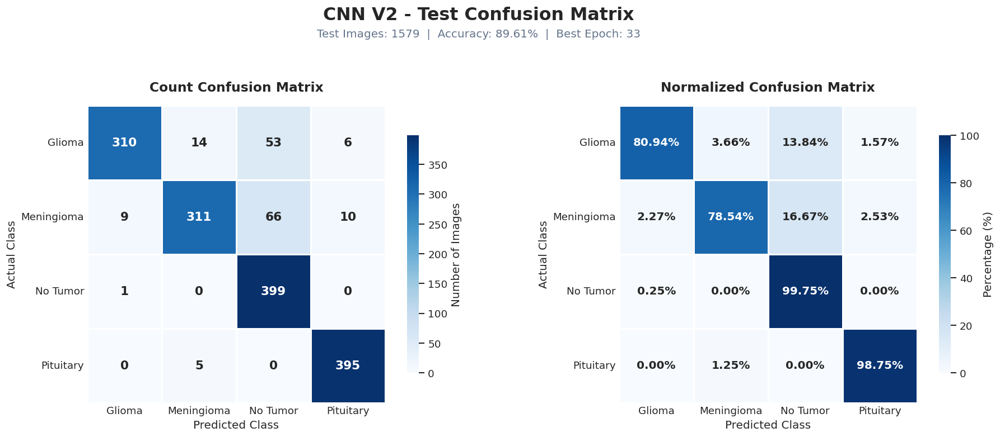

Confusion Matrix grafiği kaydedildi.
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/07_confusion_matrix.png


In [ ]:
# ==================================================
# 16.2. CONFUSION MATRIX GÖRSELLEŞTİRME
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6.5)
)

# --------------------------------------------------
# 1. COUNT CONFUSION MATRIX
# --------------------------------------------------

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.8,
    linecolor="white",
    square=True,
    vmin=0,
    cbar=True,
    annot_kws={
        "size": 13,
        "weight": "bold"
    },
    cbar_kws={
        "label": "Number of Images",
        "shrink": 0.80
    },
    ax=axes[0]
)

axes[0].set_title(
    "Count Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# --------------------------------------------------
# 2. NORMALIZED CONFUSION MATRIX
# --------------------------------------------------

normalized_labels = np.array([
    [f"{value:.2f}%" for value in row]
    for row in cm_normalized
])

sns.heatmap(
    cm_normalized,
    annot=normalized_labels,
    fmt="",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.8,
    linecolor="white",
    square=True,
    vmin=0,
    vmax=100,
    cbar=True,
    annot_kws={
        "size": 12,
        "weight": "bold"
    },
    cbar_kws={
        "label": "Percentage (%)",
        "shrink": 0.80
    },
    ax=axes[1]
)

axes[1].set_title(
    "Normalized Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

# --------------------------------------------------
# ORTAK GRAFİK AYARLARI
# --------------------------------------------------

for ax in axes:

    ax.tick_params(axis="both", length=0)

    plt.setp(
        ax.get_xticklabels(),
        rotation=0,
        ha="center"
    )

    plt.setp(
        ax.get_yticklabels(),
        rotation=0
    )

fig.suptitle(
    "CNN V2 - Test Confusion Matrix",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.91,
    f"Test Images: {len(y_true)}  |  "
    f"Accuracy: {test_metrics['accuracy'] * 100:.2f}%  |  "
    f"Best Epoch: {BEST_EPOCH}",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(
    rect=[0, 0.02, 1, 0.86]
)

# --------------------------------------------------
# GRAFİĞİ DRIVE'A KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "07_confusion_matrix.png"
)

print("Confusion Matrix grafiği kaydedildi.")

print(
    sonuc_klasoru / "07_confusion_matrix.png"
)

In [ ]:
# ==================================================
# 16.3. YANLIŞ SINIFLANDIRMALARIN ANALİZİ
# ==================================================

error_records = []

# --------------------------------------------------
# 1. YANLIŞ SINIFLANDIRMALARI BELİRLEME
# --------------------------------------------------

for i, actual_class in enumerate(CLASS_NAMES):

    class_total = cm[i].sum()

    for j, predicted_class in enumerate(CLASS_NAMES):

        # Köşegen dışındaki değerler hatalı tahminlerdir
        if i != j and cm[i, j] > 0:

            error_count = int(cm[i, j])

            error_records.append({

                "Actual_Class": actual_class,

                "Predicted_Class": predicted_class,

                "Error_Count": error_count,

                "Class_Error_Rate (%)":
                    (error_count / class_total) * 100,

                "Share_of_All_Errors (%)":
                    (error_count / incorrect_predictions) * 100
            })

# --------------------------------------------------
# 2. HATALARI DATAFRAME'E DÖNÜŞTÜRME
# --------------------------------------------------

error_df = pd.DataFrame(error_records)

error_df = error_df.sort_values(
    by="Error_Count",
    ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 3. SINIF BAZLI PERFORMANS ÖZETİ
# --------------------------------------------------

class_summary_records = []

for i, class_name in enumerate(CLASS_NAMES):

    total_images = int(cm[i].sum())

    correct_count = int(cm[i, i])

    incorrect_count = total_images - correct_count

    recall_value = (
        correct_count / total_images
    ) * 100

    class_summary_records.append({

        "Class": class_name,

        "Test_Images": total_images,

        "Correct_Predictions": correct_count,

        "Incorrect_Predictions": incorrect_count,

        "Recall (%)": recall_value
    })

class_summary_df = pd.DataFrame(
    class_summary_records
)

# --------------------------------------------------
# 4. SONUÇLARIN KONTROLÜ
# --------------------------------------------------

assert error_df["Error_Count"].sum() == incorrect_predictions

assert (
    class_summary_df["Test_Images"].sum()
    == len(y_true)
)

assert (
    class_summary_df["Correct_Predictions"].sum()
    == correct_predictions
)

assert np.isclose(
    error_df["Share_of_All_Errors (%)"].sum(),
    100
)

# --------------------------------------------------
# 5. SONUÇLARI GÖSTERME
# --------------------------------------------------

print("=" * 70)
print("CNN V2 - MISCLASSIFICATION ANALYSIS")
print("=" * 70)

print("\nYanlış Sınıflandırma Türleri:\n")

display(error_df.round(2))

print("\nSınıf Bazlı Tahmin Özeti:\n")

display(class_summary_df.round(2))

print("\nToplam yanlış tahmin:", incorrect_predictions)

print(
    "Farklı hata türü sayısı:",
    len(error_df)
)

# --------------------------------------------------
# 6. SONUÇLARI DRIVE'A KAYDETME
# --------------------------------------------------

error_df.to_csv(
    sonuc_klasoru / "misclassification_analysis.csv",
    index=False
)

class_summary_df.to_csv(
    sonuc_klasoru / "class_prediction_summary.csv",
    index=False
)

print("\nAnaliz dosyaları başarıyla kaydedildi.")

print("Veri kontrolleri başarılı.")

CNN V2 - MISCLASSIFICATION ANALYSIS

Yanlış Sınıflandırma Türleri:



,Actual_Class,Predicted_Class,Error_Count,Class_Error_Rate (%),Share_of_All_Errors (%)
0,Meningioma,No Tumor,66,16.67,40.24
1,Glioma,No Tumor,53,13.84,32.32
2,Glioma,Meningioma,14,3.66,8.54
3,Meningioma,Pituitary,10,2.53,6.10
4,Meningioma,Glioma,9,2.27,5.49
5,Glioma,Pituitary,6,1.57,3.66
6,Pituitary,Meningioma,5,1.25,3.05
7,No Tumor,Glioma,1,0.25,0.61



Sınıf Bazlı Tahmin Özeti:



,Class,Test_Images,Correct_Predictions,Incorrect_Predictions,Recall (%)
0,Glioma,383,310,73,80.94
1,Meningioma,396,311,85,78.54
2,No Tumor,400,399,1,99.75
3,Pituitary,400,395,5,98.75



Toplam yanlış tahmin: 164
Farklı hata türü sayısı: 8

Analiz dosyaları başarıyla kaydedildi.
Veri kontrolleri başarılı.


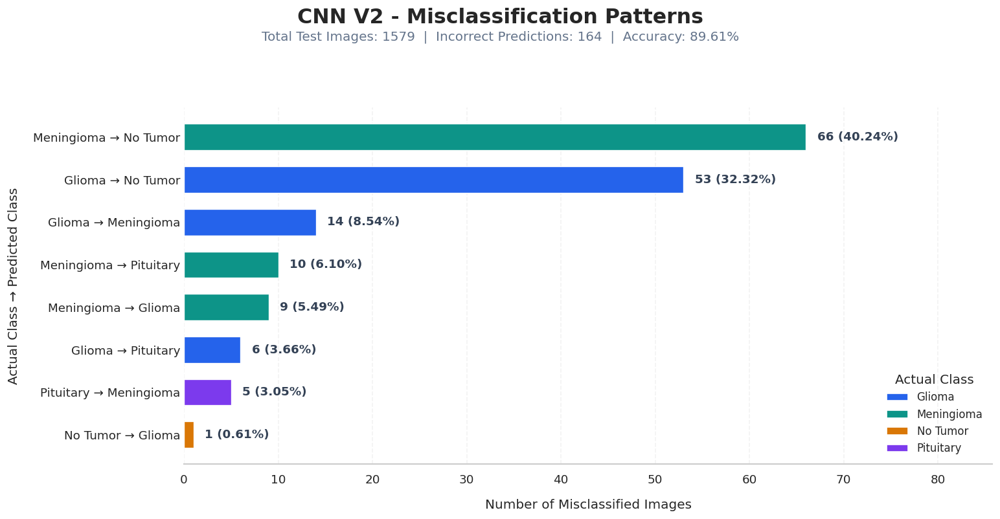

Yanlış sınıflandırma grafiği kaydedildi.
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/08_misclassification_patterns.png


In [ ]:
# ==================================================
# 16.4. YANLIŞ SINIFLANDIRMALARIN GÖRSELLEŞTİRİLMESİ
# ==================================================

# --------------------------------------------------
# 1. GRAFİK VERİLERİNİ HAZIRLAMA
# --------------------------------------------------

plot_df = error_df.copy()

plot_df["Error_Type"] = (
    plot_df["Actual_Class"]
    + " → "
    + plot_df["Predicted_Class"]
)

plot_df = plot_df.sort_values(
    by="Error_Count",
    ascending=True
).reset_index(drop=True)

# Sınıflara ait renkler
class_colors = {
    "Glioma": "#2563EB",
    "Meningioma": "#0D9488",
    "No Tumor": "#D97706",
    "Pituitary": "#7C3AED"
}

bar_colors = plot_df["Actual_Class"].map(
    class_colors
)

# --------------------------------------------------
# 2. YATAY SÜTUN GRAFİĞİ
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    plot_df["Error_Type"],
    plot_df["Error_Count"],
    color=bar_colors,
    height=0.62,
    edgecolor="white",
    linewidth=0.8
)

# --------------------------------------------------
# 3. SÜTUN ETİKETLERİ
# --------------------------------------------------

for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):

    error_count = row["Error_Count"]

    error_percentage = row["Share_of_All_Errors (%)"]

    ax.text(
        bar.get_width() + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{error_count} ({error_percentage:.2f}%)",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color="#334155"
    )

# --------------------------------------------------
# 4. GRAFİK AYARLARI
# --------------------------------------------------

ax.set_xlabel(
    "Number of Misclassified Images",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Actual Class → Predicted Class",
    fontsize=12,
    labelpad=12
)

ax.set_xlim(
    0,
    plot_df["Error_Count"].max() * 1.30
)

ax.set_axisbelow(True)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.grid(
    axis="y",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=11
)

# --------------------------------------------------
# 5. RENK AÇIKLAMALARI
# --------------------------------------------------

from matplotlib.patches import Patch

legend_elements = [

    Patch(
        facecolor=color,
        label=class_name
    )

    for class_name, color in class_colors.items()
]

ax.legend(
    handles=legend_elements,
    title="Actual Class",
    loc="lower right",
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# 6. BAŞLIK VE ALT BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Misclassification Patterns",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    f"Total Test Images: {len(y_true)}  |  "
    f"Incorrect Predictions: {incorrect_predictions}  |  "
    f"Accuracy: {test_metrics['accuracy'] * 100:.2f}%",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(
    rect=[0, 0.02, 1, 0.87]
)

# --------------------------------------------------
# 7. GRAFİĞİ KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "08_misclassification_patterns.png"
)

print("Yanlış sınıflandırma grafiği kaydedildi.")

print(
    sonuc_klasoru / "08_misclassification_patterns.png"
)

In [ ]:
# ==================================================
# 17.1. SINIF BAZLI PERFORMANS METRİKLERİ
# ==================================================

from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report
)

# --------------------------------------------------
# 1. TEMEL SINIF METRİKLERİ
# --------------------------------------------------

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        average=None,
        zero_division=0
    )
)

# --------------------------------------------------
# 2. SPECIFICITY VE SINIF BAZLI HATALAR
# --------------------------------------------------

class_metric_records = []

total_samples = cm.sum()

for i, class_name in enumerate(CLASS_NAMES):

    # True Positive
    tp = int(cm[i, i])

    # False Positive
    fp = int(cm[:, i].sum() - tp)

    # False Negative
    fn = int(cm[i, :].sum() - tp)

    # True Negative
    tn = int(total_samples - tp - fp - fn)

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else 0
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0
    )

    class_metric_records.append({

        "Class": class_name,

        "Precision (%)": precision[i] * 100,

        "Recall (%)": recall[i] * 100,

        "F1-Score (%)": f1[i] * 100,

        "Specificity (%)": specificity * 100,

        "False Positive Rate (%)":
            false_positive_rate * 100,

        "False Negative Rate (%)":
            false_negative_rate * 100,

        "Support": int(support[i]),

        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

class_metrics_df = pd.DataFrame(
    class_metric_records
)

# --------------------------------------------------
# 3. MACRO VE WEIGHTED ORTALAMALAR
# --------------------------------------------------

average_records = []

for average_type in ["macro", "weighted"]:

    p, r, f, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        average=average_type,
        zero_division=0
    )

    average_records.append({

        "Average": average_type.capitalize(),

        "Precision (%)": p * 100,

        "Recall (%)": r * 100,

        "F1-Score (%)": f * 100
    })

average_metrics_df = pd.DataFrame(
    average_records
)

# --------------------------------------------------
# 4. VERİ TUTARLILIĞINI KONTROL ETME
# --------------------------------------------------

assert class_metrics_df["Support"].sum() == len(y_true)

assert class_metrics_df["TP"].sum() == correct_predictions

assert class_metrics_df["FN"].sum() == incorrect_predictions

assert class_metrics_df["FP"].sum() == incorrect_predictions

assert np.isclose(
    precision.mean(),
    test_metrics["precision"]
)

assert np.isclose(
    recall.mean(),
    test_metrics["recall"]
)

assert np.isclose(
    f1.mean(),
    test_metrics["f1"]
)

# --------------------------------------------------
# 5. SONUÇLARI GÖSTERME
# --------------------------------------------------

print("=" * 75)
print("CNN V2 - CLASS-WISE PERFORMANCE ANALYSIS")
print("=" * 75)

print("\nSınıf Bazlı Performans Metrikleri:\n")

display(
    class_metrics_df[[
        "Class",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)",
        "Specificity (%)",
        "Support"
    ]].round(2)
)

print("\nSınıf Bazlı Hata Metrikleri:\n")

display(
    class_metrics_df[[
        "Class",
        "TP",
        "FP",
        "FN",
        "TN",
        "False Positive Rate (%)",
        "False Negative Rate (%)"
    ]].round(2)
)

print("\nOrtalama Performans Metrikleri:\n")

display(average_metrics_df.round(2))

# --------------------------------------------------
# 6. CLASSIFICATION REPORT
# --------------------------------------------------

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("\nSklearn Classification Report:\n")

print(report_text)

# --------------------------------------------------
# 7. SONUÇLARI DRIVE'A KAYDETME
# --------------------------------------------------

class_metrics_df.to_csv(
    sonuc_klasoru / "class_performance_metrics.csv",
    index=False
)

average_metrics_df.to_csv(
    sonuc_klasoru / "average_performance_metrics.csv",
    index=False
)

with open(
    sonuc_klasoru / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(report_text)

print("\nPerformans metrikleri başarıyla kaydedildi.")

print("Tüm veri kontrolleri başarılı.")

CNN V2 - CLASS-WISE PERFORMANCE ANALYSIS

Sınıf Bazlı Performans Metrikleri:



,Class,Precision (%),Recall (%),F1-Score (%),Specificity (%),Support
0,Glioma,96.88,80.94,88.19,99.16,383
1,Meningioma,94.24,78.54,85.67,98.39,396
2,No Tumor,77.03,99.75,86.93,89.91,400
3,Pituitary,96.11,98.75,97.41,98.64,400



Sınıf Bazlı Hata Metrikleri:



,Class,TP,FP,FN,TN,False Positive Rate (%),False Negative Rate (%)
0,Glioma,310,10,73,1186,0.84,19.06
1,Meningioma,311,19,85,1164,1.61,21.46
2,No Tumor,399,119,1,1060,10.09,0.25
3,Pituitary,395,16,5,1163,1.36,1.25



Ortalama Performans Metrikleri:



,Average,Precision (%),Recall (%),F1-Score (%)
0,Macro,91.06,89.49,89.55
1,Weighted,90.99,89.61,89.58



Sklearn Classification Report:

              precision    recall  f1-score   support

      Glioma     0.9688    0.8094    0.8819       383
  Meningioma     0.9424    0.7854    0.8567       396
    No Tumor     0.7703    0.9975    0.8693       400
   Pituitary     0.9611    0.9875    0.9741       400

    accuracy                         0.8961      1579
   macro avg     0.9106    0.8949    0.8955      1579
weighted avg     0.9099    0.8961    0.8958      1579


Performans metrikleri başarıyla kaydedildi.
Tüm veri kontrolleri başarılı.


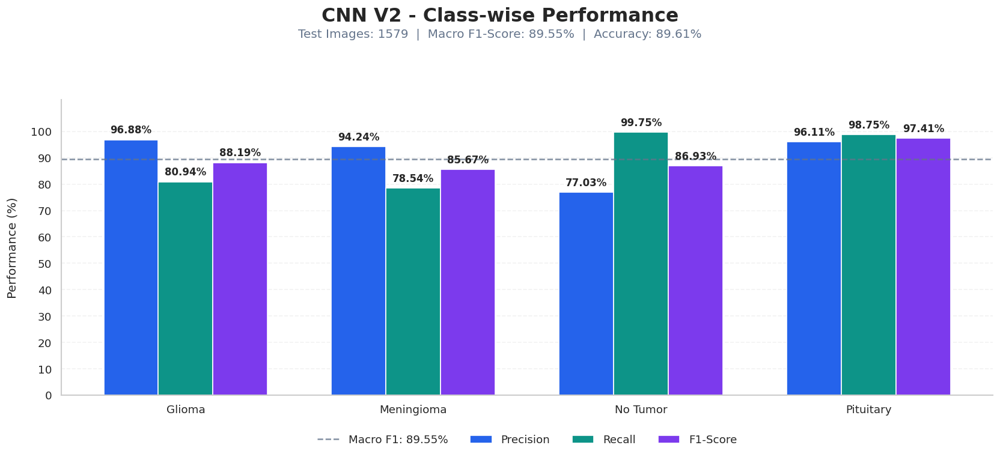

Sınıf bazlı performans grafiği kaydedildi.


In [ ]:
# ==================================================
# 17.2. SINIF BAZLI PERFORMANS GRAFİĞİ
# ==================================================

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(CLASS_NAMES))
width = 0.24

metrics = [
    ("Precision (%)", "Precision", "#2563EB"),
    ("Recall (%)", "Recall", "#0D9488"),
    ("F1-Score (%)", "F1-Score", "#7C3AED")
]

# --------------------------------------------------
# 1. SÜTUNLARI OLUŞTURMA
# --------------------------------------------------

for i, (column, label, color) in enumerate(metrics):

    bars = ax.bar(
        x + (i - 1) * width,
        class_metrics_df[column],
        width=width,
        label=label,
        color=color,
        edgecolor="white"
    )

    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

# --------------------------------------------------
# 2. MACRO F1 REFERANS ÇİZGİSİ
# --------------------------------------------------

macro_f1 = test_metrics["f1"] * 100

ax.axhline(
    macro_f1,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=f"Macro F1: {macro_f1:.2f}%"
)

# --------------------------------------------------
# 3. GRAFİK AYARLARI
# --------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)

ax.set_xlabel("")
ax.set_ylabel("Performance (%)", labelpad=12)

ax.set_ylim(0, 112)
ax.set_yticks(np.arange(0, 101, 10))

ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.grid(axis="x", visible=False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False
)

fig.suptitle(
    "CNN V2 - Class-wise Performance",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    f"Test Images: {len(y_true)}  |  "
    f"Macro F1-Score: {macro_f1:.2f}%  |  "
    f"Accuracy: {test_metrics['accuracy'] * 100:.2f}%",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.87])

grafik_kaydet(
    fig,
    "09_class_performance_metrics.png"
)

print("Sınıf bazlı performans grafiği kaydedildi.")

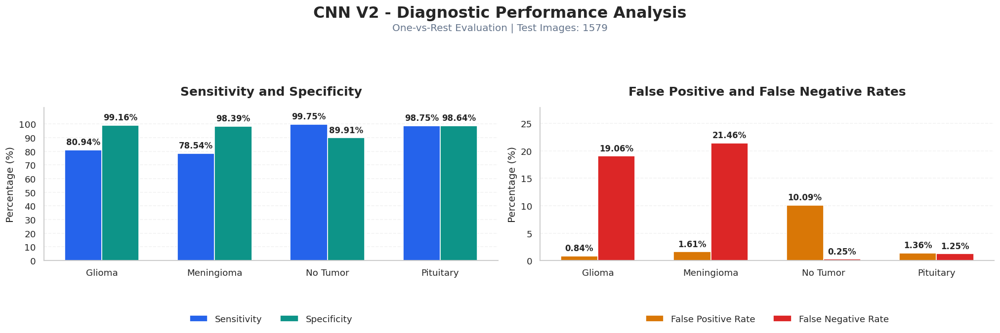

Sensitivity ve Specificity grafiği kaydedildi.


In [ ]:
# ==================================================
# 17.3. SENSITIVITY VE SPECIFICITY ANALİZİ
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7)
)

x = np.arange(len(CLASS_NAMES))
width = 0.33

# --------------------------------------------------
# 1. SENSITIVITY VE SPECIFICITY
# --------------------------------------------------

bars1 = axes[0].bar(
    x - width / 2,
    class_metrics_df["Recall (%)"],
    width,
    label="Sensitivity",
    color="#2563EB"
)

bars2 = axes[0].bar(
    x + width / 2,
    class_metrics_df["Specificity (%)"],
    width,
    label="Specificity",
    color="#0D9488"
)

for bars in [bars1, bars2]:

    axes[0].bar_label(
        bars,
        fmt="%.2f%%",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title(
    "Sensitivity and Specificity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

axes[0].set_ylim(0, 112)
axes[0].set_yticks(np.arange(0, 101, 10))

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=2,
    frameon=False
)

# --------------------------------------------------
# 2. FALSE POSITIVE VE FALSE NEGATIVE RATES
# --------------------------------------------------

bars3 = axes[1].bar(
    x - width / 2,
    class_metrics_df["False Positive Rate (%)"],
    width,
    label="False Positive Rate",
    color="#D97706"
)

bars4 = axes[1].bar(
    x + width / 2,
    class_metrics_df["False Negative Rate (%)"],
    width,
    label="False Negative Rate",
    color="#DC2626"
)

for bars in [bars3, bars4]:

    axes[1].bar_label(
        bars,
        fmt="%.2f%%",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "False Positive and False Negative Rates",
    fontsize=15,
    fontweight="bold",
    pad=15
)

max_error = max(
    class_metrics_df["False Positive Rate (%)"].max(),
    class_metrics_df["False Negative Rate (%)"].max()
)

axes[1].set_ylim(0, max_error * 1.30)

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=2,
    frameon=False
)

# --------------------------------------------------
# 3. ORTAK GRAFİK AYARLARI
# --------------------------------------------------

for ax in axes:

    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_NAMES)

    ax.set_xlabel("")
    ax.set_ylabel("Percentage (%)")

    ax.set_axisbelow(True)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.grid(axis="x", visible=False)

fig.suptitle(
    "CNN V2 - Diagnostic Performance Analysis",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    "One-vs-Rest Evaluation | "
    f"Test Images: {len(y_true)}",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.86])

grafik_kaydet(
    fig,
    "10_sensitivity_specificity_analysis.png"
)

print("Sensitivity ve Specificity grafiği kaydedildi.")

CNN V2 - BINARY TUMOR DETECTION


,No Tumor,Tumor
No Tumor,399,1
Tumor,119,1060



Binary Performance Metrics:



,0
Accuracy (%),92.40
Precision (%),99.91
Sensitivity (%),89.91
Specificity (%),99.75
F1-Score (%),94.64
False Negative Rate (%),10.09
False Positive Rate (%),0.25
True Positive,1060.00
True Negative,399.00
False Positive,1.00


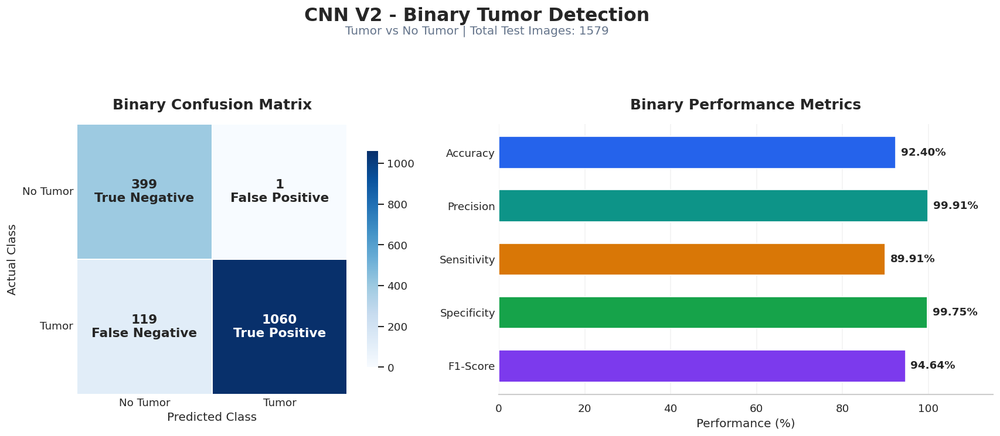


Binary analiz sonuçları kaydedildi.
Veri kontrolleri başarılı.


In [ ]:
# ==================================================
# 17.4. BINARY TUMOR DETECTION ANALYSIS
# ==================================================

# --------------------------------------------------
# 1. DÖRT SINIFI İKİ SINIFA DÖNÜŞTÜRME
# --------------------------------------------------

# 0 = No Tumor
# 1 = Tumor

no_tumor_index = 2

y_true_binary = (
    y_true != no_tumor_index
).astype(int)

y_pred_binary = (
    y_pred != no_tumor_index
).astype(int)

# --------------------------------------------------
# 2. BINARY CONFUSION MATRIX
# --------------------------------------------------

binary_cm = confusion_matrix(
    y_true_binary,
    y_pred_binary,
    labels=[0, 1]
)

tn, fp, fn, tp = binary_cm.ravel()

# --------------------------------------------------
# 3. BINARY PERFORMANS METRİKLERİ
# --------------------------------------------------

binary_metrics = {

    "Accuracy (%)":
        accuracy_score(
            y_true_binary,
            y_pred_binary
        ) * 100,

    "Precision (%)":
        precision_score(
            y_true_binary,
            y_pred_binary,
            zero_division=0
        ) * 100,

    "Sensitivity (%)":
        recall_score(
            y_true_binary,
            y_pred_binary,
            zero_division=0
        ) * 100,

    "Specificity (%)":
        tn / (tn + fp) * 100,

    "F1-Score (%)":
        f1_score(
            y_true_binary,
            y_pred_binary,
            zero_division=0
        ) * 100,

    "False Negative Rate (%)":
        fn / (fn + tp) * 100,

    "False Positive Rate (%)":
        fp / (fp + tn) * 100,

    "True Positive": int(tp),
    "True Negative": int(tn),
    "False Positive": int(fp),
    "False Negative": int(fn)
}

binary_metrics_df = pd.DataFrame(
    [binary_metrics]
)

# --------------------------------------------------
# 4. VERİ KONTROLLERİ
# --------------------------------------------------

assert binary_cm.sum() == len(y_true)

assert tp + tn + fp + fn == len(y_true)

# --------------------------------------------------
# 5. SONUÇLARI GÖSTERME
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - BINARY TUMOR DETECTION")
print("=" * 65)

binary_cm_df = pd.DataFrame(
    binary_cm,
    index=["No Tumor", "Tumor"],
    columns=["No Tumor", "Tumor"]
)

display(binary_cm_df)

print("\nBinary Performance Metrics:\n")

display(binary_metrics_df.T.round(2))

# --------------------------------------------------
# 6. GÖRSELLEŞTİRME
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6.5),
    gridspec_kw={"width_ratios": [1, 1.25]}
)

binary_labels = np.array([

    [f"{tn}\nTrue Negative",
     f"{fp}\nFalse Positive"],

    [f"{fn}\nFalse Negative",
     f"{tp}\nTrue Positive"]
])

sns.heatmap(
    binary_cm,
    annot=binary_labels,
    fmt="",
    cmap="Blues",
    square=True,
    vmin=0,
    linewidths=1,
    linecolor="white",
    xticklabels=["No Tumor", "Tumor"],
    yticklabels=["No Tumor", "Tumor"],
    annot_kws={
        "size": 13,
        "weight": "bold"
    },
    cbar_kws={"shrink": 0.8},
    ax=axes[0]
)

axes[0].set_title(
    "Binary Confusion Matrix",
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

axes[0].tick_params(axis="both", length=0)

plt.setp(
    axes[0].get_yticklabels(),
    rotation=0
)

# Performans grafiği

metric_names = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-Score"
]

metric_values = [

    binary_metrics["Accuracy (%)"],
    binary_metrics["Precision (%)"],
    binary_metrics["Sensitivity (%)"],
    binary_metrics["Specificity (%)"],
    binary_metrics["F1-Score (%)"]
]

metric_colors = [
    "#2563EB",
    "#0D9488",
    "#D97706",
    "#16A34A",
    "#7C3AED"
]

bars = axes[1].barh(
    metric_names,
    metric_values,
    color=metric_colors,
    height=0.6
)

axes[1].invert_yaxis()

axes[1].bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=11,
    fontweight="bold"
)

axes[1].set_xlim(0, 115)
axes[1].set_xticks(np.arange(0, 101, 20))

axes[1].set_xlabel("Performance (%)")

axes[1].set_title(
    "Binary Performance Metrics",
    fontweight="bold",
    pad=15
)

axes[1].set_axisbelow(True)
axes[1].grid(axis="x", alpha=0.25)
axes[1].grid(axis="y", visible=False)

axes[1].spines["left"].set_visible(False)
axes[1].tick_params(axis="y", length=0)

fig.suptitle(
    "CNN V2 - Binary Tumor Detection",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    "Tumor vs No Tumor | "
    f"Total Test Images: {len(y_true)}",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.86])

grafik_kaydet(
    fig,
    "11_binary_tumor_detection.png"
)

# --------------------------------------------------
# 7. SONUÇLARI DRIVE'A KAYDETME
# --------------------------------------------------

binary_metrics_df.to_csv(
    sonuc_klasoru / "binary_tumor_detection_metrics.csv",
    index=False
)

binary_cm_df.to_csv(
    sonuc_klasoru / "binary_confusion_matrix.csv"
)

print("\nBinary analiz sonuçları kaydedildi.")
print("Veri kontrolleri başarılı.")

In [ ]:
# ==================================================
# 17.5. PERFORMANS ANALİZİ DOSYA KONTROLÜ
# ==================================================

step17_files = [

    "class_performance_metrics.csv",
    "average_performance_metrics.csv",
    "classification_report.txt",

    "09_class_performance_metrics.png",
    "10_sensitivity_specificity_analysis.png",

    "11_binary_tumor_detection.png",
    "binary_tumor_detection_metrics.csv",
    "binary_confusion_matrix.csv"
]

print("=" * 65)
print("17. ADIM - DOSYA KONTROLÜ")
print("=" * 65)

for filename in step17_files:

    file_path = sonuc_klasoru / filename

    if file_path.exists():

        size_kb = file_path.stat().st_size / 1024

        print(
            f"HAZIR | {filename} | "
            f"{size_kb:.2f} KB"
        )

    else:

        print(f"EKSİK | {filename}")

all_saved = all(
    (sonuc_klasoru / filename).exists()
    for filename in step17_files
)

print("\n" + "=" * 65)

if all_saved:

    print("17. ADIM BAŞARIYLA TAMAMLANDI.")

else:

    print("Eksik dosyalar bulunuyor.")

17. ADIM - DOSYA KONTROLÜ
HAZIR | class_performance_metrics.csv | 0.60 KB
HAZIR | average_performance_metrics.csv | 0.16 KB
HAZIR | classification_report.txt | 0.42 KB
HAZIR | 09_class_performance_metrics.png | 238.53 KB
HAZIR | 10_sensitivity_specificity_analysis.png | 298.64 KB
HAZIR | 11_binary_tumor_detection.png | 268.10 KB
HAZIR | binary_tumor_detection_metrics.csv | 0.29 KB
HAZIR | binary_confusion_matrix.csv | 0.04 KB

17. ADIM BAŞARIYLA TAMAMLANDI.


In [ ]:
# ==================================================
# 18.1. ROC-AUC HESAPLAMA
# ==================================================

from sklearn.preprocessing import label_binarize

from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# --------------------------------------------------
# 1. SINIF VE RENK TANIMLARI
# --------------------------------------------------

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

class_colors = {
    "Glioma": "#2563EB",
    "Meningioma": "#0D9488",
    "No Tumor": "#D97706",
    "Pituitary": "#7C3AED"
}

# --------------------------------------------------
# 2. OLASILIK KONTROLLERİ
# --------------------------------------------------

assert y_prob.shape == (len(y_true), 4)

assert np.isfinite(y_prob).all()

assert np.all(
    (y_prob >= 0) & (y_prob <= 1)
)

assert np.allclose(
    y_prob.sum(axis=1),
    1,
    atol=1e-5
)

# --------------------------------------------------
# 3. ONE-VS-REST ETİKETLERİ
# --------------------------------------------------

y_true_bin = label_binarize(
    y_true,
    classes=[0, 1, 2, 3]
)

# --------------------------------------------------
# 4. SINIF BAZLI ROC EĞRİLERİ
# --------------------------------------------------

fpr = {}
tpr = {}
roc_thresholds = {}
roc_auc = {}

for i in range(4):

    fpr[i], tpr[i], roc_thresholds[i] = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# --------------------------------------------------
# 5. MICRO AVERAGE ROC
# --------------------------------------------------

fpr["micro"], tpr["micro"], _ = roc_curve(
    y_true_bin.ravel(),
    y_prob.ravel()
)

roc_auc["micro"] = auc(
    fpr["micro"],
    tpr["micro"]
)

# --------------------------------------------------
# 6. MACRO AVERAGE ROC
# --------------------------------------------------

all_fpr = np.unique(
    np.concatenate([
        fpr[i] for i in range(4)
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(4):

    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= 4

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr

roc_auc["macro"] = np.mean([
    roc_auc[i] for i in range(4)
])

# --------------------------------------------------
# 7. WEIGHTED AUC
# --------------------------------------------------

roc_auc["weighted"] = roc_auc_score(
    y_true_bin,
    y_prob,
    average="weighted"
)

# --------------------------------------------------
# 8. SONUÇ TABLOLARI
# --------------------------------------------------

roc_auc_df = pd.DataFrame({

    "Class": CLASS_NAMES,

    "ROC_AUC": [
        roc_auc[i] for i in range(4)
    ],

    "ROC_AUC (%)": [
        roc_auc[i] * 100
        for i in range(4)
    ]
})

roc_average_df = pd.DataFrame({

    "Average": [
        "Macro",
        "Micro",
        "Weighted"
    ],

    "ROC_AUC": [
        roc_auc["macro"],
        roc_auc["micro"],
        roc_auc["weighted"]
    ]
})

# --------------------------------------------------
# 9. VERİ KONTROLLERİ
# --------------------------------------------------

assert all(
    0 <= value <= 1
    for value in roc_auc.values()
)

assert np.isclose(
    roc_auc["macro"],
    roc_auc_score(
        y_true_bin,
        y_prob,
        average="macro"
    )
)

# --------------------------------------------------
# 10. SONUÇLARI GÖSTERME
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - ROC-AUC ANALYSIS")
print("=" * 65)

print("\nClass-wise ROC-AUC:\n")

display(roc_auc_df.round(4))

print("\nAverage ROC-AUC:\n")

display(roc_average_df.round(4))

# --------------------------------------------------
# 11. DRIVE'A KAYDETME
# --------------------------------------------------

roc_auc_df.to_csv(
    sonuc_klasoru / "roc_auc_class_metrics.csv",
    index=False
)

roc_average_df.to_csv(
    sonuc_klasoru / "roc_auc_average_metrics.csv",
    index=False
)

print("\nROC-AUC sonuçları kaydedildi.")
print("Veri kontrolleri başarılı.")

CNN V2 - ROC-AUC ANALYSIS

Class-wise ROC-AUC:



,Class,ROC_AUC,ROC_AUC (%)
0,Glioma,0.9277,92.7738
1,Meningioma,0.9618,96.1797
2,No Tumor,0.9830,98.3026
3,Pituitary,0.9984,99.8427



Average ROC-AUC:



,Average,ROC_AUC
0,Macro,0.9677
1,Micro,0.9696
2,Weighted,0.9682



ROC-AUC sonuçları kaydedildi.
Veri kontrolleri başarılı.


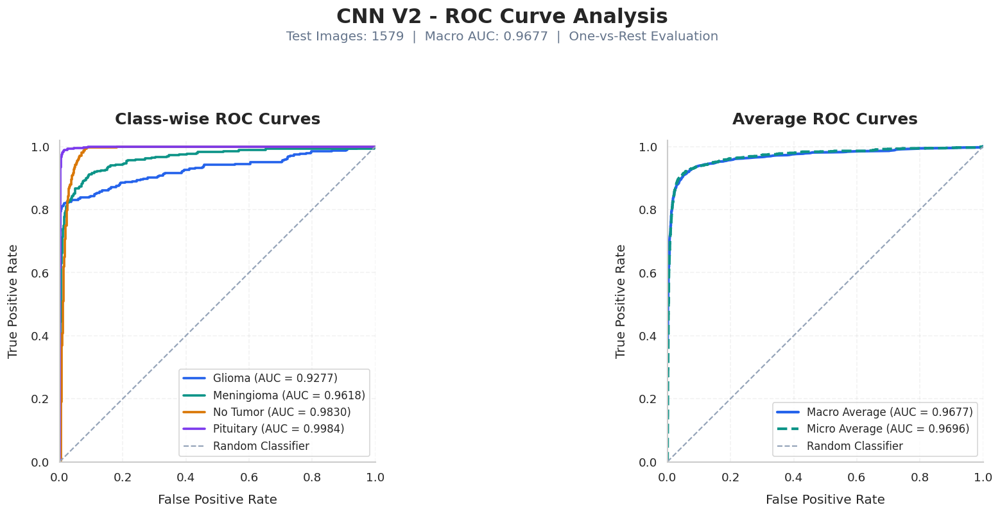

ROC eğrileri başarıyla kaydedildi.


In [ ]:
# ==================================================
# 18.2. ROC CURVE GÖRSELLEŞTİRME
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# --------------------------------------------------
# 1. SINIF BAZLI ROC EĞRİLERİ
# --------------------------------------------------

for i, class_name in enumerate(CLASS_NAMES):

    axes[0].plot(
        fpr[i],
        tpr[i],
        color=class_colors[class_name],
        linewidth=2.2,
        label=(
            f"{class_name} "
            f"(AUC = {roc_auc[i]:.4f})"
        )
    )

axes[0].set_title(
    "Class-wise ROC Curves",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# --------------------------------------------------
# 2. MACRO VE MICRO ROC EĞRİLERİ
# --------------------------------------------------

axes[1].plot(
    fpr["macro"],
    tpr["macro"],
    color="#2563EB",
    linewidth=2.5,
    label=(
        "Macro Average "
        f"(AUC = {roc_auc['macro']:.4f})"
    )
)

axes[1].plot(
    fpr["micro"],
    tpr["micro"],
    color="#0D9488",
    linewidth=2.5,
    linestyle="--",
    label=(
        "Micro Average "
        f"(AUC = {roc_auc['micro']:.4f})"
    )
)

axes[1].set_title(
    "Average ROC Curves",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# --------------------------------------------------
# 3. ORTAK GRAFİK AYARLARI
# --------------------------------------------------

for ax in axes:

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="#94A3B8",
        linewidth=1.3,
        label="Random Classifier"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.set_xticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_yticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_xlabel(
        "False Positive Rate",
        labelpad=10
    )

    ax.set_ylabel(
        "True Positive Rate",
        labelpad=10
    )

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

    ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=10,
        facecolor="white"
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

# --------------------------------------------------
# 4. BAŞLIK VE ALT BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - ROC Curve Analysis",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    f"Test Images: {len(y_true)}  |  "
    f"Macro AUC: {roc_auc['macro']:.4f}  |  "
    "One-vs-Rest Evaluation",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(
    rect=[0, 0.02, 1, 0.86]
)

# --------------------------------------------------
# 5. GRAFİĞİ KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "12_roc_curve_analysis.png"
)

print("ROC eğrileri başarıyla kaydedildi.")

In [ ]:
# ==================================================
# 18.3. PRECISION-RECALL VE AVERAGE PRECISION
# ==================================================

pr_precision = {}
pr_recall = {}
pr_thresholds = {}
average_precision = {}

pr_records = []

# --------------------------------------------------
# 1. SINIF BAZLI PR EĞRİLERİ
# --------------------------------------------------

for i, class_name in enumerate(CLASS_NAMES):

    (
        pr_precision[i],
        pr_recall[i],
        pr_thresholds[i]
    ) = precision_recall_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    average_precision[i] = average_precision_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    prevalence = y_true_bin[:, i].mean()

    pr_records.append({

        "Class": class_name,

        "Average_Precision":
            average_precision[i],

        "Average_Precision (%)":
            average_precision[i] * 100,

        "Positive_Prevalence (%)":
            prevalence * 100
    })

# --------------------------------------------------
# 2. MICRO AVERAGE PR
# --------------------------------------------------

(
    pr_precision["micro"],
    pr_recall["micro"],
    _
) = precision_recall_curve(
    y_true_bin.ravel(),
    y_prob.ravel()
)

average_precision["micro"] = average_precision_score(
    y_true_bin,
    y_prob,
    average="micro"
)

# --------------------------------------------------
# 3. MACRO VE WEIGHTED AP
# --------------------------------------------------

average_precision["macro"] = average_precision_score(
    y_true_bin,
    y_prob,
    average="macro"
)

average_precision["weighted"] = average_precision_score(
    y_true_bin,
    y_prob,
    average="weighted"
)

# --------------------------------------------------
# 4. SONUÇ TABLOLARI
# --------------------------------------------------

pr_metrics_df = pd.DataFrame(pr_records)

pr_average_df = pd.DataFrame({

    "Average": [
        "Macro",
        "Micro",
        "Weighted"
    ],

    "Average_Precision": [
        average_precision["macro"],
        average_precision["micro"],
        average_precision["weighted"]
    ]
})

# --------------------------------------------------
# 5. VERİ KONTROLLERİ
# --------------------------------------------------

assert all(
    0 <= value <= 1
    for value in average_precision.values()
)

assert np.isclose(
    average_precision["macro"],
    np.mean([
        average_precision[i]
        for i in range(4)
    ])
)

# --------------------------------------------------
# 6. SONUÇLARI GÖSTERME
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - PRECISION-RECALL ANALYSIS")
print("=" * 65)

print("\nClass-wise Average Precision:\n")

display(pr_metrics_df.round(4))

print("\nAverage Precision Summary:\n")

display(pr_average_df.round(4))

# --------------------------------------------------
# 7. DRIVE'A KAYDETME
# --------------------------------------------------

pr_metrics_df.to_csv(
    sonuc_klasoru / "average_precision_class_metrics.csv",
    index=False
)

pr_average_df.to_csv(
    sonuc_klasoru / "average_precision_summary.csv",
    index=False
)

print("\nAverage Precision sonuçları kaydedildi.")
print("Veri kontrolleri başarılı.")

CNN V2 - PRECISION-RECALL ANALYSIS

Class-wise Average Precision:



,Class,Average_Precision,Average_Precision (%),Positive_Prevalence (%)
0,Glioma,0.9087,90.8703,24.2559
1,Meningioma,0.9285,92.8545,25.0792
2,No Tumor,0.9042,90.4163,25.3325
3,Pituitary,0.9950,99.5020,25.3325



Average Precision Summary:



,Average,Average_Precision
0,Macro,0.9341
1,Micro,0.9293
2,Weighted,0.9344



Average Precision sonuçları kaydedildi.
Veri kontrolleri başarılı.


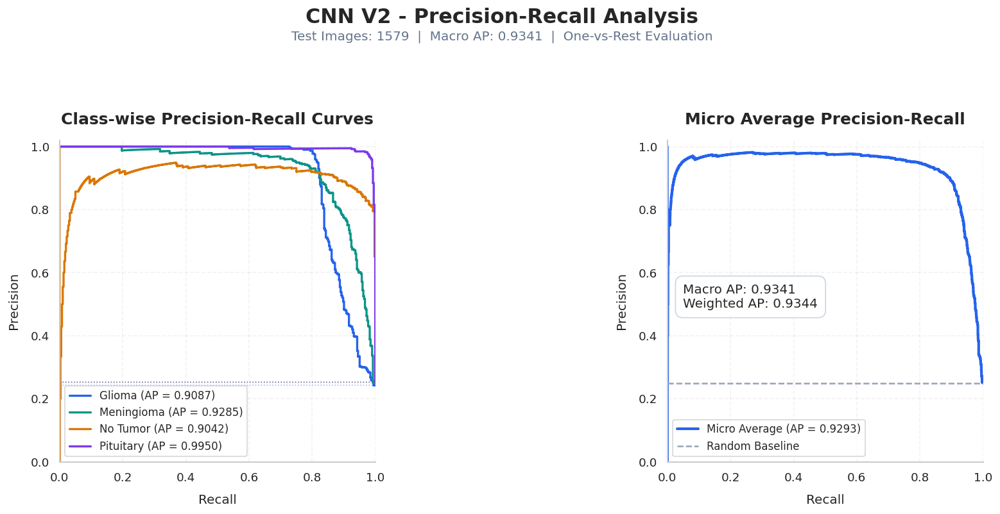

Precision-Recall eğrileri kaydedildi.


In [ ]:
# ==================================================
# 18.4. PRECISION-RECALL CURVE GÖRSELLEŞTİRME
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# --------------------------------------------------
# 1. SINIF BAZLI PR EĞRİLERİ
# --------------------------------------------------

for i, class_name in enumerate(CLASS_NAMES):

    axes[0].step(
        pr_recall[i],
        pr_precision[i],
        where="post",
        color=class_colors[class_name],
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AP = {average_precision[i]:.4f})"
        )
    )

    # Sınıfın pozitif örnek oranı
    axes[0].axhline(
        y_true_bin[:, i].mean(),
        color=class_colors[class_name],
        linestyle=":",
        linewidth=1,
        alpha=0.45
    )

axes[0].set_title(
    "Class-wise Precision-Recall Curves",
    fontweight="bold",
    pad=15
)

# --------------------------------------------------
# 2. MICRO AVERAGE PR
# --------------------------------------------------

axes[1].step(
    pr_recall["micro"],
    pr_precision["micro"],
    where="post",
    color="#2563EB",
    linewidth=2.5,
    label=(
        "Micro Average "
        f"(AP = {average_precision['micro']:.4f})"
    )
)

axes[1].axhline(
    y_true_bin.mean(),
    color="#94A3B8",
    linestyle="--",
    label="Random Baseline"
)

axes[1].text(
    0.05,
    0.48,
    f"Macro AP: {average_precision['macro']:.4f}\n"
    f"Weighted AP: {average_precision['weighted']:.4f}",
    transform=axes[1].transAxes,
    fontsize=12,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="#CBD5E1"
    )
)

axes[1].set_title(
    "Micro Average Precision-Recall",
    fontweight="bold",
    pad=15
)

# --------------------------------------------------
# 3. ORTAK GRAFİK AYARLARI
# --------------------------------------------------

for ax in axes:

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.set_xticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_yticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_xlabel("Recall", labelpad=10)
    ax.set_ylabel("Precision", labelpad=10)

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

    ax.legend(
        loc="lower left",
        frameon=True,
        facecolor="white",
        fontsize=10
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

# --------------------------------------------------
# 4. BAŞLIK VE ALT BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Precision-Recall Analysis",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    f"Test Images: {len(y_true)}  |  "
    f"Macro AP: {average_precision['macro']:.4f}  |  "
    "One-vs-Rest Evaluation",
    ha="center",
    fontsize=12,
    color="#64748B"
)

plt.tight_layout(
    rect=[0, 0.02, 1, 0.86]
)

# --------------------------------------------------
# 5. GRAFİĞİ KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "13_precision_recall_curves.png"
)

print("Precision-Recall eğrileri kaydedildi.")

Class-wise ROC-AUC and AP Comparison:



,Class,ROC_AUC,Average_Precision,ROC_AUC (%),AP (%)
0,Glioma,0.9277,0.9087,92.7738,90.8703
1,Meningioma,0.9618,0.9285,96.1797,92.8545
2,No Tumor,0.9830,0.9042,98.3026,90.4163
3,Pituitary,0.9984,0.9950,99.8427,99.5020


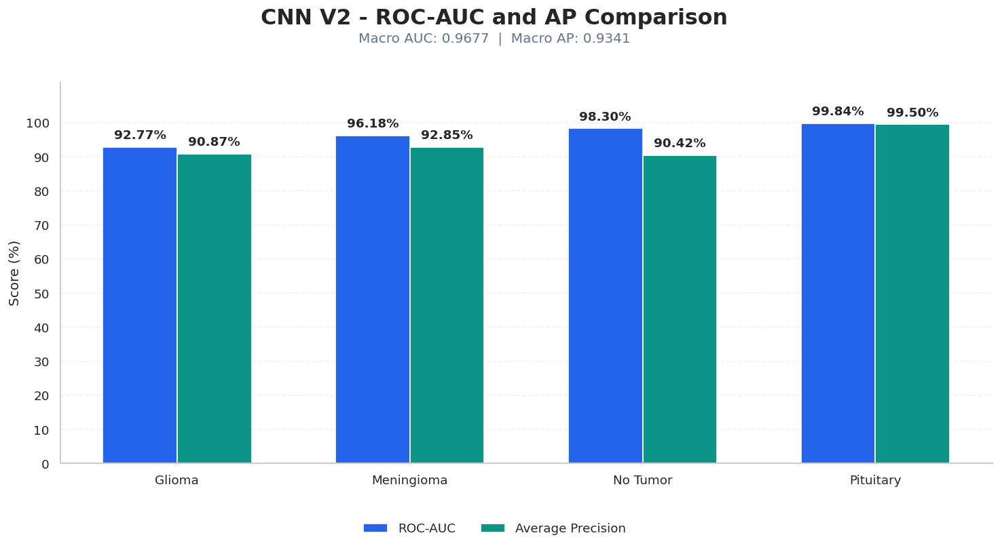

ROC-AUC ve AP karşılaştırması kaydedildi.


In [ ]:
# ==================================================
# 18.5. ROC-AUC VE AP KARŞILAŞTIRMASI
# ==================================================

# --------------------------------------------------
# 1. KARŞILAŞTIRMA TABLOSU
# --------------------------------------------------

auc_ap_comparison_df = pd.DataFrame({

    "Class": CLASS_NAMES,

    "ROC_AUC": [
        roc_auc[i]
        for i in range(4)
    ],

    "Average_Precision": [
        average_precision[i]
        for i in range(4)
    ]
})

auc_ap_comparison_df["ROC_AUC (%)"] = (
    auc_ap_comparison_df["ROC_AUC"] * 100
)

auc_ap_comparison_df["AP (%)"] = (
    auc_ap_comparison_df["Average_Precision"] * 100
)

print("Class-wise ROC-AUC and AP Comparison:\n")

display(
    auc_ap_comparison_df.round(4)
)

# --------------------------------------------------
# 2. GRAFİĞİ OLUŞTURMA
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

x = np.arange(len(CLASS_NAMES))
width = 0.32

bars1 = ax.bar(
    x - width / 2,
    auc_ap_comparison_df["ROC_AUC (%)"],
    width,
    label="ROC-AUC",
    color="#2563EB"
)

bars2 = ax.bar(
    x + width / 2,
    auc_ap_comparison_df["AP (%)"],
    width,
    label="Average Precision",
    color="#0D9488"
)

# --------------------------------------------------
# 3. SÜTUN ETİKETLERİ
# --------------------------------------------------

for bars in [bars1, bars2]:

    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

# --------------------------------------------------
# 4. GRAFİK AYARLARI
# --------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)

ax.set_ylabel("Score (%)")

ax.set_xlabel("")

ax.set_ylim(0, 112)

ax.set_yticks(
    np.arange(0, 101, 10)
)

ax.set_axisbelow(True)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.grid(
    axis="x",
    visible=False
)

# Legend için ayrı alan bırakıyoruz

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=2,
    frameon=False,
    fontsize=11
)

# --------------------------------------------------
# 5. BAŞLIK VE ALT BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - ROC-AUC and AP Comparison",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    f"Macro AUC: {roc_auc['macro']:.4f}  |  "
    f"Macro AP: {average_precision['macro']:.4f}",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.84,
    bottom=0.17
)

# --------------------------------------------------
# 6. SONUÇLARI KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "14_auc_ap_comparison.png"
)

auc_ap_comparison_df.to_csv(
    sonuc_klasoru / "auc_ap_comparison.csv",
    index=False
)

print("ROC-AUC ve AP karşılaştırması kaydedildi.")

In [ ]:
# ==================================================
# 18.6. EĞRİ VERİLERİNİ KAYDETME VE DOSYA KONTROLÜ
# ==================================================

# --------------------------------------------------
# 1. ROC EĞRİ VERİLERİ
# --------------------------------------------------

roc_curve_frames = []

for i, class_name in enumerate(CLASS_NAMES):

    curve_df = pd.DataFrame({

        "Class": class_name,

        "FPR": fpr[i],

        "TPR": tpr[i],

        "Threshold": roc_thresholds[i]
    })

    roc_curve_frames.append(curve_df)

for average_type in ["macro", "micro"]:

    curve_df = pd.DataFrame({

        "Class": average_type.capitalize(),

        "FPR": fpr[average_type],

        "TPR": tpr[average_type],

        "Threshold": np.nan
    })

    roc_curve_frames.append(curve_df)

pd.concat(
    roc_curve_frames,
    ignore_index=True
).to_csv(
    sonuc_klasoru / "roc_curve_points.csv",
    index=False
)

# --------------------------------------------------
# 2. PRECISION-RECALL EĞRİ VERİLERİ
# --------------------------------------------------

pr_curve_frames = []

for i, class_name in enumerate(CLASS_NAMES):

    curve_df = pd.DataFrame({

        "Class": class_name,

        "Recall": pr_recall[i],

        "Precision": pr_precision[i],

        "Threshold": np.append(
            pr_thresholds[i],
            np.nan
        )
    })

    pr_curve_frames.append(curve_df)

pr_curve_frames.append(

    pd.DataFrame({

        "Class": "Micro",

        "Recall": pr_recall["micro"],

        "Precision": pr_precision["micro"],

        "Threshold": np.nan
    })
)

pd.concat(
    pr_curve_frames,
    ignore_index=True
).to_csv(
    sonuc_klasoru / "precision_recall_curve_points.csv",
    index=False
)

# --------------------------------------------------
# 3. DOSYA KONTROLÜ
# --------------------------------------------------

step18_files = [

    "roc_auc_class_metrics.csv",
    "roc_auc_average_metrics.csv",

    "average_precision_class_metrics.csv",
    "average_precision_summary.csv",

    "auc_ap_comparison.csv",

    "roc_curve_points.csv",
    "precision_recall_curve_points.csv",

    "12_roc_curve_analysis.png",
    "13_precision_recall_curves.png",
    "14_auc_ap_comparison.png"
]

print("=" * 70)
print("18. ADIM - DOSYA KONTROLÜ")
print("=" * 70)

for filename in step18_files:

    file_path = sonuc_klasoru / filename

    if file_path.exists():

        size_kb = file_path.stat().st_size / 1024

        print(
            f"HAZIR | {filename} | "
            f"{size_kb:.2f} KB"
        )

    else:

        print(f"EKSİK | {filename}")

all_saved = all(

    (sonuc_klasoru / filename).exists()

    and

    (sonuc_klasoru / filename).stat().st_size > 0

    for filename in step18_files
)

# --------------------------------------------------
# 4. GENEL SONUÇ ÖZETİ
# --------------------------------------------------

print("\n" + "=" * 70)
print("ROC-AUC VE AP GENEL ÖZETİ")
print("=" * 70)

print(f"Macro ROC-AUC: {roc_auc['macro']:.4f}")

print(f"Micro ROC-AUC: {roc_auc['micro']:.4f}")

print(f"Weighted ROC-AUC: {roc_auc['weighted']:.4f}")

print(f"\nMacro AP: {average_precision['macro']:.4f}")

print(f"Micro AP: {average_precision['micro']:.4f}")

print(f"Weighted AP: {average_precision['weighted']:.4f}")

print("\n" + "=" * 70)

if all_saved:

    print("18. ADIM BAŞARIYLA TAMAMLANDI.")

else:

    print("Eksik dosyalar bulunuyor.")

18. ADIM - DOSYA KONTROLÜ
HAZIR | roc_auc_class_metrics.csv | 0.21 KB
HAZIR | roc_auc_average_metrics.csv | 0.09 KB
HAZIR | average_precision_class_metrics.csv | 0.32 KB
HAZIR | average_precision_summary.csv | 0.10 KB
HAZIR | auc_ap_comparison.csv | 0.38 KB
HAZIR | roc_curve_points.csv | 65.17 KB
HAZIR | precision_recall_curve_points.csv | 641.95 KB
HAZIR | 12_roc_curve_analysis.png | 313.83 KB
HAZIR | 13_precision_recall_curves.png | 323.79 KB
HAZIR | 14_auc_ap_comparison.png | 195.97 KB

ROC-AUC VE AP GENEL ÖZETİ
Macro ROC-AUC: 0.9677
Micro ROC-AUC: 0.9696
Weighted ROC-AUC: 0.9682

Macro AP: 0.9341
Micro AP: 0.9293
Weighted AP: 0.9344

18. ADIM BAŞARIYLA TAMAMLANDI.


/tmp/ipykernel_2058/3263413085.py:41: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(


In [23]:
# ==================================================
# 19.1. GÖRÜNTÜLERİN VE TAHMİNLERİN HAZIRLANMASI
# ==================================================

import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

SEED = 42

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

CLASS_KEYS = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# --------------------------------------------------
# 1. VERİ SETİNİN HAZIRLANMASI
# --------------------------------------------------

dataset_root = Path("/content/CNN_V2_Dataset")

dataset_root.mkdir(
    parents=True,
    exist_ok=True
)

if (
    not (dataset_root / "Training").is_dir()
    or not (dataset_root / "Testing").is_dir()
):

    print("Veri seti ZIP dosyasından çıkarılıyor...")

    with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
        zip_ref.extractall(dataset_root)

else:

    print("Veri seti zaten hazır.")

# --------------------------------------------------
# 2. TEST TAHMİNLERİNİN HAZIRLANMASI
# --------------------------------------------------

test_df = pd.read_csv(
    csv_yolu / "test.csv"
).reset_index(drop=True)

prediction_data = np.load(
    sonuc_klasoru / "test_predictions.npz"
)

y_true = prediction_data["y_true"]
y_pred = prediction_data["y_pred"]
y_prob = prediction_data["y_prob"]

predictions_df = test_df.copy()

predictions_df["true_index"] = y_true

predictions_df["predicted_index"] = y_pred

predictions_df["actual_class"] = [
    CLASS_NAMES[i] for i in y_true
]

predictions_df["predicted_class"] = [
    CLASS_NAMES[i] for i in y_pred
]

predictions_df["confidence"] = y_prob.max(axis=1)

predictions_df["true_class_probability"] = (
    y_prob[np.arange(len(y_true)), y_true]
)

predictions_df["correct"] = (
    y_true == y_pred
)

for i, class_key in enumerate(CLASS_KEYS):

    predictions_df[f"prob_{class_key}"] = (
        y_prob[:, i]
    )

# --------------------------------------------------
# 3. VERİ KONTROLLERİ
# --------------------------------------------------

assert len(predictions_df) == 1579

assert y_prob.shape == (1579, 4)

assert np.array_equal(
    test_df["sinif"].map(CLASS_TO_IDX).to_numpy(),
    y_true
)

assert np.array_equal(
    y_prob.argmax(axis=1),
    y_pred
)

assert np.isfinite(y_prob).all()

assert np.allclose(
    y_prob.sum(axis=1),
    1,
    atol=1e-5
)

missing_images = [

    dosya

    for dosya in predictions_df["dosya"]

    if not (dataset_root / dosya).is_file()
]

assert len(missing_images) == 0, (
    f"{len(missing_images)} görüntü eksik."
)

# --------------------------------------------------
# 4. DOĞRU VE YANLIŞ TAHMİNLER
# --------------------------------------------------

correct_df = predictions_df[
    predictions_df["correct"]
].copy()

incorrect_df = predictions_df[
    ~predictions_df["correct"]
].copy()

assert len(correct_df) == 1415
assert len(incorrect_df) == 164

# --------------------------------------------------
# 5. SONUÇLAR
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - IMAGE PREDICTION ANALYSIS")
print("=" * 65)

print("Toplam görüntü:", len(predictions_df))

print("Doğru tahmin:", len(correct_df))

print("Yanlış tahmin:", len(incorrect_df))

print("Eksik görüntü:", len(missing_images))

print("\nGörüntü bazlı tahmin örnekleri:\n")

display(predictions_df.head())

print("\nBütün veri kontrolleri başarılı.")

Veri seti zaten hazır.
CNN V2 - IMAGE PREDICTION ANALYSIS
Toplam görüntü: 1579
Doğru tahmin: 1415
Yanlış tahmin: 164
Eksik görüntü: 0

Görüntü bazlı tahmin örnekleri:



,dosya,sinif,true_index,predicted_index,actual_class,predicted_class,confidence,true_class_probability,correct,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary
0,Testing/glioma/Te-gl_311.jpg,glioma,0,0,Glioma,Glioma,0.999966,0.999966,True,0.999966,0.000033,8.762265e-08,1.275870e-07
1,Testing/glioma/Te-gl_169.jpg,glioma,0,1,Glioma,Meningioma,0.983419,0.008640,False,0.008640,0.983419,1.181656e-05,7.929316e-03
2,Testing/glioma/Te-gl_299.jpg,glioma,0,0,Glioma,Glioma,0.999996,0.999996,True,0.999996,0.000004,1.496609e-07,1.120011e-07
3,Testing/glioma/Te-gl_233.jpg,glioma,0,0,Glioma,Glioma,0.999992,0.999992,True,0.999992,0.000007,2.467215e-07,1.076086e-07
4,Testing/meningioma/Te-me_157.jpg,meningioma,1,1,Meningioma,Meningioma,0.630007,0.630007,True,0.002004,0.630007,3.328825e-01,3.510600e-02



Bütün veri kontrolleri başarılı.


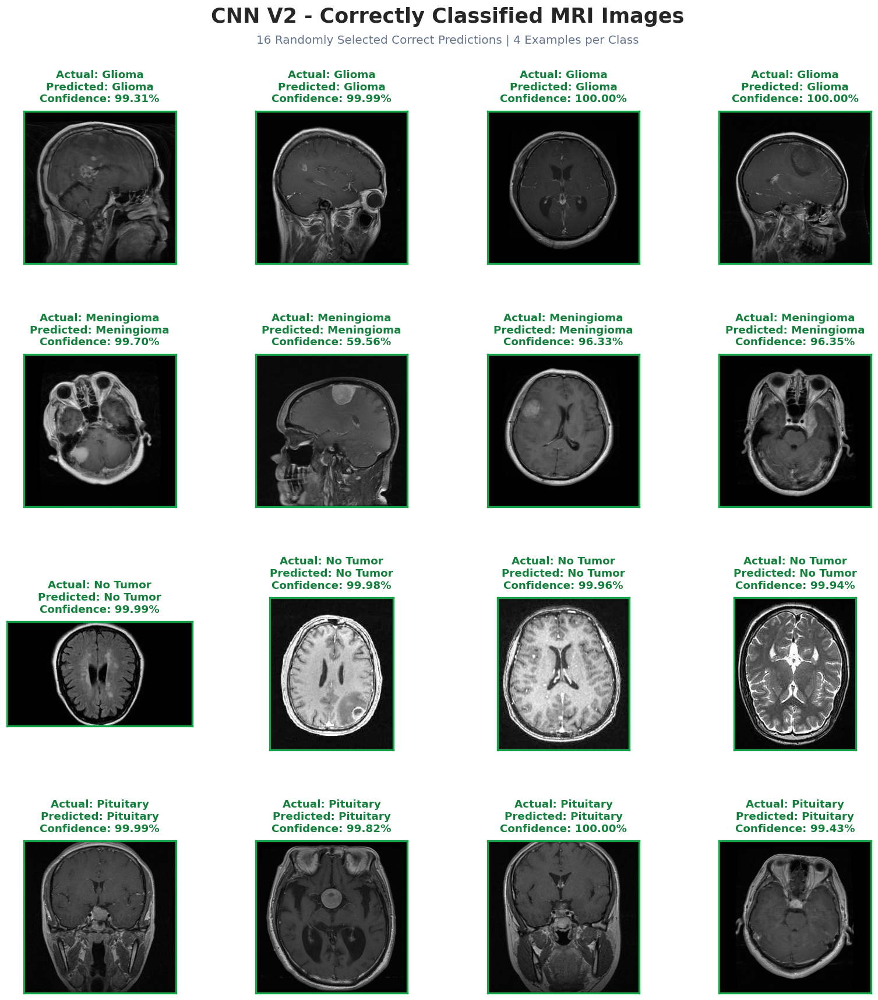

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/15_correct_prediction_examples.png
Doğru tahmin örnekleri kaydedildi.


In [24]:
# ==================================================
# 19.2. DOĞRU SINIFLANDIRILAN MR GÖRÜNTÜLERİ
# ==================================================

# --------------------------------------------------
# 1. ÖRNEKLERİN SEÇİLMESİ
# --------------------------------------------------

correct_samples = pd.concat([

    correct_df[
        correct_df["actual_class"] == class_name
    ].sample(
        n=4,
        random_state=SEED
    )

    for class_name in CLASS_NAMES

], ignore_index=True)

# --------------------------------------------------
# 2. GRAFİĞİN OLUŞTURULMASI
# --------------------------------------------------

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 15)
)

for i, row in enumerate(
    correct_samples.itertuples(index=False)
):

    ax = axes.flat[i]

    image_path = dataset_root / row.dosya

    with Image.open(image_path) as img:

        image = np.array(img.convert("L"))

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(
        f"Actual: {row.actual_class}\n"
        f"Predicted: {row.predicted_class}\n"
        f"Confidence: {row.confidence:.2%}",
        fontsize=11,
        color="#15803D",
        fontweight="bold",
        pad=10
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

    for spine in ax.spines.values():

        spine.set_visible(True)
        spine.set_color("#16A34A")
        spine.set_linewidth(2)

# --------------------------------------------------
# 3. BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Correctly Classified MRI Images",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.945,
    "16 Randomly Selected Correct Predictions | "
    "4 Examples per Class",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.88,
    bottom=0.04,
    wspace=0.25,
    hspace=0.60
)

# --------------------------------------------------
# 4. KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "15_correct_prediction_examples.png"
)

correct_samples.to_csv(
    sonuc_klasoru / "correct_prediction_examples.csv",
    index=False
)

print("Doğru tahmin örnekleri kaydedildi.")

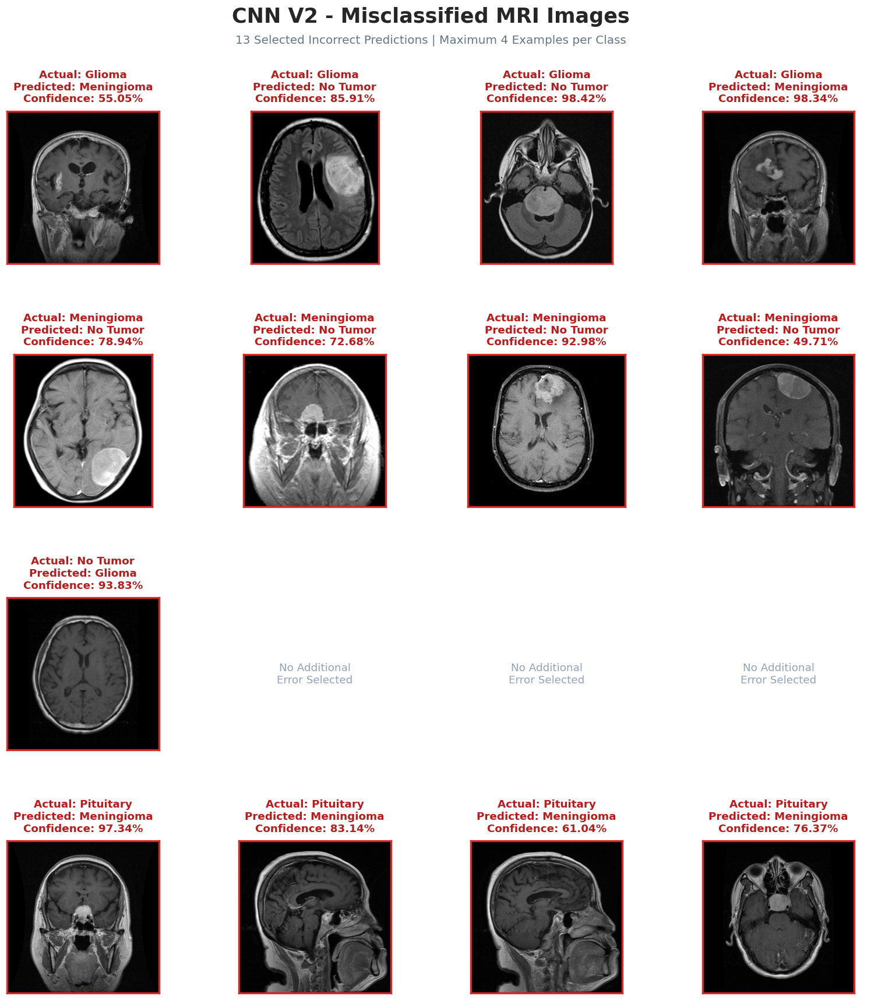

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/16_incorrect_prediction_examples.png
Yanlış tahmin örnekleri kaydedildi.


In [25]:
# ==================================================
# 19.3. YANLIŞ SINIFLANDIRILAN MR GÖRÜNTÜLERİ
# ==================================================

# --------------------------------------------------
# 1. YANLIŞ TAHMİNLERİN SEÇİLMESİ
# --------------------------------------------------

incorrect_sample_frames = []

for class_name in CLASS_NAMES:

    class_errors = incorrect_df[
        incorrect_df["actual_class"] == class_name
    ]

    sample_count = min(
        4,
        len(class_errors)
    )

    samples = class_errors.sample(
        n=sample_count,
        random_state=SEED
    )

    incorrect_sample_frames.append(samples)

incorrect_samples = pd.concat(
    incorrect_sample_frames,
    ignore_index=True
)

# --------------------------------------------------
# 2. GRAFİĞİN OLUŞTURULMASI
# --------------------------------------------------

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 15)
)

for i, class_name in enumerate(CLASS_NAMES):

    class_samples = incorrect_samples[
        incorrect_samples["actual_class"] == class_name
    ]

    rows = list(
        class_samples.itertuples(index=False)
    )

    for j in range(4):

        ax = axes[i, j]

        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)

        if j >= len(rows):

            ax.axis("off")

            ax.text(
                0.5,
                0.5,
                "No Additional\nError Selected",
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize=11,
                color="#94A3B8"
            )

            continue

        row = rows[j]

        with Image.open(
            dataset_root / row.dosya
        ) as img:

            image = np.array(img.convert("L"))

        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        ax.set_title(
            f"Actual: {row.actual_class}\n"
            f"Predicted: {row.predicted_class}\n"
            f"Confidence: {row.confidence:.2%}",
            fontsize=11,
            fontweight="bold",
            color="#B91C1C",
            pad=10
        )

        for spine in ax.spines.values():

            spine.set_visible(True)
            spine.set_color("#DC2626")
            spine.set_linewidth(2)

# --------------------------------------------------
# 3. BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Misclassified MRI Images",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.945,
    f"{len(incorrect_samples)} Selected Incorrect Predictions | "
    "Maximum 4 Examples per Class",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.88,
    bottom=0.04,
    wspace=0.25,
    hspace=0.60
)

# --------------------------------------------------
# 4. KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "16_incorrect_prediction_examples.png"
)

incorrect_samples.to_csv(
    sonuc_klasoru / "incorrect_prediction_examples.csv",
    index=False
)

print("Yanlış tahmin örnekleri kaydedildi.")

CNN V2 - HIGH CONFIDENCE ERRORS


,dosya,actual_class,predicted_class,confidence,true_class_probability
0,Testing/glioma/Te-gl_74.jpg,Glioma,No Tumor,1.0000,0.0
1,Testing/meningioma/Te-me_278.jpg,Meningioma,No Tumor,1.0000,0.0
2,Testing/meningioma/Te-me_8.jpg,Meningioma,No Tumor,1.0000,0.0
3,Testing/glioma/Te-gl_372.jpg,Glioma,No Tumor,1.0000,0.0
4,Testing/meningioma/Te-me_26.jpg,Meningioma,No Tumor,1.0000,0.0
5,Testing/glioma/Te-gl_264.jpg,Glioma,No Tumor,1.0000,0.0
6,Testing/glioma/Te-gl_335.jpg,Glioma,No Tumor,0.9999,0.0
7,Testing/glioma/Te-gl_318.jpg,Glioma,No Tumor,0.9999,0.0


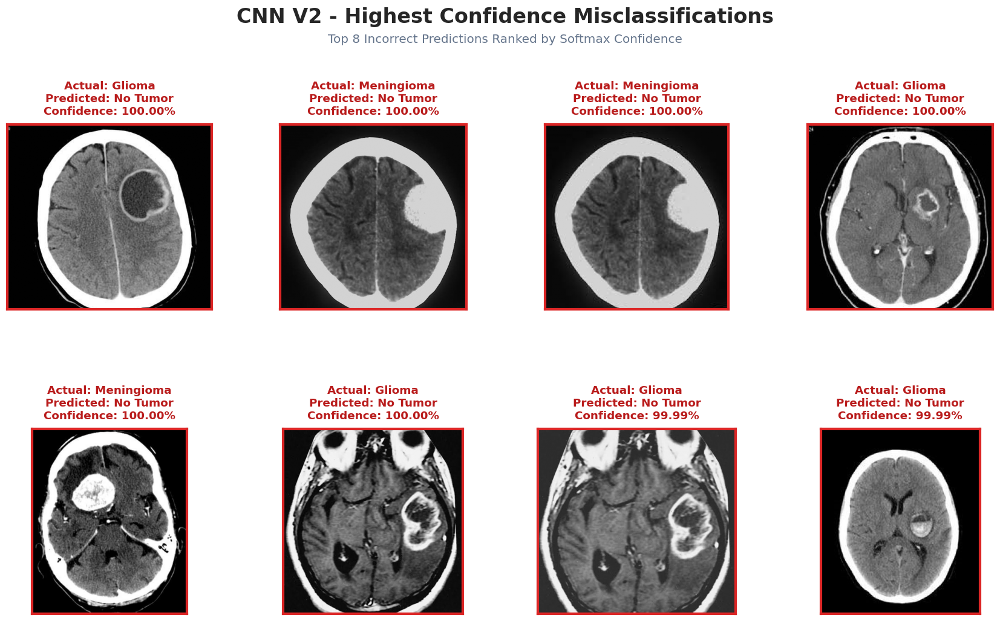

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/17_high_confidence_errors.png
Yüksek güvenli yanlış tahminler kaydedildi.


In [26]:
# ==================================================
# 19.4. HIGH CONFIDENCE ERROR ANALYSIS
# ==================================================

# --------------------------------------------------
# 1. YÜKSEK GÜVENLİ YANLIŞ TAHMİNLER
# --------------------------------------------------

high_confidence_errors = (
    incorrect_df
    .sort_values(
        "confidence",
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

print("=" * 65)
print("CNN V2 - HIGH CONFIDENCE ERRORS")
print("=" * 65)

display(

    high_confidence_errors[[
        "dosya",
        "actual_class",
        "predicted_class",
        "confidence",
        "true_class_probability"
    ]].round(4)
)

# --------------------------------------------------
# 2. GRAFİĞİN OLUŞTURULMASI
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 4,
    figsize=(15, 9)
)

for i, row in enumerate(
    high_confidence_errors.itertuples(index=False)
):

    ax = axes.flat[i]

    with Image.open(
        dataset_root / row.dosya
    ) as img:

        image = np.array(img.convert("L"))

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(
        f"Actual: {row.actual_class}\n"
        f"Predicted: {row.predicted_class}\n"
        f"Confidence: {row.confidence:.2%}",
        fontsize=11,
        color="#B91C1C",
        fontweight="bold",
        pad=10
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

    for spine in ax.spines.values():

        spine.set_visible(True)
        spine.set_color("#DC2626")
        spine.set_linewidth(2.5)

# --------------------------------------------------
# 3. BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Highest Confidence Misclassifications",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Top 8 Incorrect Predictions Ranked by Softmax Confidence",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.80,
    bottom=0.05,
    wspace=0.25,
    hspace=0.65
)

# --------------------------------------------------
# 4. KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "17_high_confidence_errors.png"
)

high_confidence_errors.to_csv(
    sonuc_klasoru / "high_confidence_errors.csv",
    index=False
)

print("Yüksek güvenli yanlış tahminler kaydedildi.")

CNN V2 - HIGH CONFIDENCE ERRORS


,dosya,actual_class,predicted_class,confidence,true_class_probability
0,Testing/glioma/Te-gl_74.jpg,Glioma,No Tumor,1.0000,0.0
1,Testing/meningioma/Te-me_278.jpg,Meningioma,No Tumor,1.0000,0.0
2,Testing/meningioma/Te-me_8.jpg,Meningioma,No Tumor,1.0000,0.0
3,Testing/glioma/Te-gl_372.jpg,Glioma,No Tumor,1.0000,0.0
4,Testing/meningioma/Te-me_26.jpg,Meningioma,No Tumor,1.0000,0.0
5,Testing/glioma/Te-gl_264.jpg,Glioma,No Tumor,1.0000,0.0
6,Testing/glioma/Te-gl_335.jpg,Glioma,No Tumor,0.9999,0.0
7,Testing/glioma/Te-gl_318.jpg,Glioma,No Tumor,0.9999,0.0


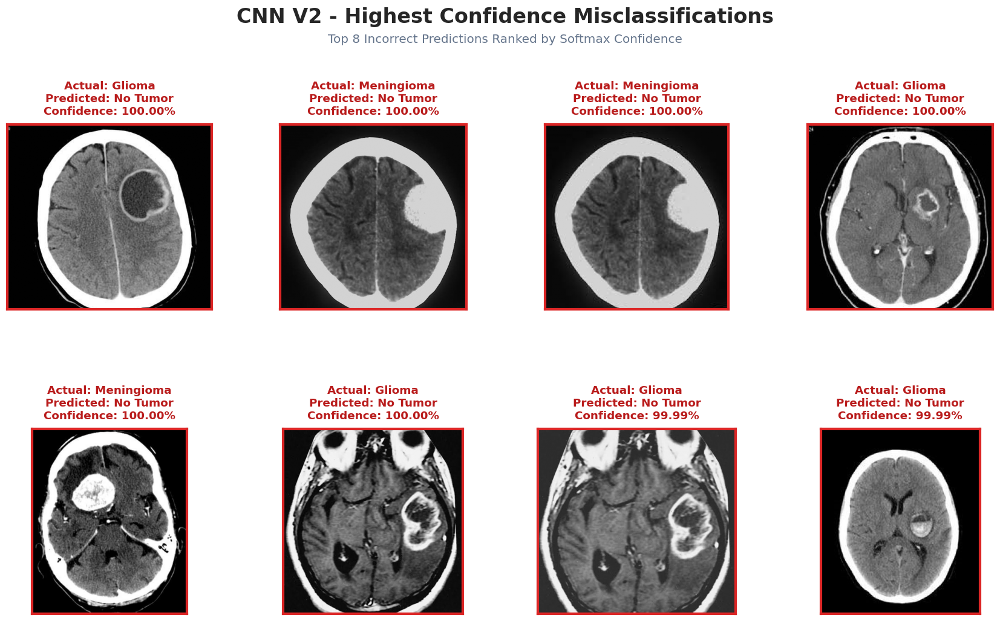

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/17_high_confidence_errors.png
Yüksek güvenli yanlış tahminler kaydedildi.


In [27]:
# ==================================================
# 19.4. HIGH CONFIDENCE ERROR ANALYSIS
# ==================================================

# --------------------------------------------------
# 1. YÜKSEK GÜVENLİ YANLIŞ TAHMİNLER
# --------------------------------------------------

high_confidence_errors = (
    incorrect_df
    .sort_values(
        "confidence",
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

print("=" * 65)
print("CNN V2 - HIGH CONFIDENCE ERRORS")
print("=" * 65)

display(

    high_confidence_errors[[
        "dosya",
        "actual_class",
        "predicted_class",
        "confidence",
        "true_class_probability"
    ]].round(4)
)

# --------------------------------------------------
# 2. GRAFİĞİN OLUŞTURULMASI
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 4,
    figsize=(15, 9)
)

for i, row in enumerate(
    high_confidence_errors.itertuples(index=False)
):

    ax = axes.flat[i]

    with Image.open(
        dataset_root / row.dosya
    ) as img:

        image = np.array(img.convert("L"))

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(
        f"Actual: {row.actual_class}\n"
        f"Predicted: {row.predicted_class}\n"
        f"Confidence: {row.confidence:.2%}",
        fontsize=11,
        color="#B91C1C",
        fontweight="bold",
        pad=10
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

    for spine in ax.spines.values():

        spine.set_visible(True)
        spine.set_color("#DC2626")
        spine.set_linewidth(2.5)

# --------------------------------------------------
# 3. BAŞLIK
# --------------------------------------------------

fig.suptitle(
    "CNN V2 - Highest Confidence Misclassifications",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.925,
    "Top 8 Incorrect Predictions Ranked by Softmax Confidence",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.80,
    bottom=0.05,
    wspace=0.25,
    hspace=0.65
)

# --------------------------------------------------
# 4. KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "17_high_confidence_errors.png"
)

high_confidence_errors.to_csv(
    sonuc_klasoru / "high_confidence_errors.csv",
    index=False
)

print("Yüksek güvenli yanlış tahminler kaydedildi.")

CNN V2 - CONFIDENCE ANALYSIS


,Group,Count,Mean_Confidence (%),Median_Confidence (%),Std_Confidence (%),Min_Confidence (%),Max_Confidence (%),Confidence_Above_90,Confidence_Above_95,Confidence_Above_99
0,Correct,1415,97.510002,99.88,7.20,41.32,100.0,1312,1250,1087
1,Incorrect,164,84.709999,91.97,16.88,39.47,100.0,88,65,38



Confidence Threshold Analysis:



,Confidence_Threshold,Selected_Images,Correct,Incorrect,Coverage (%),Accuracy (%)
0,0.50,1570,1413,157,99.43,90.00
1,0.60,1537,1397,140,97.34,90.89
2,0.70,1514,1386,128,95.88,91.55
3,0.80,1480,1363,117,93.73,92.09
4,0.90,1400,1312,88,88.66,93.71
5,0.95,1315,1250,65,83.28,95.06
6,0.99,1125,1087,38,71.25,96.62


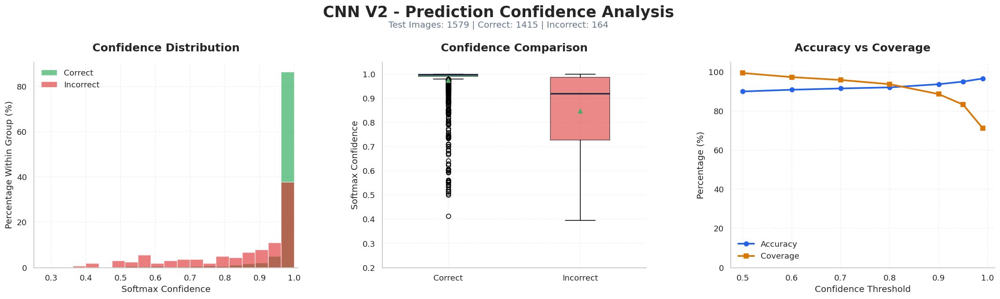

Güven skoru analizleri kaydedildi.


In [ ]:
# ==================================================
# 19.5. CONFIDENCE DISTRIBUTION ANALYSIS
# ==================================================

# --------------------------------------------------
# 1. GÜVEN SKORU İSTATİSTİKLERİ
# --------------------------------------------------

confidence_records = []

for group_name, group_df in [

    ("Correct", correct_df),

    ("Incorrect", incorrect_df)

]:

    scores = group_df["confidence"]

    confidence_records.append({

        "Group": group_name,

        "Count": len(scores),

        "Mean_Confidence (%)":
            scores.mean() * 100,

        "Median_Confidence (%)":
            scores.median() * 100,

        "Std_Confidence (%)":
            scores.std() * 100,

        "Min_Confidence (%)":
            scores.min() * 100,

        "Max_Confidence (%)":
            scores.max() * 100,

        "Confidence_Above_90":
            int((scores >= 0.90).sum()),

        "Confidence_Above_95":
            int((scores >= 0.95).sum()),

        "Confidence_Above_99":
            int((scores >= 0.99).sum())

    })

confidence_summary_df = pd.DataFrame(
    confidence_records
)

print("=" * 65)
print("CNN V2 - CONFIDENCE ANALYSIS")
print("=" * 65)

display(confidence_summary_df.round(2))

# --------------------------------------------------
# 2. FARKLI GÜVEN EŞİKLERİNDE HATA ANALİZİ
# --------------------------------------------------

thresholds = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95,
    0.99
]

threshold_records = []

for threshold in thresholds:

    selected = predictions_df[
        predictions_df["confidence"] >= threshold
    ]

    count = len(selected)

    correct_count = int(
        selected["correct"].sum()
    )

    error_count = count - correct_count

    threshold_records.append({

        "Confidence_Threshold": threshold,

        "Selected_Images": count,

        "Correct": correct_count,

        "Incorrect": error_count,

        "Coverage (%)":
            count / len(predictions_df) * 100,

        "Accuracy (%)":
            correct_count / count * 100
            if count > 0 else np.nan

    })

threshold_df = pd.DataFrame(
    threshold_records
)

print("\nConfidence Threshold Analysis:\n")

display(threshold_df.round(2))

# --------------------------------------------------
# 3. GRAFİKLER
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

# GRAFİK 1 - Histogram

bins = np.linspace(0.25, 1, 21)

for group_df, color, label in [

    (correct_df, "#16A34A", "Correct"),

    (incorrect_df, "#DC2626", "Incorrect")

]:

    values = group_df["confidence"]

    weights = np.ones(len(values)) / len(values) * 100

    axes[0].hist(
        values,
        bins=bins,
        weights=weights,
        alpha=0.60,
        color=color,
        edgecolor="white",
        label=label
    )

axes[0].set_title(
    "Confidence Distribution",
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Softmax Confidence")
axes[0].set_ylabel("Percentage Within Group (%)")
axes[0].set_xlim(0.25, 1.01)
axes[0].legend(loc="upper left")

# GRAFİK 2 - Boxplot

box = axes[1].boxplot(

    [
        correct_df["confidence"],
        incorrect_df["confidence"]
    ],

    tick_labels=["Correct", "Incorrect"],

    patch_artist=True,

    widths=0.45,

    showmeans=True,

    medianprops={
        "color": "#1E293B",
        "linewidth": 2
    }
)

for patch, color in zip(
    box["boxes"],
    ["#16A34A", "#DC2626"]
):

    patch.set_facecolor(color)
    patch.set_alpha(0.55)

axes[1].set_title(
    "Confidence Comparison",
    fontweight="bold",
    pad=15
)

axes[1].set_ylabel("Softmax Confidence")

axes[1].set_ylim(0.20, 1.05)

# GRAFİK 3 - Threshold Analysis

axes[2].plot(
    threshold_df["Confidence_Threshold"],
    threshold_df["Accuracy (%)"],
    color="#2563EB",
    marker="o",
    linewidth=2.3,
    label="Accuracy"
)

axes[2].plot(
    threshold_df["Confidence_Threshold"],
    threshold_df["Coverage (%)"],
    color="#D97706",
    marker="s",
    linewidth=2.3,
    label="Coverage"
)

axes[2].set_title(
    "Accuracy vs Coverage",
    fontweight="bold",
    pad=15
)

axes[2].set_xlabel("Confidence Threshold")
axes[2].set_ylabel("Percentage (%)")

axes[2].set_ylim(0, 105)

axes[2].legend(loc="lower left")

# --------------------------------------------------
# 4. ORTAK GRAFİK AYARLARI
# --------------------------------------------------

for ax in axes:

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

fig.suptitle(
    "CNN V2 - Prediction Confidence Analysis",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.91,
    "Test Images: 1579 | Correct: 1415 | "
    "Incorrect: 164",
    ha="center",
    fontsize=12,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.06,
    right=0.97,
    top=0.80,
    bottom=0.15,
    wspace=0.32
)

# --------------------------------------------------
# 5. KAYDETME
# --------------------------------------------------

grafik_kaydet(
    fig,
    "18_confidence_analysis.png"
)

confidence_summary_df.to_csv(
    sonuc_klasoru / "confidence_summary.csv",
    index=False
)

threshold_df.to_csv(
    sonuc_klasoru / "confidence_threshold_analysis.csv",
    index=False
)

print("Güven skoru analizleri kaydedildi.")

In [ ]:
# ==================================================
# 19.6. DOSYA KONTROLÜ VE GENEL ÖZET
# ==================================================

step19_files = [

    "15_correct_prediction_examples.png",

    "16_incorrect_prediction_examples.png",

    "17_high_confidence_errors.png",

    "18_confidence_analysis.png",

    "correct_prediction_examples.csv",

    "incorrect_prediction_examples.csv",

    "high_confidence_errors.csv",

    "confidence_summary.csv",

    "confidence_threshold_analysis.csv"

]

print("=" * 70)
print("19. ADIM - DOSYA KONTROLÜ")
print("=" * 70)

for filename in step19_files:

    file_path = sonuc_klasoru / filename

    if file_path.exists():

        print(
            f"HAZIR | {filename} | "
            f"{file_path.stat().st_size / 1024:.2f} KB"
        )

    else:

        print(f"EKSİK | {filename}")

# --------------------------------------------------
# GENEL ANALİZ ÖZETİ
# --------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTION ANALYSIS SUMMARY")
print("=" * 70)

print(
    "Ortalama doğru tahmin güveni: "
    f"{correct_df['confidence'].mean():.2%}"
)

print(
    "Ortalama yanlış tahmin güveni: "
    f"{incorrect_df['confidence'].mean():.2%}"
)

print(
    "En yüksek yanlış tahmin güveni: "
    f"{incorrect_df['confidence'].max():.2%}"
)

for threshold in [0.90, 0.95, 0.99]:

    error_count = int(
        (
            incorrect_df["confidence"] >= threshold
        ).sum()
    )

    print(
        f"%{threshold * 100:.0f} ve üzeri güvenli "
        f"yanlış tahmin: {error_count}"
    )

# --------------------------------------------------
# SON KONTROL
# --------------------------------------------------

all_saved = all(

    (sonuc_klasoru / filename).is_file()

    and

    (sonuc_klasoru / filename).stat().st_size > 0

    for filename in step19_files
)

print("\n" + "=" * 70)

if all_saved:

    print("19. ADIM BAŞARIYLA TAMAMLANDI.")

else:

    print("Eksik dosyalar bulunuyor.")

19. ADIM - DOSYA KONTROLÜ
HAZIR | 15_correct_prediction_examples.png | 3655.17 KB
HAZIR | 16_incorrect_prediction_examples.png | 2876.38 KB
HAZIR | 17_high_confidence_errors.png | 2104.51 KB
HAZIR | 18_confidence_analysis.png | 358.55 KB
HAZIR | correct_prediction_examples.csv | 2.31 KB
HAZIR | incorrect_prediction_examples.csv | 1.93 KB
HAZIR | high_confidence_errors.csv | 1.25 KB
HAZIR | confidence_summary.csv | 0.36 KB
HAZIR | confidence_threshold_analysis.csv | 0.43 KB

PREDICTION ANALYSIS SUMMARY
Ortalama doğru tahmin güveni: 97.51%
Ortalama yanlış tahmin güveni: 84.71%
En yüksek yanlış tahmin güveni: 100.00%
%90 ve üzeri güvenli yanlış tahmin: 88
%95 ve üzeri güvenli yanlış tahmin: 65
%99 ve üzeri güvenli yanlış tahmin: 38

19. ADIM BAŞARIYLA TAMAMLANDI.


In [32]:
# ==================================================
# 20. GRAD-CAM - HAZIRLIK KONTROLÜ
# ==================================================

import torch
import json

print("=" * 65)
print("CNN V2 - GRAD-CAM PREPARATION")
print("=" * 65)

required_variables = [
    "ConvBlock",
    "CNN_V2",
    "model",
    "test_model",
    "eval_transform",
    "dataset_root",
    "predictions_df",
    "correct_samples",
    "incorrect_samples",
    "high_confidence_errors",
    "grafik_kaydet"
]

for variable in required_variables:

    status = (
        "HAZIR"
        if variable in globals()
        else "EKSİK"
    )

    print(f"{variable}: {status}")

# --------------------------------------------------
# KAYDEDİLMİŞ DOSYALAR
# --------------------------------------------------

print("\nDrive dosyaları:")

required_files = {
    "Eğitilmiş CNN V2 modeli":
        proje_yolu / "modeller" / "cnn_v2_best.pth",

    "Ön işleme ayarları":
        sonuc_klasoru / "preprocessing_config.json",

    "Eğitim ayarları":
        sonuc_klasoru / "training_config.json",

    "Test tahminleri":
        sonuc_klasoru / "test_predictions.npz"
}

for name, path in required_files.items():

    print(
        f"{name}: "
        f"{'HAZIR' if path.is_file() else 'EKSİK'}"
    )

# --------------------------------------------------
# GPU KONTROLÜ
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nCihaz:", device)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

print("\nGrad-CAM hazırlık kontrolü tamamlandı.")

CNN V2 - GRAD-CAM PREPARATION
ConvBlock: HAZIR
CNN_V2: HAZIR
model: HAZIR
test_model: HAZIR
eval_transform: HAZIR
dataset_root: HAZIR
predictions_df: HAZIR
correct_samples: HAZIR
incorrect_samples: HAZIR
high_confidence_errors: HAZIR
grafik_kaydet: HAZIR

Drive dosyaları:
Eğitilmiş CNN V2 modeli: HAZIR
Ön işleme ayarları: HAZIR
Eğitim ayarları: HAZIR
Test tahminleri: HAZIR

Cihaz: cuda
GPU: Tesla T4

Grad-CAM hazırlık kontrolü tamamlandı.


In [33]:
# ==================================================
# 20.1. EĞİTİLMİŞ CNN V2 MODELİNİN GERİ YÜKLENMESİ
# ==================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from torchvision import transforms
from torchvision.transforms import InterpolationMode

# --------------------------------------------------
# 1. CİHAZ AYARLARI
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# --------------------------------------------------
# 2. EĞİTİLMİŞ MODELİ DRIVE'DAN YÜKLEME
# --------------------------------------------------

best_model_yolu = (
    proje_yolu / "modeller" / "cnn_v2_best.pth"
)

checkpoint = torch.load(
    best_model_yolu,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["model_name"] == "CNN_V2"

assert checkpoint["dataset_version"] == "veri_bolunmesi_v3"

assert checkpoint["class_to_idx"] == CLASS_TO_IDX

# --------------------------------------------------
# 3. MODELİ OLUŞTURMA
# --------------------------------------------------

test_model = CNN_V2().to(device)

test_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

test_model.eval()

for parameter in test_model.parameters():
    parameter.requires_grad_(True)

# --------------------------------------------------
# 4. ÖN İŞLEME AYARLARI
# --------------------------------------------------

IMAGE_SIZE = 224

CNN_MEAN = 0.17666279376003613
CNN_STD = 0.19102925562565193

eval_transform = transforms.Compose([

    transforms.Grayscale(
        num_output_channels=1
    ),

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[CNN_MEAN],
        std=[CNN_STD]
    )

])

# --------------------------------------------------
# 5. GRAD-CAM HEDEF KATMANI
# --------------------------------------------------

conv_layers = [

    (name, layer)

    for name, layer in test_model.named_modules()

    if isinstance(layer, nn.Conv2d)

]

target_layer_name, target_layer = conv_layers[-1]

# --------------------------------------------------
# 6. MODEL KONTROLLERİ
# --------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in test_model.parameters()
)

assert total_parameters == 3337764

assert checkpoint["epoch"] == 33

# --------------------------------------------------
# 7. SONUÇLAR
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - MODEL RESTORATION")
print("=" * 65)

print("Model:", checkpoint["model_name"])

print("En iyi epoch:", checkpoint["epoch"])

print("Toplam parametre:", f"{total_parameters:,}")

print("Convolution katmanı sayısı:", len(conv_layers))

print("Grad-CAM hedef katmanı:", target_layer_name)

print("Görüntü boyutu:", IMAGE_SIZE)

print("Normalization Mean:", CNN_MEAN)

print("Normalization Std:", CNN_STD)

print("Cihaz:", device)

print("\nModel başarıyla geri yüklendi.")
print("Grad-CAM için model hazır.")

CNN V2 - MODEL RESTORATION
Model: CNN_V2
En iyi epoch: 33
Toplam parametre: 3,337,764
Convolution katmanı sayısı: 8
Grad-CAM hedef katmanı: features.3.block.3
Görüntü boyutu: 224
Normalization Mean: 0.17666279376003613
Normalization Std: 0.19102925562565193
Cihaz: cuda

Model başarıyla geri yüklendi.
Grad-CAM için model hazır.


In [34]:
# ==================================================
# 20.2. GRAD-CAM FONKSİYONUNUN OLUŞTURULMASI
# ==================================================

import torch
import torch.nn.functional as F
import numpy as np

# --------------------------------------------------
# 1. GRAD-CAM SINIFI
# --------------------------------------------------

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.activations = None

        self.hook = target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, inputs, output):

        self.activations = output

    @torch.enable_grad()
    def generate(self, image_tensor, target_class=None):

        self.model.eval()

        image_tensor = (
            image_tensor.detach()
            .clone()
            .to(device)
            .requires_grad_(True)
        )

        # İleri yayılım

        logits = self.model(image_tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predicted_class = int(
            probabilities.argmax(dim=1).item()
        )

        # Hedef sınıfın belirlenmesi

        if target_class is None:
            target_class = predicted_class

        target_class = int(target_class)

        # Hedef sınıf skoru

        score = logits[0, target_class]

        # Gradyanların hesaplanması

        gradients = torch.autograd.grad(
            outputs=score,
            inputs=self.activations
        )[0]

        activations = self.activations.detach()

        # Kanal ağırlıklarının hesaplanması

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Ağırlıklı aktivasyon haritası

        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # Pozitif aktivasyonların alınması

        cam = F.relu(cam)

        # Orijinal giriş boyutuna ölçekleme

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = (
            cam.squeeze()
            .detach()
            .cpu()
            .numpy()
        )

        # Normalizasyon kontrolü

        cam_range = float(
            cam.max() - cam.min()
        )

        valid_heatmap = (
            np.isfinite(cam).all()
            and cam_range > 1e-8
        )

        if valid_heatmap:

            cam = (
                cam - cam.min()
            ) / cam_range

        else:

            cam = np.zeros_like(cam)

        # Sonuçların hazırlanması

        result = {

            "heatmap": cam,

            "predicted_index": predicted_class,

            "target_index": target_class,

            "confidence": float(
                probabilities[
                    0, predicted_class
                ].item()
            ),

            "target_probability": float(
                probabilities[
                    0, target_class
                ].item()
            ),

            "probabilities": (
                probabilities
                .detach()
                .cpu()
                .numpy()[0]
            ),

            "valid_heatmap": valid_heatmap

        }

        self.activations = None

        return result

    def remove(self):

        self.hook.remove()


# --------------------------------------------------
# 2. ÖNCEKİ HOOK TEMİZLİĞİ
# --------------------------------------------------

if "grad_cam" in globals():

    grad_cam.remove()

# --------------------------------------------------
# 3. GRAD-CAM NESNESİNİN OLUŞTURULMASI
# --------------------------------------------------

grad_cam = GradCAM(
    test_model,
    target_layer
)

# --------------------------------------------------
# 4. KONTROL
# --------------------------------------------------

print("=" * 65)
print("CNN V2 - GRAD-CAM FUNCTION")
print("=" * 65)

print("Model:", test_model.__class__.__name__)
print("Hedef katman:", target_layer_name)
print("Katman tipi:", target_layer.__class__.__name__)
print("Çıkış kanalı:", target_layer.out_channels)
print("Heatmap boyutu: 224 x 224")
print("Cihaz:", device)
print("Model eğitim modunda mı:", test_model.training)

print("\nGrad-CAM fonksiyonu başarıyla oluşturuldu.")
print("İlk Grad-CAM testi için hazır.")

CNN V2 - GRAD-CAM FUNCTION
Model: CNN_V2
Hedef katman: features.3.block.3
Katman tipi: Conv2d
Çıkış kanalı: 256
Heatmap boyutu: 224 x 224
Cihaz: cuda
Model eğitim modunda mı: False

Grad-CAM fonksiyonu başarıyla oluşturuldu.
İlk Grad-CAM testi için hazır.


20.3 - INITIAL GRAD-CAM TEST
Gerçek sınıf: Glioma
Tahmin: Glioma
Güven skoru: 99.3055%
Heatmap boyutu: (224, 224)
Geçerli aktivasyon: True
Kayıtlı model tahmini doğrulandı.


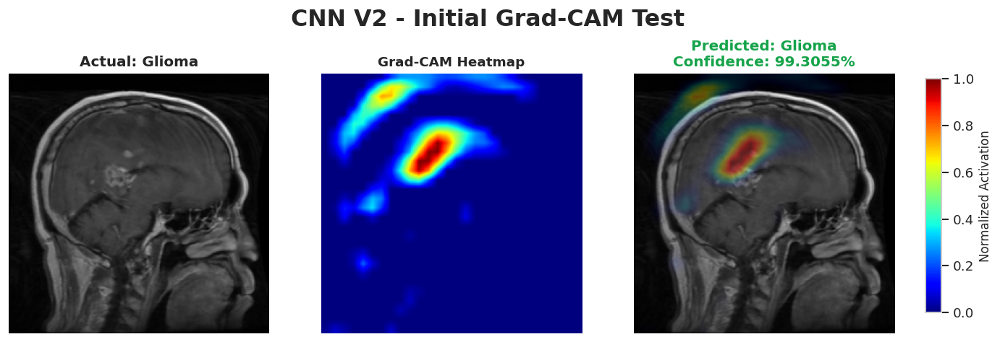

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/19_gradcam_initial_test.png

20.4 - CORRECT PREDICTIONS


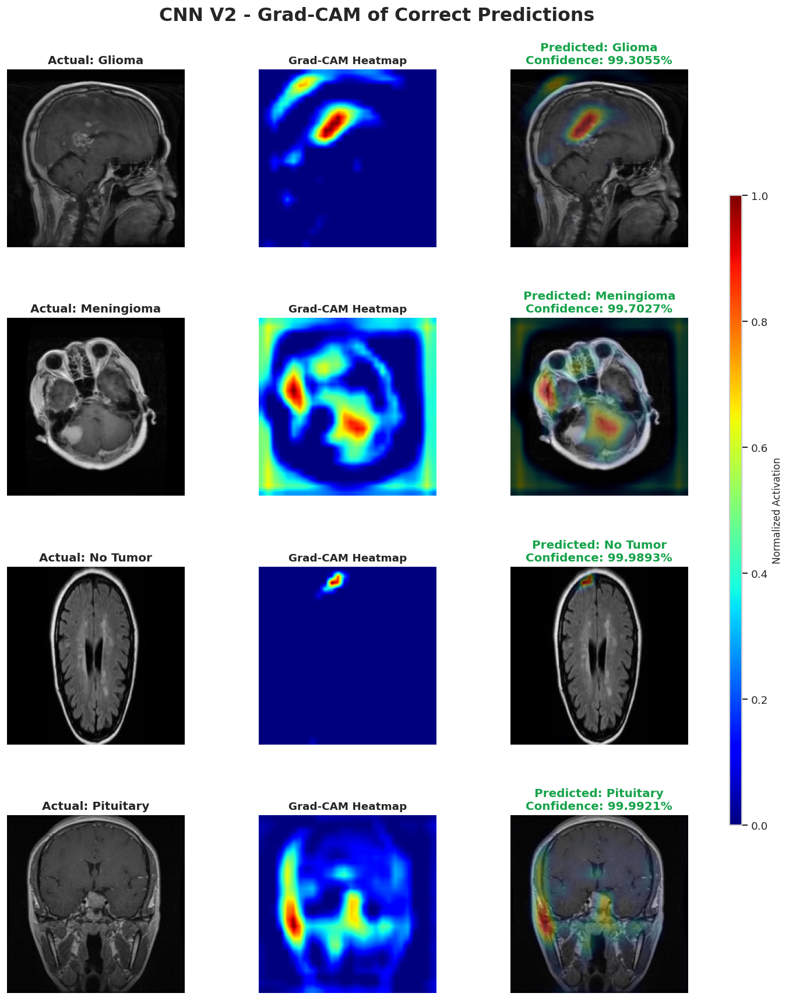

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/20_gradcam_correct_predictions.png

20.5 - INCORRECT PREDICTIONS


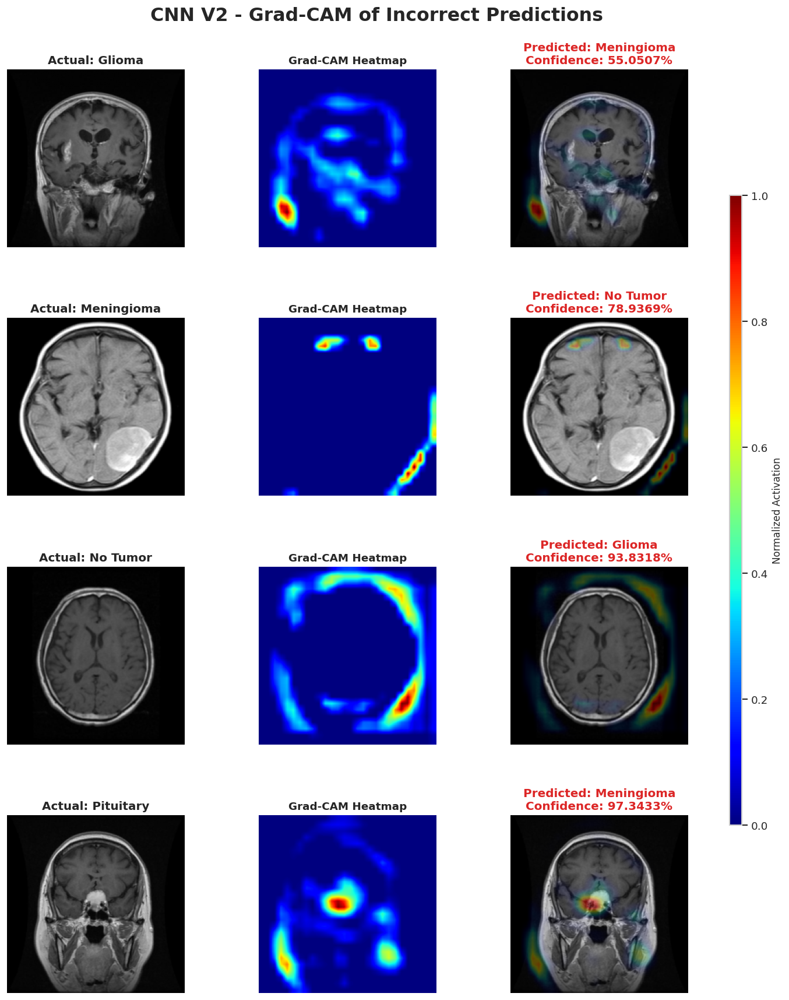

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/21_gradcam_incorrect_predictions.png

20.6 - HIGH CONFIDENCE ERRORS


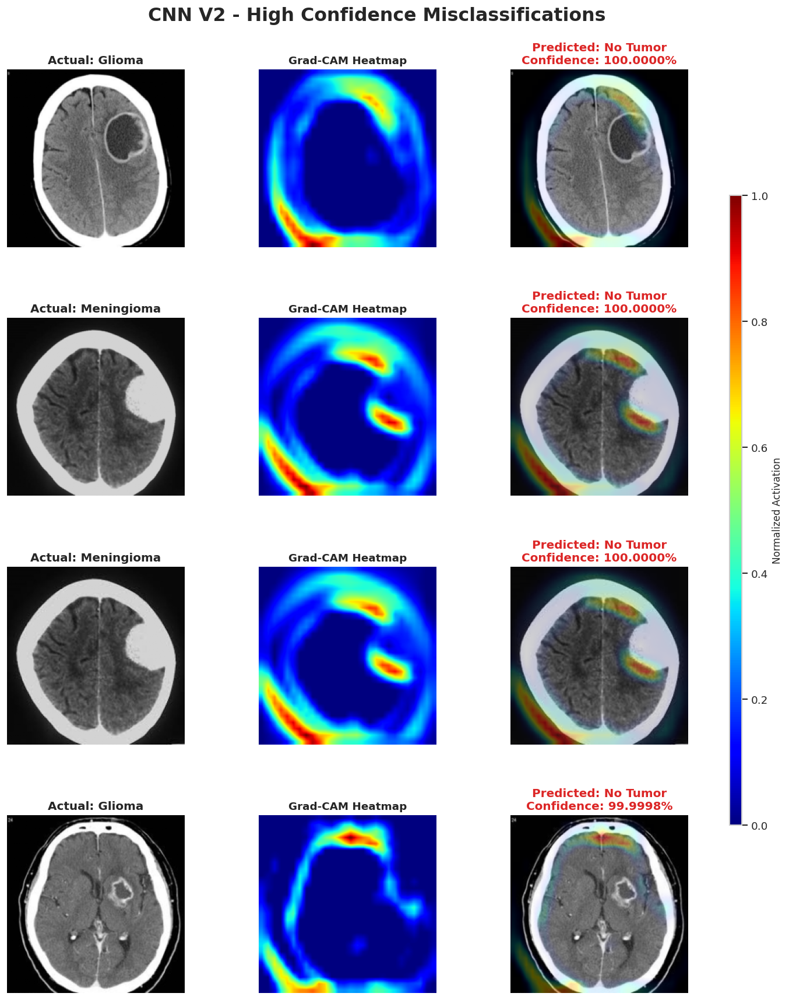

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/22_gradcam_high_confidence_errors.png

20.7 - PREDICTED VS ACTUAL CLASS ACTIVATION


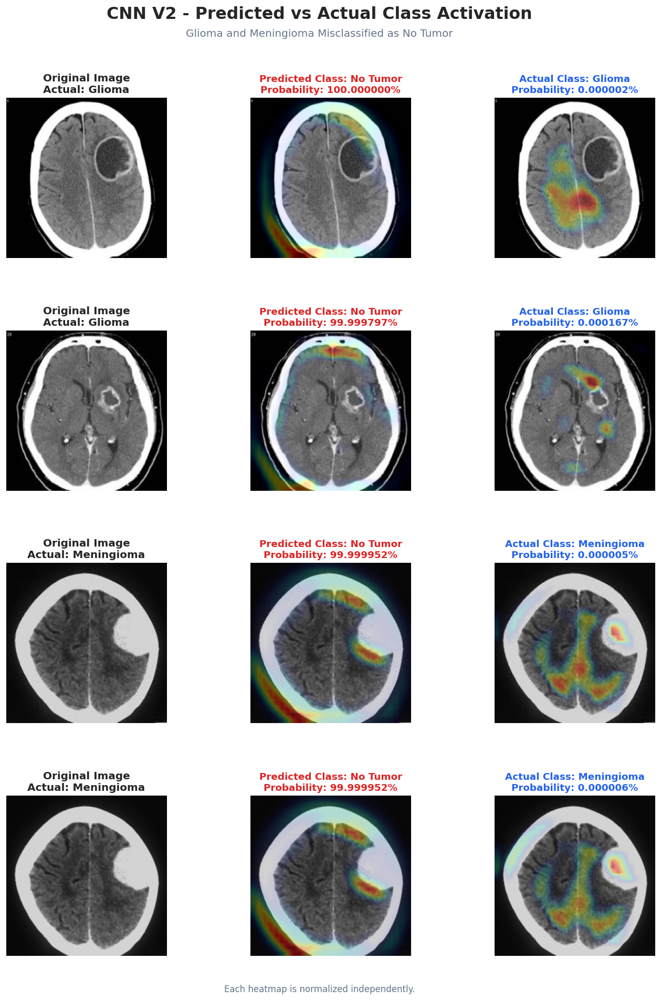

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/23_gradcam_class_comparison.png

CNN V2 - GRAD-CAM FINAL SUMMARY
Model: CNN_V2
Hedef katman: features.3.block.3
Toplam aktivasyon analizi: 21
Benzersiz görüntü sayısı: 12
Geçerli ısı haritaları: 21
Geçersiz veya sabit ısı haritaları: 0
Kayıtlı tahminle uyumlu: 21
Kayıtlı tahminle uyumsuz: 0
Kayıtlı olasılıklarla uyumsuz: 0

ANALİZ DAĞILIMI
-----------------------------------------------------------------


,analysis_type,Total_Analyses,Valid_Heatmaps,Matching_Predictions,Matching_Probabilities
0,comparison_actual_class,4,4,4,4
1,comparison_predicted_class,4,4,4,4
2,correct_predictions,4,4,4,4
3,high_confidence_errors,4,4,4,4
4,incorrect_predictions,4,4,4,4
5,initial_test,1,1,1,1


,analysis_type,image_path,actual_class,predicted_class,target_class,confidence,target_probability,correct,saved_prediction_match,saved_probabilities_match,valid_heatmap
0,initial_test,Testing/glioma/Te-gl_73.jpg,Glioma,Glioma,Glioma,0.993055,9.930554e-01,True,True,True,True
1,correct_predictions,Testing/glioma/Te-gl_73.jpg,Glioma,Glioma,Glioma,0.993055,9.930554e-01,True,True,True,True
2,correct_predictions,Testing/meningioma/Te-me_68.jpg,Meningioma,Meningioma,Meningioma,0.997027,9.970269e-01,True,True,True,True
3,correct_predictions,Testing/notumor/Te-no_274.jpg,No Tumor,No Tumor,No Tumor,0.999893,9.998934e-01,True,True,True,True
4,correct_predictions,Testing/pituitary/Te-pi_17.jpg,Pituitary,Pituitary,Pituitary,0.999921,9.999206e-01,True,True,True,True
5,incorrect_predictions,Testing/glioma/Te-gl_104.jpg,Glioma,Meningioma,Meningioma,0.550507,5.505066e-01,False,True,True,True
6,incorrect_predictions,Testing/meningioma/Te-me_262.jpg,Meningioma,No Tumor,No Tumor,0.789369,7.893689e-01,False,True,True,True
7,incorrect_predictions,Testing/notumor/Te-no_49.jpg,No Tumor,Glioma,Glioma,0.938318,9.383182e-01,False,True,True,True
8,incorrect_predictions,Testing/pituitary/Te-pi_206.jpg,Pituitary,Meningioma,Meningioma,0.973433,9.734330e-01,False,True,True,True
9,high_confidence_errors,Testing/glioma/Te-gl_74.jpg,Glioma,No Tumor,No Tumor,1.000000,1.000000e+00,False,True,True,True



DOSYA KONTROLÜ
-----------------------------------------------------------------
19_gradcam_initial_test.png                  : HAZIR
20_gradcam_correct_predictions.png           : HAZIR
21_gradcam_incorrect_predictions.png         : HAZIR
22_gradcam_high_confidence_errors.png        : HAZIR
23_gradcam_class_comparison.png              : HAZIR
gradcam_analysis.csv                         : HAZIR
gradcam_summary.csv                          : HAZIR

GRAD-CAM ANALİZİ TAMAMLANDI
Tüm dosyalar başarıyla kaydedildi.
Kayıt klasörü: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2
21. ADIM İÇİN HAZIR


In [35]:

# ============================================================
# CNN V2 - GRAD-CAM ANALYSIS
# 20.3 - 20.8 TÜM İŞLEMLER
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

IMAGE_SIZE = 224

gradcam_results = []

test_model.eval()

# Hücre yeniden çalıştırılırsa hook bağlantısını yenile

if "grad_cam" in globals():
    grad_cam.remove()

grad_cam = GradCAM(test_model, target_layer)

# ============================================================
# YARDIMCI FONKSİYONLAR
# ============================================================

def prepare_image(sample):

    image_path = Path(dataset_root) / sample["dosya"]

    with Image.open(image_path) as img:
        original_image = img.convert("L")

    image_tensor = (
        eval_transform(original_image)
        .unsqueeze(0)
        .to(device)
    )

    display_image = np.asarray(
        original_image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    ) / 255.0

    return display_image, image_tensor


def create_overlay(image, heatmap):

    image_rgb = np.stack(
        [image] * 3,
        axis=-1
    )

    heatmap_rgb = plt.get_cmap(
        "jet"
    )(heatmap)[..., :3]

    alpha = 0.50 * heatmap[..., None]

    overlay = np.clip(
        (1 - alpha) * image_rgb
        + alpha * heatmap_rgb,
        0, 1
    )

    return overlay


def hide_axis(ax):

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.axis("off")


def record_result(sample, result, analysis_type):

    actual_index = int(sample["true_index"])

    predicted_index = result["predicted_index"]

    saved_probabilities = np.array([
        sample["prob_glioma"],
        sample["prob_meningioma"],
        sample["prob_notumor"],
        sample["prob_pituitary"]
    ])

    gradcam_results.append({

        "analysis_type": analysis_type,

        "image_path": sample["dosya"],

        "actual_class": CLASS_NAMES[actual_index],

        "predicted_class":
            CLASS_NAMES[predicted_index],

        "target_class":
            CLASS_NAMES[result["target_index"]],

        "confidence": result["confidence"],

        "target_probability":
            result["target_probability"],

        "correct":
            actual_index == predicted_index,

        "saved_prediction_match":
            predicted_index == int(
                sample["predicted_index"]
            ),

        "saved_probabilities_match":
            np.allclose(
                result["probabilities"],
                saved_probabilities,
                atol=0.005
            ),

        "valid_heatmap":
            result["valid_heatmap"]

    })


# Genel Grad-CAM grafik fonksiyonu

def plot_gradcam_examples(
    samples,
    figure_title,
    file_name,
    analysis_type
):

    n = len(samples)

    fig, axes = plt.subplots(
        n,
        3,
        figsize=(12, 3.5 * n + 1),
        squeeze=False
    )

    for i, (_, sample) in enumerate(
        samples.iterrows()
    ):

        image, image_tensor = prepare_image(sample)

        result = grad_cam.generate(image_tensor)

        heatmap = result["heatmap"]

        overlay = create_overlay(
            image,
            heatmap
        )

        actual = sample["actual_class"]

        predicted = CLASS_NAMES[
            result["predicted_index"]
        ]

        result_color = (
            "#16A34A"
            if actual == predicted
            else "#DC2626"
        )

        # Orijinal görüntü

        axes[i, 0].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, 0].set_title(
            f"Actual: {actual}",
            fontsize=12,
            fontweight="bold"
        )

        # Aktivasyon haritası

        cam_plot = axes[i, 1].imshow(
            heatmap,
            cmap="jet",
            vmin=0,
            vmax=1
        )

        axes[i, 1].set_title(
            "Grad-CAM Heatmap"
            if result["valid_heatmap"]
            else "No Nonconstant Positive Map",
            fontsize=11,
            fontweight="bold"
        )

        # Birleştirilmiş görüntü

        axes[i, 2].imshow(overlay)

        axes[i, 2].set_title(
            f"Predicted: {predicted}\n"
            f"Confidence: {result['confidence']:.4%}",
            fontsize=12,
            fontweight="bold",
            color=result_color
        )

        for ax in axes[i]:
            hide_axis(ax)

        record_result(
            sample,
            result,
            analysis_type
        )

    fig.suptitle(
        figure_title,
        fontsize=19,
        fontweight="bold",
        y=0.98
    )

    fig.subplots_adjust(
        left=0.04,
        right=0.89,
        top=0.92,
        bottom=0.04,
        hspace=0.40,
        wspace=0.20
    )

    # Ortak renk ölçeği

    cbar_ax = fig.add_axes([
        0.92, 0.20, 0.015, 0.60
    ])

    cbar = fig.colorbar(
        cam_plot,
        cax=cbar_ax
    )

    cbar.set_label(
        "Normalized Activation",
        fontsize=10
    )

    grafik_kaydet(
        fig,
        file_name
    )


# ============================================================
# 20.3. İLK GRAD-CAM TESTİ
# ============================================================

print("=" * 65)
print("20.3 - INITIAL GRAD-CAM TEST")
print("=" * 65)

sample = correct_samples[
    correct_samples["actual_class"] == "Glioma"
].iloc[0]

image, image_tensor = prepare_image(sample)

result = grad_cam.generate(image_tensor)

assert result["heatmap"].shape == (224, 224)

saved_probabilities = np.array([
    sample["prob_glioma"],
    sample["prob_meningioma"],
    sample["prob_notumor"],
    sample["prob_pituitary"]
])

assert result["predicted_index"] == int(
    sample["predicted_index"]
), "Kayıtlı sınıf tahmini uyuşmuyor."

assert np.allclose(
    result["probabilities"],
    saved_probabilities,
    atol=0.005
), "Kayıtlı olasılıklar uyuşmuyor."

print("Gerçek sınıf:", sample["actual_class"])

print(
    "Tahmin:",
    CLASS_NAMES[result["predicted_index"]]
)

print(
    "Güven skoru:",
    f"{result['confidence']:.4%}"
)

print(
    "Heatmap boyutu:",
    result["heatmap"].shape
)

print(
    "Geçerli aktivasyon:",
    result["valid_heatmap"]
)

print("Kayıtlı model tahmini doğrulandı.")

plot_gradcam_examples(

    pd.DataFrame([sample]),

    "CNN V2 - Initial Grad-CAM Test",

    "19_gradcam_initial_test.png",

    "initial_test"
)


# ============================================================
# 20.4. DÖRT SINIF İÇİN DOĞRU TAHMİN ANALİZİ
# ============================================================

print("\n" + "=" * 65)
print("20.4 - CORRECT PREDICTIONS")
print("=" * 65)

correct_gradcam_samples = pd.concat([

    correct_samples[
        correct_samples["actual_class"] == name
    ].head(1)

    for name in CLASS_NAMES

], ignore_index=True)

plot_gradcam_examples(

    correct_gradcam_samples,

    "CNN V2 - Grad-CAM of Correct Predictions",

    "20_gradcam_correct_predictions.png",

    "correct_predictions"
)


# ============================================================
# 20.5. DÖRT SINIF İÇİN YANLIŞ TAHMİN ANALİZİ
# ============================================================

print("\n" + "=" * 65)
print("20.5 - INCORRECT PREDICTIONS")
print("=" * 65)

incorrect_gradcam_samples = pd.concat([

    incorrect_samples[
        incorrect_samples["actual_class"] == name
    ].head(1)

    for name in CLASS_NAMES

], ignore_index=True)

plot_gradcam_examples(

    incorrect_gradcam_samples,

    "CNN V2 - Grad-CAM of Incorrect Predictions",

    "21_gradcam_incorrect_predictions.png",

    "incorrect_predictions"
)


# ============================================================
# 20.6. YÜKSEK GÜVENLİ YANLIŞ TAHMİNLER
# ============================================================

print("\n" + "=" * 65)
print("20.6 - HIGH CONFIDENCE ERRORS")
print("=" * 65)

selected_errors = (
    high_confidence_errors
    .sort_values("confidence", ascending=False)
    .head(4)
    .reset_index(drop=True)
)

plot_gradcam_examples(

    selected_errors,

    "CNN V2 - High Confidence Misclassifications",

    "22_gradcam_high_confidence_errors.png",

    "high_confidence_errors"
)


# ============================================================
# 20.7. GERÇEK VE TAHMİN EDİLEN SINIF KARŞILAŞTIRMASI
# ============================================================

print("\n" + "=" * 65)
print("20.7 - PREDICTED VS ACTUAL CLASS ACTIVATION")
print("=" * 65)

# Yanlış tahmin tablosunu yeniden oluştur

incorrect_df = predictions_df[
    predictions_df["true_index"]
    != predictions_df["predicted_index"]
].copy()

# Glioma olup No Tumor tahmin edilen 2 görüntü
# Meningioma olup No Tumor tahmin edilen 2 görüntü

comparison_samples = pd.concat([

    incorrect_df[
        (incorrect_df["actual_class"] == "Glioma")
        &
        (incorrect_df["predicted_class"] == "No Tumor")
    ]
    .sort_values("confidence", ascending=False)
    .head(2),

    incorrect_df[
        (incorrect_df["actual_class"] == "Meningioma")
        &
        (incorrect_df["predicted_class"] == "No Tumor")
    ]
    .sort_values("confidence", ascending=False)
    .head(2)

], ignore_index=True)

assert len(comparison_samples) > 0

fig, axes = plt.subplots(

    len(comparison_samples),
    3,
    figsize=(
        14,
        3.8 * len(comparison_samples) + 1
    ),
    squeeze=False

)

for i, (_, sample) in enumerate(
    comparison_samples.iterrows()
):

    image, image_tensor = prepare_image(sample)

    # Modelin tahmin ettiği sınıfın aktivasyonu

    predicted_result = grad_cam.generate(
        image_tensor
    )

    # Gerçek sınıfın aktivasyonu

    actual_result = grad_cam.generate(
        image_tensor,
        target_class=int(sample["true_index"])
    )

    predicted_overlay = create_overlay(
        image,
        predicted_result["heatmap"]
    )

    actual_overlay = create_overlay(
        image,
        actual_result["heatmap"]
    )

    # Orijinal görüntü

    axes[i, 0].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i, 0].set_title(

        f"Original Image\n"
        f"Actual: {sample['actual_class']}",

        fontsize=12,
        fontweight="bold"

    )

    # Tahmin edilen sınıf

    axes[i, 1].imshow(
        predicted_overlay
    )

    predicted_note = (
        ""
        if predicted_result["valid_heatmap"]
        else "\nNo nonconstant positive map"
    )

    axes[i, 1].set_title(

        f"Predicted Class: "
        f"{CLASS_NAMES[predicted_result['target_index']]}\n"

        f"Probability: "
        f"{predicted_result['target_probability']:.6%}"
        f"{predicted_note}",

        fontsize=11,
        color="#DC2626",
        fontweight="bold"

    )

    # Gerçek sınıf

    axes[i, 2].imshow(
        actual_overlay
    )

    actual_note = (
        ""
        if actual_result["valid_heatmap"]
        else "\nNo nonconstant positive map"
    )

    axes[i, 2].set_title(

        f"Actual Class: {sample['actual_class']}\n"

        f"Probability: "
        f"{actual_result['target_probability']:.6%}"
        f"{actual_note}",

        fontsize=11,
        color="#2563EB",
        fontweight="bold"

    )

    for ax in axes[i]:
        hide_axis(ax)

    record_result(
        sample,
        predicted_result,
        "comparison_predicted_class"
    )

    record_result(
        sample,
        actual_result,
        "comparison_actual_class"
    )

fig.suptitle(

    "CNN V2 - Predicted vs Actual Class Activation",

    fontsize=19,
    fontweight="bold",
    y=0.98

)

fig.text(

    0.5,
    0.95,

    "Glioma and Meningioma Misclassified as No Tumor",

    ha="center",
    fontsize=12,
    color="#64748B"

)

fig.text(

    0.5,
    0.015,

    "Each heatmap is normalized independently.",

    ha="center",
    fontsize=10,
    color="#64748B"

)

fig.subplots_adjust(

    top=0.89,
    bottom=0.05,
    hspace=0.45,
    wspace=0.25

)

grafik_kaydet(
    fig,
    "23_gradcam_class_comparison.png"
)


# ============================================================
# 20.8. SONUÇLARIN KAYDEDİLMESİ
# ============================================================

gradcam_df = pd.DataFrame(
    gradcam_results
)

gradcam_csv_path = (
    sonuc_klasoru / "gradcam_analysis.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)

# ------------------------------------------------------------
# GENEL ÖZET TABLOSU
# ------------------------------------------------------------

gradcam_summary_df = (

    gradcam_df.groupby("analysis_type")

    .agg(

        Total_Analyses=(
            "image_path", "count"
        ),

        Valid_Heatmaps=(
            "valid_heatmap", "sum"
        ),

        Matching_Predictions=(
            "saved_prediction_match", "sum"
        ),

        Matching_Probabilities=(
            "saved_probabilities_match", "sum"
        )

    )

    .reset_index()

)

gradcam_summary_df.to_csv(

    sonuc_klasoru / "gradcam_summary.csv",

    index=False

)

# ------------------------------------------------------------
# GENEL SONUÇLAR
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CNN V2 - GRAD-CAM FINAL SUMMARY")
print("=" * 65)

print("Model: CNN_V2")

print(
    "Hedef katman:",
    target_layer_name
)

print(
    "Toplam aktivasyon analizi:",
    len(gradcam_df)
)

print(
    "Benzersiz görüntü sayısı:",
    gradcam_df["image_path"].nunique()
)

print(
    "Geçerli ısı haritaları:",
    int(gradcam_df["valid_heatmap"].sum())
)

print(
    "Geçersiz veya sabit ısı haritaları:",
    int((~gradcam_df["valid_heatmap"]).sum())
)

print(
    "Kayıtlı tahminle uyumlu:",
    int(gradcam_df["saved_prediction_match"].sum())
)

print(
    "Kayıtlı tahminle uyumsuz:",
    int((~gradcam_df["saved_prediction_match"]).sum())
)

print(
    "Kayıtlı olasılıklarla uyumsuz:",
    int((~gradcam_df["saved_probabilities_match"]).sum())
)

print("\nANALİZ DAĞILIMI")
print("-" * 65)

display(gradcam_summary_df)

display(gradcam_df)

# ------------------------------------------------------------
# DOSYA KONTROLÜ
# ------------------------------------------------------------

required_files = [

    "19_gradcam_initial_test.png",

    "20_gradcam_correct_predictions.png",

    "21_gradcam_incorrect_predictions.png",

    "22_gradcam_high_confidence_errors.png",

    "23_gradcam_class_comparison.png",

    "gradcam_analysis.csv",

    "gradcam_summary.csv"

]

print("\nDOSYA KONTROLÜ")
print("-" * 65)

for file_name in required_files:

    path = sonuc_klasoru / file_name

    print(

        f"{file_name:45s}: "

        f"{'HAZIR' if path.is_file() else 'EKSİK'}"

    )

all_files_ready = all(

    (sonuc_klasoru / file_name).is_file()

    for file_name in required_files

)

# Hook temizliği

grad_cam.remove()

assert all_files_ready, "Eksik çıktı dosyaları var."

print("\n" + "=" * 65)

if gradcam_df["saved_prediction_match"].all() and \
   gradcam_df["saved_probabilities_match"].all():

    print("GRAD-CAM ANALİZİ TAMAMLANDI")

else:

    print("GRAD-CAM ANALİZİ KAYDEDİLDİ")
    print("UYARI: Tahmin uyumsuzlukları incelenmeli.")

print("Tüm dosyalar başarıyla kaydedildi.")

print("Kayıt klasörü:", sonuc_klasoru)

print("21. ADIM İÇİN HAZIR")

print("=" * 65)


CNN V2 - FINAL PERFORMANCE ANALYSIS

21.1 - Kayıtlı sonuçlar yüklendi.
Toplam epoch: 40
Test görüntüsü: 1579
Grad-CAM analizi: 21

History sütunları:
['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy', 'train_precision', 'val_precision', 'train_recall', 'val_recall', 'train_f1', 'val_f1', 'learning_rate', 'next_learning_rate', 'train_time', 'val_time', 'epoch_time', 'early_stopping_counter', 'is_best']

Model sonuçları başarıyla hesaplandı.

21.2 - DATASET PERFORMANCE
----------------------------------------------------------------------


,Dataset,Images,Accuracy (%),Loss
0,Training,3870,95.1680,0.1267
1,Validation,994,96.6801,0.1023
2,Testing,1579,89.6137,0.5028


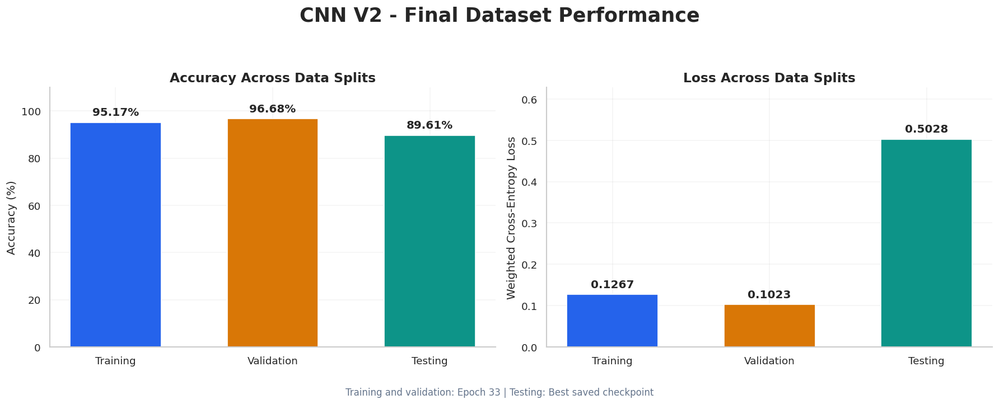

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/24_final_dataset_performance.png

21.3 - GENERALIZATION ANALYSIS
----------------------------------------------------------------------


,Comparison,Accuracy Gap (pp)
0,Training - Validation,-1.5121
1,Validation - Testing,7.0664
2,Training - Testing,5.5543


Test - Validation Loss: 0.4005


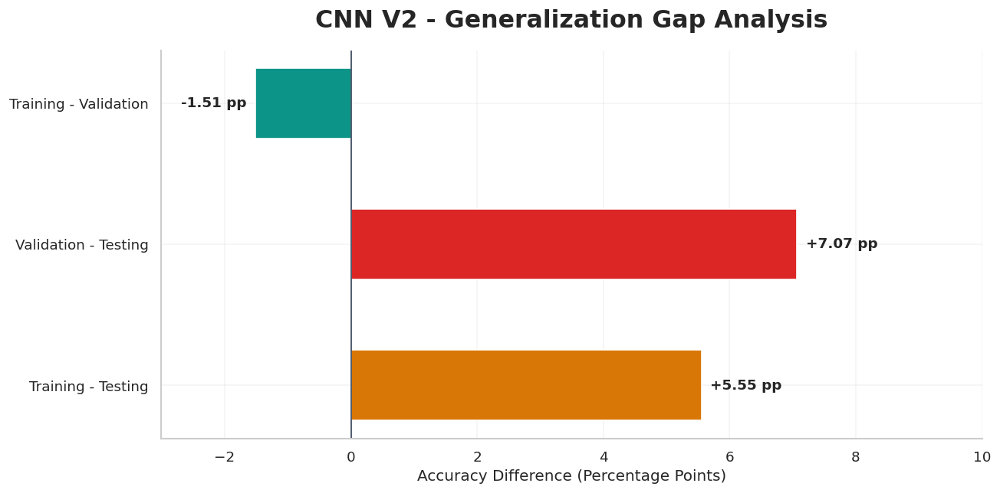

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/25_generalization_gap_analysis.png

21.4 - CNN MODEL COMPARISON
----------------------------------------------------------------------


,Metric,CNN V1 (%),CNN V2 (%),Difference (pp)
0,Accuracy,76.75,89.61,12.86
1,Macro Precision,79.85,91.06,11.21
2,Macro Recall,76.75,89.49,12.74
3,Macro F1-Score,75.88,89.55,13.67


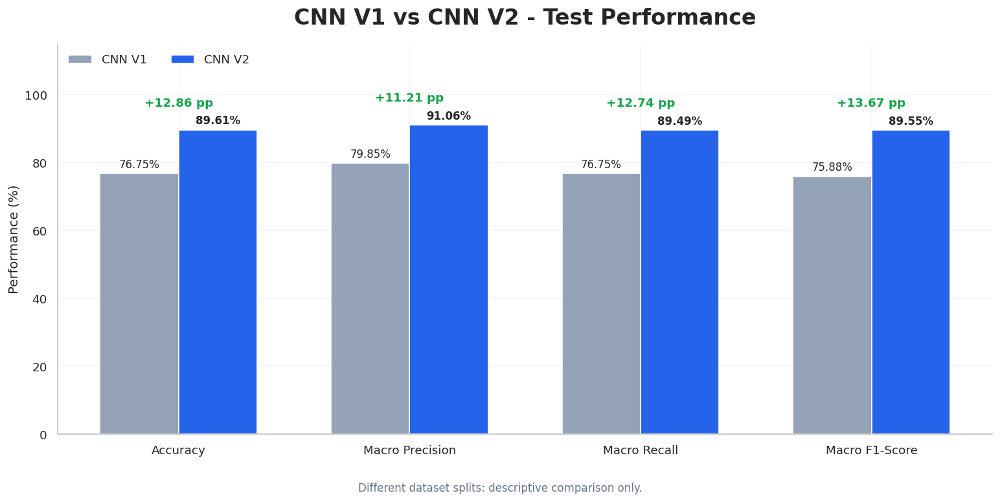

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/26_cnn_v1_v2_performance_comparison.png

21.5 - CLASS LEVEL COMPARISON
----------------------------------------------------------------------


,Class,CNN V1 Recall (%),CNN V2 Recall (%),Difference (pp)
0,Glioma,55.00,80.94,25.94
1,Meningioma,58.75,78.54,19.79
2,No Tumor,100.00,99.75,-0.25
3,Pituitary,93.25,98.75,5.50


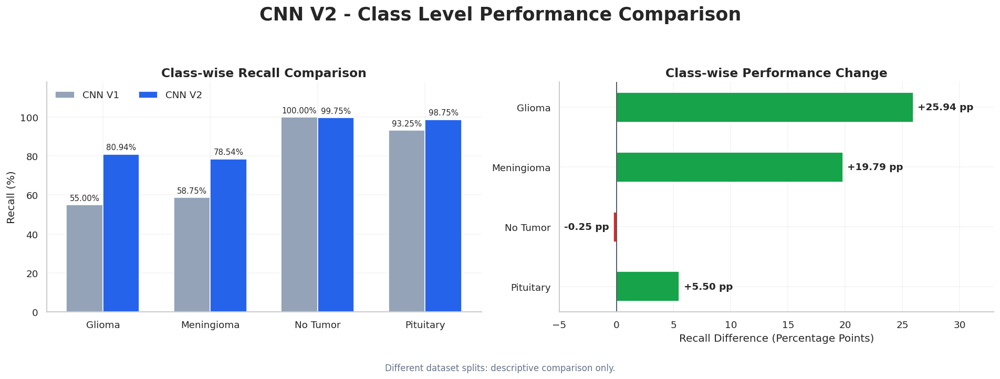

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/27_class_level_performance_comparison.png


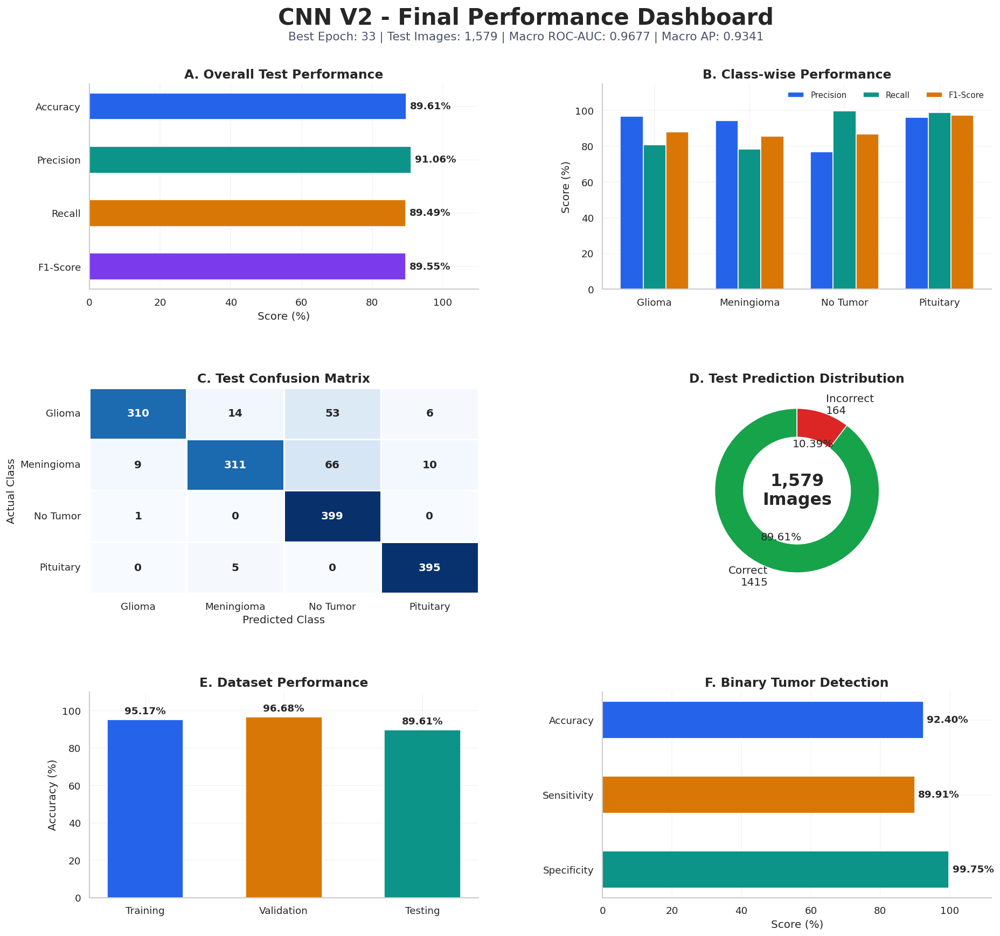

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/28_final_performance_dashboard.png

21.7 - MODEL ASSESSMENT
----------------------------------------------------------------------


,Category,Description
0,Strength,Higher observed test accuracy than CNN V1.
1,Strength,Reduced cross-split image duplication.
2,Strength,More stable validation performance in later ep...
3,Strength,High recall for No Tumor and Pituitary classes.
4,Strength,Strong macro ROC-AUC and average precision.
5,Strength,Reproducible predictions from the saved checkp...
6,Strength,Grad-CAM-based qualitative explainability.
7,Limitation,CNN V1 and CNN V2 use different dataset splits.
8,Limitation,Validation-to-test accuracy gap remains.
9,Limitation,Glioma and Meningioma have lower recall.



CNN V2 - FINAL PERFORMANCE SUMMARY

MODEL INFORMATION
----------------------------------------------------------------------
Model: CNN_V2
Best Epoch: 33
Parameters: 3,337,764

DATASET PERFORMANCE
----------------------------------------------------------------------
Training Accuracy:   95.17%
Validation Accuracy: 96.68%
Testing Accuracy:    89.61%
Training Loss:       0.1267
Validation Loss:     0.1023
Testing Loss:        0.5028

TEST METRICS
----------------------------------------------------------------------
Macro Precision: 91.06%
Macro Recall:    89.49%
Macro F1-Score:  89.55%
Macro ROC-AUC:   0.9677
Macro AP:        0.9341

GENERALIZATION
----------------------------------------------------------------------
Train - Validation: -1.51 pp
Validation - Test:  +7.07 pp
Train - Test:       +5.55 pp

CNN V1 - CNN V2
----------------------------------------------------------------------
CNN V1 Accuracy: 76.75%
CNN V2 Accuracy: 89.61%
Observed Difference: +12.86 pp

PREDICTION ANALY

In [36]:

# ============================================================
# 21. CNN V2 - FINAL PERFORMANCE ANALYSIS
# 21.1 - 21.8 TÜM İŞLEMLER
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# GRAFİK AYARLARI
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "figure.facecolor": "white"
})

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

CLASS_COLORS = [
    "#2563EB",
    "#0D9488",
    "#D97706",
    "#7C3AED"
]

SPLIT_COLORS = [
    "#2563EB",
    "#D97706",
    "#0D9488"
]

V1_COLOR = "#94A3B8"
V2_COLOR = "#2563EB"

BEST_EPOCH = 33

print("=" * 70)
print("CNN V2 - FINAL PERFORMANCE ANALYSIS")
print("=" * 70)

# ============================================================
# 21.1. KAYDEDİLMİŞ SONUÇLARIN YÜKLENMESİ
# ============================================================

history_df = pd.read_csv(
    sonuc_klasoru / "training_history.csv"
)

with open(
    sonuc_klasoru / "test_metrics.json",
    "r",
    encoding="utf-8"
) as f:
    test_results = json.load(f)

with np.load(
    sonuc_klasoru / "test_predictions.npz"
) as saved:

    y_true = saved["y_true"]
    y_pred = saved["y_pred"]
    y_prob = saved["y_prob"]

gradcam_df = pd.read_csv(
    sonuc_klasoru / "gradcam_analysis.csv"
)

assert len(y_true) == 1579

assert y_prob.shape == (1579, 4)

assert len(history_df) == 40

print("\n21.1 - Kayıtlı sonuçlar yüklendi.")

print("Toplam epoch:", len(history_df))

print("Test görüntüsü:", len(y_true))

print("Grad-CAM analizi:", len(gradcam_df))

print("\nHistory sütunları:")
print(history_df.columns.tolist())

# ------------------------------------------------------------
# HISTORY SÜTUNLARINI GÜVENLİ ŞEKİLDE BUL
# ------------------------------------------------------------

def find_column(df, candidates):

    normalized = {
        str(col).strip().lower(): col
        for col in df.columns
    }

    for candidate in candidates:

        if candidate.lower() in normalized:

            return normalized[candidate.lower()]

    raise KeyError(
        f"Sütun bulunamadı: {candidates}"
    )


epoch_col = find_column(
    history_df,
    ["epoch", "epochs"]
)

train_acc_col = find_column(
    history_df,
    ["train_acc", "train_accuracy", "training_accuracy"]
)

val_acc_col = find_column(
    history_df,
    ["val_acc", "val_accuracy", "validation_accuracy"]
)

train_loss_col = find_column(
    history_df,
    ["train_loss", "training_loss"]
)

val_loss_col = find_column(
    history_df,
    ["val_loss", "validation_loss"]
)

best_row = history_df[
    history_df[epoch_col] == BEST_EPOCH
].iloc[0]

# Oranları yüzde biçimine dönüştür

def to_percent(value):

    value = float(value)

    return value * 100 if value <= 1 else value


train_accuracy = to_percent(
    best_row[train_acc_col]
)

val_accuracy = to_percent(
    best_row[val_acc_col]
)

test_accuracy = accuracy_score(
    y_true, y_pred
) * 100

train_loss = float(
    best_row[train_loss_col]
)

val_loss = float(
    best_row[val_loss_col]
)

test_loss = float(
    test_results["test_loss"]
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
) * 100

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
) * 100

test_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
) * 100

macro_auc = roc_auc_score(
    y_true,
    y_prob,
    average="macro",
    multi_class="ovr"
)

y_true_binary = np.eye(4)[y_true]

macro_ap = average_precision_score(
    y_true_binary,
    y_prob,
    average="macro"
)

correct_count = int(
    (y_true == y_pred).sum()
)

incorrect_count = int(
    (y_true != y_pred).sum()
)

print("\nModel sonuçları başarıyla hesaplandı.")

# ============================================================
# 21.2. TRAINING - VALIDATION - TESTING KARŞILAŞTIRMASI
# ============================================================

split_performance_df = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],

    "Images": [
        len(train_df),
        len(val_df),
        len(y_true)
    ],

    "Accuracy (%)": [
        train_accuracy,
        val_accuracy,
        test_accuracy
    ],

    "Loss": [
        train_loss,
        val_loss,
        test_loss
    ]

})

print("\n21.2 - DATASET PERFORMANCE")
print("-" * 70)

display(split_performance_df.round(4))

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

# Accuracy

bars = axes[0].bar(
    split_performance_df["Dataset"],
    split_performance_df["Accuracy (%)"],
    color=SPLIT_COLORS,
    width=0.58
)

axes[0].set_title(
    "Accuracy Across Data Splits"
)

axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 110)

axes[0].bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=12,
    fontweight="bold"
)

axes[0].set_axisbelow(True)

# Loss

bars = axes[1].bar(
    split_performance_df["Dataset"],
    split_performance_df["Loss"],
    color=SPLIT_COLORS,
    width=0.58
)

axes[1].set_title(
    "Loss Across Data Splits"
)

axes[1].set_ylabel("Weighted Cross-Entropy Loss")

axes[1].set_ylim(
    0,
    split_performance_df["Loss"].max() * 1.25
)

axes[1].bar_label(
    bars,
    fmt="%.4f",
    padding=5,
    fontsize=12,
    fontweight="bold"
)

axes[1].set_axisbelow(True)

fig.suptitle(
    "CNN V2 - Final Dataset Performance",
    fontsize=21,
    fontweight="bold"
)

fig.text(
    0.5,
    0.015,
    "Training and validation: Epoch 33 | "
    "Testing: Best saved checkpoint",
    ha="center",
    fontsize=10,
    color="#64748B"
)

fig.tight_layout(
    rect=[0, 0.06, 1, 0.92]
)

grafik_kaydet(
    fig,
    "24_final_dataset_performance.png"
)

# ============================================================
# 21.3. GENELLEME PERFORMANSI
# ============================================================

train_val_gap = (
    train_accuracy - val_accuracy
)

val_test_gap = (
    val_accuracy - test_accuracy
)

train_test_gap = (
    train_accuracy - test_accuracy
)

val_test_loss_gap = (
    test_loss - val_loss
)

generalization_df = pd.DataFrame({

    "Comparison": [
        "Training - Validation",
        "Validation - Testing",
        "Training - Testing"
    ],

    "Accuracy Gap (pp)": [
        train_val_gap,
        val_test_gap,
        train_test_gap
    ]

})

print("\n21.3 - GENERALIZATION ANALYSIS")
print("-" * 70)

display(generalization_df.round(4))

print(
    "Test - Validation Loss:",
    round(val_test_loss_gap, 4)
)

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

gap_values = generalization_df[
    "Accuracy Gap (pp)"
]

bars = ax.barh(

    generalization_df["Comparison"],

    gap_values,

    color=[
        "#0D9488",
        "#DC2626",
        "#D97706"
    ],

    height=0.50

)

ax.axvline(
    0,
    color="#334155",
    linewidth=1
)

ax.bar_label(
    bars,
    fmt="%+.2f pp",
    padding=7,
    fontweight="bold"
)

ax.set_xlim(
    min(-3, gap_values.min() - 1.5),
    max(10, gap_values.max() + 2)
)

ax.invert_yaxis()

ax.set_xlabel(
    "Accuracy Difference (Percentage Points)"
)

ax.set_title(
    "CNN V2 - Generalization Gap Analysis",
    fontsize=19,
    pad=18
)

ax.set_axisbelow(True)

fig.tight_layout()

grafik_kaydet(
    fig,
    "25_generalization_gap_analysis.png"
)

# ============================================================
# 21.4. CNN V1 - CNN V2 KARŞILAŞTIRMASI
# ============================================================

# Önceki CNN V1 deneyinden kayıtlı sonuçlar
# Yüzde değerleri kullanılmıştır.

cnn_v1_metrics = {

    "Accuracy": 76.75,
    "Macro Precision": 79.85,
    "Macro Recall": 76.75,
    "Macro F1-Score": 75.88

}

cnn_v2_metrics = {

    "Accuracy": test_accuracy,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1-Score": test_f1

}

model_comparison_df = pd.DataFrame({

    "Metric": list(cnn_v1_metrics.keys()),

    "CNN V1 (%)": list(
        cnn_v1_metrics.values()
    ),

    "CNN V2 (%)": list(
        cnn_v2_metrics.values()
    )

})

model_comparison_df["Difference (pp)"] = (

    model_comparison_df["CNN V2 (%)"]

    - model_comparison_df["CNN V1 (%)"]

)

print("\n21.4 - CNN MODEL COMPARISON")
print("-" * 70)

display(model_comparison_df.round(2))

x = np.arange(
    len(model_comparison_df)
)

width = 0.34

fig, ax = plt.subplots(
    figsize=(13, 6.5)
)

bars_v1 = ax.bar(

    x - width / 2,

    model_comparison_df["CNN V1 (%)"],

    width,

    label="CNN V1",

    color=V1_COLOR

)

bars_v2 = ax.bar(

    x + width / 2,

    model_comparison_df["CNN V2 (%)"],

    width,

    label="CNN V2",

    color=V2_COLOR

)

ax.bar_label(
    bars_v1,
    fmt="%.2f%%",
    padding=3,
    fontsize=10
)

ax.bar_label(
    bars_v2,
    fmt="%.2f%%",
    padding=3,
    fontsize=10,
    fontweight="bold"
)

for i, improvement in enumerate(
    model_comparison_df["Difference (pp)"]
):

    ax.text(

        i,

        max(
            model_comparison_df.loc[i, "CNN V1 (%)"],
            model_comparison_df.loc[i, "CNN V2 (%)"]
        ) + 7,

        f"{improvement:+.2f} pp",

        ha="center",
        fontsize=11,
        color="#16A34A",
        fontweight="bold"

    )

ax.set_xticks(x)

ax.set_xticklabels(
    model_comparison_df["Metric"]
)

ax.set_ylabel("Performance (%)")

ax.set_ylim(0, 115)

ax.set_title(
    "CNN V1 vs CNN V2 - Test Performance",
    fontsize=20,
    pad=18
)

ax.legend(
    loc="upper left",
    ncol=2,
    frameon=False
)

ax.set_axisbelow(True)

fig.text(
    0.5,
    0.015,
    "Different dataset splits: descriptive comparison only.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

fig.tight_layout(
    rect=[0, 0.06, 1, 1]
)

grafik_kaydet(
    fig,
    "26_cnn_v1_v2_performance_comparison.png"
)

# ============================================================
# 21.5. SINIF BAZLI GELİŞİM ANALİZİ
# ============================================================

v1_class_recall = np.array([

    55.00,
    58.75,
    100.00,
    93.25

])

v2_class_recall = recall_score(

    y_true,

    y_pred,

    labels=[0, 1, 2, 3],

    average=None,

    zero_division=0

) * 100

class_comparison_df = pd.DataFrame({

    "Class": CLASS_NAMES,

    "CNN V1 Recall (%)": v1_class_recall,

    "CNN V2 Recall (%)": v2_class_recall

})

class_comparison_df["Difference (pp)"] = (

    v2_class_recall - v1_class_recall

)

print("\n21.5 - CLASS LEVEL COMPARISON")
print("-" * 70)

display(class_comparison_df.round(2))

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

x = np.arange(4)

bars1 = axes[0].bar(

    x - width / 2,

    v1_class_recall,

    width,

    label="CNN V1",

    color=V1_COLOR

)

bars2 = axes[0].bar(

    x + width / 2,

    v2_class_recall,

    width,

    label="CNN V2",

    color=V2_COLOR

)

axes[0].bar_label(
    bars1,
    fmt="%.2f%%",
    fontsize=9,
    padding=3
)

axes[0].bar_label(
    bars2,
    fmt="%.2f%%",
    fontsize=9,
    padding=3
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(CLASS_NAMES)

axes[0].set_ylim(0, 118)

axes[0].set_ylabel("Recall (%)")

axes[0].set_title(
    "Class-wise Recall Comparison"
)

axes[0].legend(
    loc="upper left",
    ncol=2,
    frameon=False
)

# Sınıf bazlı farklar

differences = class_comparison_df[
    "Difference (pp)"
]

bars = axes[1].barh(

    CLASS_NAMES,

    differences,

    color=[
        "#16A34A" if value >= 0
        else "#DC2626"
        for value in differences
    ],

    height=0.5

)

axes[1].axvline(
    0,
    color="#334155",
    linewidth=1
)

axes[1].bar_label(
    bars,
    fmt="%+.2f pp",
    padding=5,
    fontsize=11,
    fontweight="bold"
)

axes[1].set_xlim(-5, 33)

axes[1].invert_yaxis()

axes[1].set_xlabel(
    "Recall Difference (Percentage Points)"
)

axes[1].set_title(
    "Class-wise Performance Change"
)

for ax in axes:
    ax.set_axisbelow(True)

fig.suptitle(
    "CNN V2 - Class Level Performance Comparison",
    fontsize=21,
    fontweight="bold"
)

fig.text(
    0.5,
    0.015,
    "Different dataset splits: descriptive comparison only.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

fig.tight_layout(
    rect=[0, 0.06, 1, 0.92]
)

grafik_kaydet(
    fig,
    "27_class_level_performance_comparison.png"
)

# ============================================================
# 21.6. CNN V2 GENEL PERFORMANS PANELİ
# ============================================================

cm = confusion_matrix(

    y_true,
    y_pred,
    labels=[0, 1, 2, 3]

)

class_precision = precision_score(

    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    average=None,
    zero_division=0

) * 100

class_f1 = f1_score(

    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    average=None,
    zero_division=0

) * 100

confidence = y_prob.max(axis=1)

correct_mask = y_true == y_pred

mean_correct_confidence = float(
    confidence[correct_mask].mean() * 100
)

mean_incorrect_confidence = float(
    confidence[~correct_mask].mean() * 100
)

high_confidence_error_count = int(
    (
        (~correct_mask)
        &
        (confidence >= 0.90)
    ).sum()
)

# Tumor vs No Tumor

actual_tumor = y_true != 2
predicted_tumor = y_pred != 2

tn, fp, fn, tp = confusion_matrix(

    actual_tumor,
    predicted_tumor,
    labels=[False, True]

).ravel()

tumor_sensitivity = (
    tp / (tp + fn) * 100
)

tumor_specificity = (
    tn / (tn + fp) * 100
)

tumor_accuracy = (
    (tp + tn) / len(y_true) * 100
)

fig = plt.figure(
    figsize=(18, 15)
)

gs = fig.add_gridspec(
    3, 2,
    hspace=0.48,
    wspace=0.32
)

# ------------------------------------------------------------
# PANEL 1 - TEST METRİKLERİ
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[0, 0])

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

metric_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1
]

bars = ax1.barh(

    metric_names,

    metric_values,

    color=[
        "#2563EB",
        "#0D9488",
        "#D97706",
        "#7C3AED"
    ],

    height=0.5

)

ax1.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4,
    fontweight="bold"
)

ax1.set_xlim(0, 110)
ax1.invert_yaxis()

ax1.set_title(
    "A. Overall Test Performance"
)

ax1.set_xlabel("Score (%)")

# ------------------------------------------------------------
# PANEL 2 - SINIF PERFORMANSI
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[0, 1])

x = np.arange(4)

w = 0.24

ax2.bar(

    x - w,
    class_precision,
    w,
    label="Precision",
    color="#2563EB"

)

ax2.bar(

    x,
    v2_class_recall,
    w,
    label="Recall",
    color="#0D9488"

)

ax2.bar(

    x + w,
    class_f1,
    w,
    label="F1-Score",
    color="#D97706"

)

ax2.set_xticks(x)

ax2.set_xticklabels(CLASS_NAMES)

ax2.set_ylim(0, 115)

ax2.set_ylabel("Score (%)")

ax2.set_title(
    "B. Class-wise Performance"
)

ax2.legend(
    ncol=3,
    frameon=False,
    fontsize=9
)

# ------------------------------------------------------------
# PANEL 3 - CONFUSION MATRIX
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[1, 0])

sns.heatmap(

    cm,

    annot=True,
    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,

    cbar=False,

    linewidths=0.7,

    annot_kws={
        "fontsize": 12,
        "fontweight": "bold"
    },

    ax=ax3

)

ax3.set_title(
    "C. Test Confusion Matrix"
)

ax3.set_xlabel("Predicted Class")
ax3.set_ylabel("Actual Class")

ax3.tick_params(
    axis="x",
    rotation=0
)

ax3.tick_params(
    axis="y",
    rotation=0
)

# ------------------------------------------------------------
# PANEL 4 - DOĞRU VE YANLIŞ TAHMİNLER
# ------------------------------------------------------------

ax4 = fig.add_subplot(gs[1, 1])

ax4.pie(

    [correct_count, incorrect_count],

    labels=[
        f"Correct\n{correct_count}",
        f"Incorrect\n{incorrect_count}"
    ],

    colors=[
        "#16A34A",
        "#DC2626"
    ],

    autopct="%.2f%%",

    startangle=90,

    wedgeprops={
        "width": 0.35,
        "edgecolor": "white"
    },

    textprops={
        "fontsize": 12
    }

)

ax4.text(

    0, 0,

    f"{len(y_true):,}\nImages",

    ha="center",
    va="center",
    fontsize=19,
    fontweight="bold"

)

ax4.set_title(
    "D. Test Prediction Distribution"
)

# ------------------------------------------------------------
# PANEL 5 - VERİ BÖLÜMLERİ
# ------------------------------------------------------------

ax5 = fig.add_subplot(gs[2, 0])

bars = ax5.bar(

    ["Training", "Validation", "Testing"],

    [
        train_accuracy,
        val_accuracy,
        test_accuracy
    ],

    color=SPLIT_COLORS,

    width=0.55

)

ax5.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4,
    fontweight="bold"
)

ax5.set_ylim(0, 110)
ax5.set_ylabel("Accuracy (%)")

ax5.set_title(
    "E. Dataset Performance"
)

# ------------------------------------------------------------
# PANEL 6 - TUMOR DETECTION
# ------------------------------------------------------------

ax6 = fig.add_subplot(gs[2, 1])

binary_names = [
    "Accuracy",
    "Sensitivity",
    "Specificity"
]

binary_values = [
    tumor_accuracy,
    tumor_sensitivity,
    tumor_specificity
]

bars = ax6.barh(

    binary_names,

    binary_values,

    color=[
        "#2563EB",
        "#D97706",
        "#0D9488"
    ],

    height=0.5

)

ax6.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4,
    fontweight="bold"
)

ax6.set_xlim(0, 112)
ax6.invert_yaxis()

ax6.set_xlabel("Score (%)")

ax6.set_title(
    "F. Binary Tumor Detection"
)

for ax in [
    ax1, ax2, ax5, ax6
]:
    ax.set_axisbelow(True)

fig.suptitle(

    "CNN V2 - Final Performance Dashboard",

    fontsize=25,

    fontweight="bold",

    y=0.98

)

fig.text(

    0.5,

    0.945,

    "Best Epoch: 33 | "
    "Test Images: 1,579 | "
    "Macro ROC-AUC: "
    f"{macro_auc:.4f} | "
    "Macro AP: "
    f"{macro_ap:.4f}",

    ha="center",

    fontsize=13,

    color="#475569"

)

fig.subplots_adjust(
    top=0.90,
    bottom=0.06
)

grafik_kaydet(
    fig,
    "28_final_performance_dashboard.png"
)

# ============================================================
# 21.7. MODELİN GÜÇLÜ YÖNLERİ VE SINIRLILIKLARI
# ============================================================

strengths = [

    "Higher observed test accuracy than CNN V1.",

    "Reduced cross-split image duplication.",

    "More stable validation performance in later epochs.",

    "High recall for No Tumor and Pituitary classes.",

    "Strong macro ROC-AUC and average precision.",

    "Reproducible predictions from the saved checkpoint.",

    "Grad-CAM-based qualitative explainability."

]

limitations = [

    "CNN V1 and CNN V2 use different dataset splits.",

    "Validation-to-test accuracy gap remains.",

    "Glioma and Meningioma have lower recall.",

    "Some tumor images are classified as No Tumor.",

    "High-confidence incorrect predictions are present.",

    "Grad-CAM shows activation outside relevant brain regions.",

    "Possible mixed CT and MRI images require verification.",

    "Potential near-duplicates remain within the test split.",

    "Patient-level independence cannot be verified.",

    "Test data was used in previous exploratory analyses.",

    "No independent external clinical validation.",

    "Grad-CAM is not a validated tumor segmentation method."

]

assessment_df = pd.DataFrame(

    [
        {
            "Category": "Strength",
            "Description": item
        }
        for item in strengths
    ]

    +

    [
        {
            "Category": "Limitation",
            "Description": item
        }
        for item in limitations
    ]

)

print("\n21.7 - MODEL ASSESSMENT")
print("-" * 70)

display(assessment_df)

# ============================================================
# 21.8. NİHAİ SONUÇLARIN KAYDEDİLMESİ
# ============================================================

final_summary = {

    "model_name": "CNN_V2",

    "dataset_version": "veri_bolunmesi_v3",

    "best_epoch": BEST_EPOCH,

    "total_epochs": len(history_df),

    "total_parameters": 3337764,

    "training_images": len(train_df),

    "validation_images": len(val_df),

    "testing_images": len(y_true),

    "training_accuracy_percent": train_accuracy,

    "validation_accuracy_percent": val_accuracy,

    "test_accuracy_percent": test_accuracy,

    "training_loss": train_loss,

    "validation_loss": val_loss,

    "test_loss": test_loss,

    "macro_precision_percent": test_precision,

    "macro_recall_percent": test_recall,

    "macro_f1_percent": test_f1,

    "macro_roc_auc": float(macro_auc),

    "macro_average_precision": float(macro_ap),

    "correct_predictions": correct_count,

    "incorrect_predictions": incorrect_count,

    "train_validation_gap_pp": train_val_gap,

    "validation_test_gap_pp": val_test_gap,

    "train_test_gap_pp": train_test_gap,

    "cnn_v1_accuracy_percent": 76.75,

    "accuracy_difference_pp": test_accuracy - 76.75,

    "mean_correct_confidence_percent":
        mean_correct_confidence,

    "mean_incorrect_confidence_percent":
        mean_incorrect_confidence,

    "incorrect_predictions_confidence_ge_90":
        high_confidence_error_count,

    "binary_tumor_accuracy_percent":
        float(tumor_accuracy),

    "binary_tumor_sensitivity_percent":
        float(tumor_sensitivity),

    "binary_tumor_specificity_percent":
        float(tumor_specificity),

    "false_negative_tumor_images": int(fn),

    "false_positive_tumor_images": int(fp),

    "gradcam_total_analyses": len(gradcam_df),

    "gradcam_unique_images":
        int(gradcam_df["image_path"].nunique()),

    "gradcam_valid_heatmaps":
        int(gradcam_df["valid_heatmap"].sum()),

    "gradcam_prediction_mismatches":
        int((~gradcam_df["saved_prediction_match"]).sum())

}

# CSV DOSYALARI

split_performance_df.to_csv(

    sonuc_klasoru / "final_dataset_performance.csv",

    index=False

)

generalization_df.to_csv(

    sonuc_klasoru / "final_generalization_analysis.csv",

    index=False

)

model_comparison_df.to_csv(

    sonuc_klasoru / "cnn_v1_v2_comparison.csv",

    index=False

)

class_comparison_df.to_csv(

    sonuc_klasoru / "cnn_v1_v2_class_comparison.csv",

    index=False

)

assessment_df.to_csv(

    sonuc_klasoru / "final_model_assessment.csv",

    index=False

)

pd.DataFrame(
    [final_summary]
).to_csv(

    sonuc_klasoru / "cnn_v2_final_summary.csv",

    index=False

)

# JSON DOSYASI

with open(

    sonuc_klasoru / "cnn_v2_final_summary.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        final_summary,

        f,

        indent=4,

        ensure_ascii=False,

        default=lambda x: x.item()
        if isinstance(x, np.generic)
        else str(x)

    )

# ------------------------------------------------------------
# NİHAİ PERFORMANS ÇIKTISI
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CNN V2 - FINAL PERFORMANCE SUMMARY")
print("=" * 70)

print("\nMODEL INFORMATION")
print("-" * 70)

print("Model:", final_summary["model_name"])
print("Best Epoch:", BEST_EPOCH)
print("Parameters:", f"{3337764:,}")

print("\nDATASET PERFORMANCE")
print("-" * 70)

print(
    f"Training Accuracy:   {train_accuracy:.2f}%"
)

print(
    f"Validation Accuracy: {val_accuracy:.2f}%"
)

print(
    f"Testing Accuracy:    {test_accuracy:.2f}%"
)

print(
    f"Training Loss:       {train_loss:.4f}"
)

print(
    f"Validation Loss:     {val_loss:.4f}"
)

print(
    f"Testing Loss:        {test_loss:.4f}"
)

print("\nTEST METRICS")
print("-" * 70)

print(f"Macro Precision: {test_precision:.2f}%")
print(f"Macro Recall:    {test_recall:.2f}%")
print(f"Macro F1-Score:  {test_f1:.2f}%")
print(f"Macro ROC-AUC:   {macro_auc:.4f}")
print(f"Macro AP:        {macro_ap:.4f}")

print("\nGENERALIZATION")
print("-" * 70)

print(
    f"Train - Validation: {train_val_gap:+.2f} pp"
)

print(
    f"Validation - Test:  {val_test_gap:+.2f} pp"
)

print(
    f"Train - Test:       {train_test_gap:+.2f} pp"
)

print("\nCNN V1 - CNN V2")
print("-" * 70)

print("CNN V1 Accuracy: 76.75%")

print(
    f"CNN V2 Accuracy: {test_accuracy:.2f}%"
)

print(
    f"Observed Difference: "
    f"{test_accuracy - 76.75:+.2f} pp"
)

print("\nPREDICTION ANALYSIS")
print("-" * 70)

print("Correct:", correct_count)
print("Incorrect:", incorrect_count)

print(
    "Mean Correct Confidence:",
    f"{mean_correct_confidence:.2f}%"
)

print(
    "Mean Incorrect Confidence:",
    f"{mean_incorrect_confidence:.2f}%"
)

print(
    "Incorrect Predictions with Confidence >= 90%:",
    high_confidence_error_count
)

print("\nBINARY TUMOR DETECTION")
print("-" * 70)

print(
    f"Tumor Detection Accuracy: "
    f"{tumor_accuracy:.2f}%"
)

print(
    f"Sensitivity: {tumor_sensitivity:.2f}%"
)

print(
    f"Specificity: {tumor_specificity:.2f}%"
)

print("False Negatives:", fn)
print("False Positives:", fp)

print("\nGRAD-CAM SUMMARY")
print("-" * 70)

print("Total Analyses:", len(gradcam_df))

print(
    "Unique Images:",
    gradcam_df["image_path"].nunique()
)

print(
    "Valid Heatmaps:",
    gradcam_df["valid_heatmap"].sum()
)

# ------------------------------------------------------------
# DOSYA KONTROLÜ
# ------------------------------------------------------------

required_files = [

    "24_final_dataset_performance.png",

    "25_generalization_gap_analysis.png",

    "26_cnn_v1_v2_performance_comparison.png",

    "27_class_level_performance_comparison.png",

    "28_final_performance_dashboard.png",

    "final_dataset_performance.csv",

    "final_generalization_analysis.csv",

    "cnn_v1_v2_comparison.csv",

    "cnn_v1_v2_class_comparison.csv",

    "final_model_assessment.csv",

    "cnn_v2_final_summary.csv",

    "cnn_v2_final_summary.json"

]

print("\nDOSYA KONTROLÜ")
print("-" * 70)

for filename in required_files:

    exists = (
        sonuc_klasoru / filename
    ).is_file()

    print(

        f"{filename:48s}: "

        f"{'HAZIR' if exists else 'EKSİK'}"

    )

assert all(

    (sonuc_klasoru / filename).is_file()

    for filename in required_files

), "Bazı sonuç dosyaları eksik."

print("\n" + "=" * 70)

print("CNN V2 FINAL PERFORMANCE ANALYSIS COMPLETED")

print("Oluşturulan grafik: 5")

print("Oluşturulan CSV: 6")

print("Oluşturulan JSON: 1")

print("Toplam çıktı dosyası: 12")

print("22. ADIM İÇİN HAZIR")

print("=" * 70)


CNN V2 - FINAL MODEL AND FILE VERIFICATION

22.1 - DIRECTORY VERIFICATION
----------------------------------------------------------------------
Project Root             : HAZIR
Models                   : HAZIR
Results                  : HAZIR
Dataset Split            : HAZIR
Dataset Root             : HAZIR
Deployment               : HAZIR

22.2 - CHECKPOINT VERIFICATION
----------------------------------------------------------------------
Model Name: CNN_V2
Best Epoch: 33
Dataset Version: veri_bolunmesi_v3
File Size: 38.29 MB
SHA256: ae6501b19f70a1479374d9111cc954a76a2e1fa77a6863ddf159c3b03bf1fa98
Checkpoint doğrulandı.

22.3 - MODEL ARCHITECTURE VERIFICATION
----------------------------------------------------------------------
Total Parameters: 3,337,764
Trainable Parameters: 3,337,764
Convolution Layers: 8
Grad-CAM Layer: features.3.block.3
Input Shape: (1, 1, 224, 224)
Output Shape: (1, 4)
Device: cuda
Evaluation Mode: True
Model ağırlıkları başarıyla doğrulandı.

22.4 - DEPLOYM

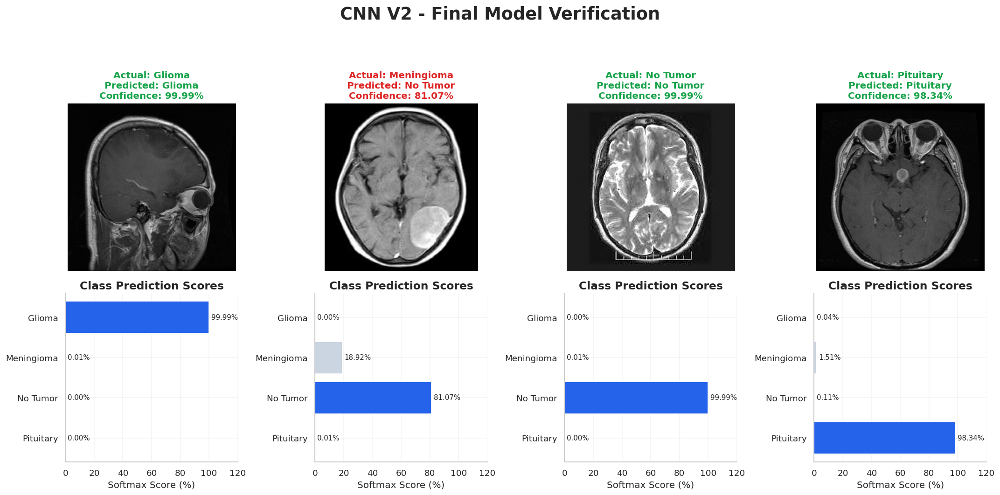

Grafik kaydedildi:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/29_final_model_verification.png

22.5 - FINAL INFERENCE TEST
----------------------------------------------------------------------


,image_path,actual_class,predicted_class,confidence,correct,saved_prediction_match,saved_probabilities_match
0,Testing/glioma/Te-gl_35.jpg,Glioma,Glioma,0.999898,True,True,True
1,Testing/meningioma/Te-me_42.jpg,Meningioma,No Tumor,0.810688,False,True,True
2,Testing/notumor/Te-no_284.jpg,No Tumor,No Tumor,0.999934,True,True,True
3,Testing/pituitary/Te-pi_288.jpg,Pituitary,Pituitary,0.983433,True,True,True


Dört görüntünün tahminleri doğrulandı.

22.6 - RESULT FILE INVENTORY
----------------------------------------------------------------------


,File_Type,File_Count,Total_Size_KB
0,.csv,37,919.06
1,.json,4,3.59
2,.npz,1,23.97
3,.png,29,21154.46
4,.txt,2,11.46


Grafik numaraları: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Eksik grafik numaraları: []
Toplam sonuç dosyası: 73
Mimari dışa aktarma uyarısı: source code not available
Orijinal ConvBlock ve CNN_V2 kodları manuel olarak aktarılmalı.

22.7 - APPLICATION PACKAGE
----------------------------------------------------------------------
cnn_v2_best.pth                    : HAZIR
cnn_v2_architecture.py             : EKSİK
deployment_config.json             : HAZIR
inference.py                       : HAZIR
requirements.txt                   : HAZIR
README.md                          : HAZIR
cnn_v2_final_summary.json          : HAZIR
Architecture Export: False
Integration Test: False
ZIP Package Ready: False

CNN V2 - FINAL PROJECT STATUS
Model checkpoint                        : TAMAMLANDI
Model architecture                      : TAMAMLANDI
Model weights                           : TAMAMLANDI
Preprocessing configuration        

In [38]:

# ============================================================
# 22. CNN V2 - FINAL MODEL AND FILE VERIFICATION
# 22.1 - 22.8 TÜM İŞLEMLER
# ============================================================

import os
import json
import torch
import torch.nn as nn
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import hashlib
import shutil
import inspect

from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from datetime import datetime
from IPython.display import display

print("=" * 70)
print("CNN V2 - FINAL MODEL AND FILE VERIFICATION")
print("=" * 70)

# ============================================================
# 22.1. PROJE KLASÖRLERİNİN KONTROLÜ
# ============================================================

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

model_klasoru = proje_yolu / "modeller"

sonuc_klasoru = (
    proje_yolu / "results" / "CNN_V2"
)

csv_yolu = proje_yolu / "veri_bolunmesi_v3"

dataset_root = Path("/content/CNN_V2_Dataset")

best_model_yolu = (
    model_klasoru / "cnn_v2_best.pth"
)

# Uygulama entegrasyonu için yeni klasör

deployment_klasoru = (
    proje_yolu / "deployment" / "CNN_V2"
)

deployment_klasoru.mkdir(
    parents=True,
    exist_ok=True
)

required_directories = {

    "Project Root": proje_yolu,

    "Models": model_klasoru,

    "Results": sonuc_klasoru,

    "Dataset Split": csv_yolu,

    "Dataset Root": dataset_root,

    "Deployment": deployment_klasoru

}

print("\n22.1 - DIRECTORY VERIFICATION")
print("-" * 70)

for name, path in required_directories.items():

    print(
        f"{name:25s}: "
        f"{'HAZIR' if path.is_dir() else 'EKSİK'}"
    )

assert all(
    path.is_dir()
    for path in required_directories.values()
)

# ============================================================
# 22.2. EĞİTİLMİŞ MODEL DOSYASININ DOĞRULANMASI
# ============================================================

assert best_model_yolu.is_file()

model_size_mb = (
    best_model_yolu.stat().st_size
    / (1024 ** 2)
)

# SHA256 - Dosya bütünlüğü kontrolü

def calculate_sha256(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


model_sha256 = calculate_sha256(
    best_model_yolu
)

checkpoint = torch.load(

    best_model_yolu,

    map_location="cpu",

    weights_only=False

)

CLASS_TO_IDX = {

    "glioma": 0,

    "meningioma": 1,

    "notumor": 2,

    "pituitary": 3

}

CLASS_NAMES = [

    "Glioma",

    "Meningioma",

    "No Tumor",

    "Pituitary"

]

assert checkpoint["model_name"] == "CNN_V2"

assert checkpoint["epoch"] == 33

assert checkpoint["dataset_version"] == (
    "veri_bolunmesi_v3"
)

assert checkpoint["class_to_idx"] == CLASS_TO_IDX

print("\n22.2 - CHECKPOINT VERIFICATION")
print("-" * 70)

print("Model Name:", checkpoint["model_name"])

print("Best Epoch:", checkpoint["epoch"])

print("Dataset Version:", checkpoint["dataset_version"])

print("File Size:", f"{model_size_mb:.2f} MB")

print("SHA256:", model_sha256)

print("Checkpoint doğrulandı.")

# ============================================================
# 22.3. MODEL MİMARİSİ VE AĞIRLIKLARI
# ============================================================

assert "CNN_V2" in globals(), (
    "Önce CNN_V2 sınıfını çalıştır."
)

assert "ConvBlock" in globals(), (
    "Önce ConvBlock sınıfını çalıştır."
)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

final_model = CNN_V2()

final_model.load_state_dict(

    checkpoint["model_state_dict"],

    strict=True

)

final_model = final_model.to(device)

final_model.eval()

total_parameters = sum(

    p.numel()

    for p in final_model.parameters()

)

trainable_parameters = sum(

    p.numel()

    for p in final_model.parameters()

    if p.requires_grad

)

conv_layers = [

    (name, layer)

    for name, layer in final_model.named_modules()

    if isinstance(layer, nn.Conv2d)

]

final_target_layer_name = conv_layers[-1][0]

assert total_parameters == 3337764

assert len(conv_layers) == 8

assert final_target_layer_name == (
    "features.3.block.3"
)

# Ağırlıkların sayısal kontrolü

assert all(

    torch.isfinite(tensor).all().item()

    for tensor in final_model.state_dict().values()

    if torch.is_floating_point(tensor)

), "Geçersiz model ağırlıkları bulundu."

# Model giriş-çıkış testi

dummy_input = torch.zeros(
    1, 1, 224, 224,
    device=device
)

with torch.inference_mode():

    dummy_output = final_model(
        dummy_input
    )

assert dummy_output.shape == (1, 4)

assert torch.isfinite(
    dummy_output
).all().item()

print("\n22.3 - MODEL ARCHITECTURE VERIFICATION")
print("-" * 70)

print("Total Parameters:", f"{total_parameters:,}")

print("Trainable Parameters:", f"{trainable_parameters:,}")

print("Convolution Layers:", len(conv_layers))

print("Grad-CAM Layer:", final_target_layer_name)

print("Input Shape:", tuple(dummy_input.shape))

print("Output Shape:", tuple(dummy_output.shape))

print("Device:", device)

print("Evaluation Mode:", not final_model.training)

print("Model ağırlıkları başarıyla doğrulandı.")

# ============================================================
# 22.4. UYGULAMA ÖN İŞLEME AYARLARI
# ============================================================

with open(

    sonuc_klasoru / "preprocessing_config.json",

    "r",

    encoding="utf-8"

) as f:

    preprocessing_config = json.load(f)


def get_scalar(value):

    if isinstance(value, (list, tuple)):

        return float(value[0])

    return float(value)


CNN_MEAN = get_scalar(
    preprocessing_config["mean"]
)

CNN_STD = get_scalar(
    preprocessing_config["std"]
)

IMAGE_SIZE = 224

assert np.isclose(
    CNN_MEAN,
    0.17666279376003613
)

assert np.isclose(
    CNN_STD,
    0.19102925562565193
)

final_transform = transforms.Compose([

    transforms.Grayscale(
        num_output_channels=1
    ),

    transforms.Resize(

        (IMAGE_SIZE, IMAGE_SIZE),

        interpolation=InterpolationMode.BILINEAR

    ),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[CNN_MEAN],

        std=[CNN_STD]

    )

])

deployment_config = {

    "model_name": "CNN_V2",

    "checkpoint": "cnn_v2_best.pth",

    "architecture_file": "cnn_v2_architecture.py",

    "framework": "PyTorch",

    "pytorch_version": torch.__version__,

    "torchvision_version": torchvision.__version__,

    "best_epoch": 33,

    "input_height": 224,

    "input_width": 224,

    "input_channels": 1,

    "image_mode": "L",

    "resize_interpolation": "bilinear",

    "tensor_range_before_normalization": [0, 1],

    "normalization_mean": [CNN_MEAN],

    "normalization_std": [CNN_STD],

    "number_of_classes": 4,

    "class_to_idx": CLASS_TO_IDX,

    "class_names": CLASS_NAMES,

    "output_type": "logits",

    "prediction_method": "softmax_argmax",

    "gradcam_target_layer": final_target_layer_name,

    "dataset_version": "veri_bolunmesi_v3",

    "checkpoint_sha256": model_sha256,

    "intended_use": "Academic demonstration only",

    "clinical_validation": False

}

with open(

    deployment_klasoru / "deployment_config.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        deployment_config,

        f,

        indent=4,

        ensure_ascii=False

    )

print("\n22.4 - DEPLOYMENT CONFIGURATION")
print("-" * 70)

print("Image Size: 224 x 224")

print("Channels: 1")

print("Mean:", CNN_MEAN)

print("Std:", CNN_STD)

print("Classes:", CLASS_NAMES)

print("Deployment config kaydedildi.")

# ============================================================
# 22.5. DÖRT SINIF ÜZERİNDE SON ÇALIŞMA TESTİ
# ============================================================

test_df = pd.read_csv(
    csv_yolu / "test.csv"
)

with np.load(

    sonuc_klasoru / "test_predictions.npz"

) as saved:

    y_true = saved["y_true"]

    y_pred = saved["y_pred"]

    y_prob = saved["y_prob"]

assert len(test_df) == len(y_true)

assert np.array_equal(

    test_df["sinif"].map(
        CLASS_TO_IDX
    ).to_numpy(),

    y_true

)

# Her sınıftan rastgele bir görüntü
# Doğru tahmin koşulu uygulanmaz.

verification_samples = pd.concat([

    test_df[
        test_df["sinif"] == class_key
    ].sample(
        n=1,
        random_state=42
    )

    for class_key in CLASS_TO_IDX

])

verification_results = []

fig, axes = plt.subplots(

    2, 4,

    figsize=(18, 9)

)

for i, (original_index, sample) in enumerate(

    verification_samples.iterrows()

):

    image_path = (
        dataset_root / sample["dosya"]
    )

    with Image.open(image_path) as img:

        image = img.convert("L")

    image_tensor = (

        final_transform(image)

        .unsqueeze(0)

        .to(device)

    )

    with torch.inference_mode():

        logits = final_model(
            image_tensor
        )

        probabilities = (

            torch.softmax(logits, dim=1)[0]

            .cpu()

            .numpy()

        )

    predicted_index = int(
        probabilities.argmax()
    )

    actual_index = CLASS_TO_IDX[
        sample["sinif"]
    ]

    actual_class = CLASS_NAMES[
        actual_index
    ]

    predicted_class = CLASS_NAMES[
        predicted_index
    ]

    confidence = float(
        probabilities[predicted_index]
    )

    correct = (
        actual_index == predicted_index
    )

    prediction_match = (

        predicted_index

        == int(y_pred[original_index])

    )

    probability_match = np.allclose(

        probabilities,

        y_prob[original_index],

        atol=0.005

    )

    verification_results.append({

        "image_path": sample["dosya"],

        "actual_class": actual_class,

        "predicted_class": predicted_class,

        "confidence": confidence,

        "correct": correct,

        "saved_prediction_match":
            prediction_match,

        "saved_probabilities_match":
            probability_match

    })

    result_color = (
        "#16A34A" if correct else "#DC2626"
    )

    # Üst sıra: Görüntüler

    axes[0, i].imshow(
        image,
        cmap="gray"
    )

    axes[0, i].set_title(

        f"Actual: {actual_class}\n"

        f"Predicted: {predicted_class}\n"

        f"Confidence: {confidence:.2%}",

        fontsize=12,

        fontweight="bold",

        color=result_color

    )

    axes[0, i].axis("off")

    # Alt sıra: Sınıf olasılıkları

    colors = [

        "#2563EB" if j == predicted_index

        else "#CBD5E1"

        for j in range(4)

    ]

    bars = axes[1, i].barh(

        CLASS_NAMES,

        probabilities * 100,

        color=colors

    )

    axes[1, i].bar_label(

        bars,

        fmt="%.2f%%",

        padding=3,

        fontsize=9

    )

    axes[1, i].set_xlim(0, 120)

    axes[1, i].invert_yaxis()

    axes[1, i].set_xlabel(
        "Softmax Score (%)"
    )

    axes[1, i].set_title(
        "Class Prediction Scores"
    )

    axes[1, i].set_axisbelow(True)

fig.suptitle(

    "CNN V2 - Final Model Verification",

    fontsize=22,

    fontweight="bold"

)

fig.tight_layout(
    rect=[0, 0, 1, 0.92]
)

grafik_kaydet(

    fig,

    "29_final_model_verification.png"

)

verification_df = pd.DataFrame(
    verification_results
)

verification_df.to_csv(

    sonuc_klasoru / "final_model_verification.csv",

    index=False

)

print("\n22.5 - FINAL INFERENCE TEST")
print("-" * 70)

display(verification_df)

assert verification_df[
    "saved_prediction_match"
].all()

assert verification_df[
    "saved_probabilities_match"
].all()

print("Dört görüntünün tahminleri doğrulandı.")

# ============================================================
# 22.6. SONUÇ DOSYALARININ ENVANTERİ
# ============================================================

result_files = sorted([

    path

    for path in sonuc_klasoru.iterdir()

    if path.is_file()

])

inventory = []

for path in result_files:

    inventory.append({

        "File_Name": path.name,

        "File_Type": path.suffix.lower(),

        "Size_KB": round(
            path.stat().st_size / 1024,
            2
        ),

        "Exists": path.is_file()

    })

inventory_df = pd.DataFrame(
    inventory
)

file_summary_df = (

    inventory_df.groupby("File_Type")

    .agg(

        File_Count=("File_Name", "count"),

        Total_Size_KB=("Size_KB", "sum")

    )

    .reset_index()

)

# 01 - 29 arasındaki grafik numaralarını kontrol et

graph_numbers = set()

for path in sonuc_klasoru.glob("*.png"):

    prefix = path.name.split("_")[0]

    if prefix.isdigit():

        graph_numbers.add(
            int(prefix)
        )

missing_graph_numbers = sorted(

    set(range(1, 30))

    - graph_numbers

)

print("\n22.6 - RESULT FILE INVENTORY")
print("-" * 70)

display(file_summary_df)

print(
    "Grafik numaraları:",
    sorted(graph_numbers)
)

print(
    "Eksik grafik numaraları:",
    missing_graph_numbers
)

print(
    "Toplam sonuç dosyası:",
    len(inventory_df)
)

inventory_df.to_csv(

    sonuc_klasoru / "final_file_inventory.csv",

    index=False

)

file_summary_df.to_csv(

    sonuc_klasoru / "final_file_summary.csv",

    index=False

)

# ============================================================
# 22.7. UYGULAMA ENTEGRASYON PAKETİ
# ============================================================

# Orijinal modelin kopyalanması

deployment_model_path = (

    deployment_klasoru / "cnn_v2_best.pth"

)

shutil.copy2(

    best_model_yolu,

    deployment_model_path

)

assert calculate_sha256(
    deployment_model_path
) == model_sha256

# Model mimarisini orijinal sınıflardan çıkar

architecture_ready = False

architecture_path = (

    deployment_klasoru / "cnn_v2_architecture.py"

)

try:

    architecture_code = (

        "import torch\n"

        "import torch.nn as nn\n"

        "import torch.nn.functional as F\n\n"

        + inspect.getsource(ConvBlock)

        + "\n\n"

        + inspect.getsource(CNN_V2)

        + "\n"

    )

    architecture_path.write_text(

        architecture_code,

        encoding="utf-8"

    )

    # Dışarı aktarılan mimariyi bağımsız doğrula

    import importlib.util

    spec = importlib.util.spec_from_file_location(

        "cnn_v2_exported",

        architecture_path

    )

    exported_module = (
        importlib.util.module_from_spec(spec)
    )

    spec.loader.exec_module(
        exported_module
    )

    exported_model = (
        exported_module.CNN_V2()
    )

    exported_model.load_state_dict(

        checkpoint["model_state_dict"],

        strict=True

    )

    exported_model.eval()

    with torch.inference_mode():

        exported_output = exported_model(
            dummy_input.cpu()
        )

    assert torch.allclose(

        exported_output,

        dummy_output.cpu(),

        atol=0.001

    )

    architecture_ready = True

except Exception as error:

    print(
        "Mimari dışa aktarma uyarısı:",
        error
    )

    print(
        "Orijinal ConvBlock ve CNN_V2 kodları "
        "manuel olarak aktarılmalı."
    )

    if architecture_path.exists():

        architecture_path.unlink()

# ------------------------------------------------------------
# UYGULAMA İÇİN TAHMİN FONKSİYONU
# ------------------------------------------------------------

inference_code = '''
import json
import torch

from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from cnn_v2_architecture import CNN_V2

BASE_DIR = Path(__file__).resolve().parent

with open(
    BASE_DIR / "deployment_config.json",
    encoding="utf-8"
) as f:

    config = json.load(f)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = config["class_names"]

model = CNN_V2().to(DEVICE)

checkpoint = torch.load(
    BASE_DIR / config["checkpoint"],
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),

    transforms.Resize(
        (config["input_height"], config["input_width"]),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=config["normalization_mean"],
        std=config["normalization_std"]
    )

])


def predict_image(image):

    if isinstance(image, Image.Image):

        image = image.convert("L")

    else:

        with Image.open(image) as img:

            image = img.convert("L")

    tensor = (
        transform(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.inference_mode():

        logits = model(tensor)

        probabilities = (
            torch.softmax(logits, dim=1)[0]
            .cpu()
            .tolist()
        )

    predicted_index = max(
        range(len(probabilities)),
        key=lambda i: probabilities[i]
    )

    return {

        "model": "CNN_V2",

        "predicted_class": CLASS_NAMES[predicted_index],

        "confidence": probabilities[predicted_index],

        "probabilities": {
            name: float(probabilities[i])
            for i, name in enumerate(CLASS_NAMES)
        },

        "clinical_use": False

    }
'''

inference_path = (
    deployment_klasoru / "inference.py"
)

inference_path.write_text(

    inference_code.strip() + "\n",

    encoding="utf-8"

)

# ------------------------------------------------------------
# GEREKLİ KÜTÜPHANELER
# ------------------------------------------------------------

requirements_text = (

    "torch\n"

    "torchvision\n"

    "Pillow\n"

)

(
    deployment_klasoru / "requirements.txt"
).write_text(

    requirements_text,

    encoding="utf-8"

)

# ------------------------------------------------------------
# MODEL BİLGİLENDİRME DOSYASI
# ------------------------------------------------------------

shutil.copy2(

    sonuc_klasoru / "cnn_v2_final_summary.json",

    deployment_klasoru / "cnn_v2_final_summary.json"

)

# ------------------------------------------------------------
# README DOSYASI
# ------------------------------------------------------------

readme_text = """
# CNN V2 - Brain Tumor Classification

## Model Information

- Architecture: CNN V2
- Input: 224 x 224 grayscale image
- Output: 4 classes
- Best checkpoint epoch: 33
- Parameters: 3,337,764
- Test Accuracy: 89.61%
- Macro F1-Score: 89.55%

## Classes

0. Glioma
1. Meningioma
2. No Tumor
3. Pituitary

## Installation

pip install -r requirements.txt

## Usage

from inference import predict_image

result = predict_image("example.jpg")

print(result)

The confidence scores are between 0 and 1.

## Important Limitations

- This model is intended for academic demonstrations.
- It has not been clinically validated.
- Confidence scores are not calibrated clinical probabilities.
- High-confidence incorrect predictions were observed.
- Grad-CAM maps do not represent validated tumor boundaries.
- The model must not replace medical diagnosis.

See cnn_v2_final_summary.json for evaluation results.
"""

(
    deployment_klasoru / "README.md"
).write_text(

    readme_text.strip() + "\n",

    encoding="utf-8"

)

# ------------------------------------------------------------
# UYGULAMA PAKETİNDEKİ TAHMİN FONKSİYONUNU TEST ET
# ------------------------------------------------------------

integration_ready = False

if architecture_ready:

    import sys

    sys.path.insert(
        0,
        str(deployment_klasoru)
    )

    try:

        import importlib

        # Eski import önbelleğini temizle

        sys.modules.pop(
            "inference",
            None
        )

        sys.modules.pop(
            "cnn_v2_architecture",
            None
        )

        inference_module = (
            importlib.import_module("inference")
        )

        integration_test_path = (

            dataset_root

            / verification_samples.iloc[0]["dosya"]

        )

        integration_result = (

            inference_module.predict_image(
                integration_test_path
            )

        )

        assert integration_result[
            "predicted_class"
        ] == verification_results[0][
            "predicted_class"
        ]

        assert np.isclose(

            integration_result["confidence"],

            verification_results[0]["confidence"],

            atol=0.005

        )

        integration_ready = True

        print("\nAPPLICATION INFERENCE TEST")

        print(
            json.dumps(

                integration_result,

                indent=4,

                ensure_ascii=False

            )
        )

    except Exception as error:

        print(
            "Entegrasyon testi uyarısı:",
            error
        )

    finally:

        sys.path.remove(
            str(deployment_klasoru)
        )

# ------------------------------------------------------------
# ZIP PAKETİ
# ------------------------------------------------------------

deployment_files = [

    "cnn_v2_best.pth",

    "cnn_v2_architecture.py",

    "deployment_config.json",

    "inference.py",

    "requirements.txt",

    "README.md",

    "cnn_v2_final_summary.json"

]

zip_path = (

    proje_yolu

    / "deployment"

    / "CNN_V2_Application_Package.zip"

)

package_ready = (

    integration_ready

    and all(

        (deployment_klasoru / name).is_file()

        for name in deployment_files

    )

)

if package_ready:

    with zipfile.ZipFile(

        zip_path,

        "w",

        compression=zipfile.ZIP_DEFLATED

    ) as package:

        for filename in deployment_files:

            package.write(

                deployment_klasoru / filename,

                arcname=filename

            )

    with zipfile.ZipFile(
        zip_path, "r"
    ) as package:

        assert package.testzip() is None

        assert set(
            package.namelist()
        ) == set(deployment_files)

print("\n22.7 - APPLICATION PACKAGE")
print("-" * 70)

for filename in deployment_files:

    print(

        f"{filename:35s}: "

        f"{'HAZIR' if (deployment_klasoru / filename).is_file() else 'EKSİK'}"

    )

print("Architecture Export:", architecture_ready)

print("Integration Test:", integration_ready)

print("ZIP Package Ready:", package_ready)

# ============================================================
# 22.8. NİHAİ PROJE KONTROLÜ
# ============================================================

final_verification = {

    "model_name": "CNN_V2",

    "verification_date": datetime.now().isoformat(),

    "best_epoch": 33,

    "model_size_mb": model_size_mb,

    "model_sha256": model_sha256,

    "total_parameters": total_parameters,

    "convolution_layers": len(conv_layers),

    "gradcam_target_layer": final_target_layer_name,

    "checkpoint_verified": True,

    "model_weights_verified": True,

    "preprocessing_verified": True,

    "smoke_test_images": len(verification_df),

    "smoke_test_predictions_match": bool(

        verification_df[
            "saved_prediction_match"
        ].all()

    ),

    "smoke_test_probabilities_match": bool(

        verification_df[
            "saved_probabilities_match"
        ].all()

    ),

    "numbered_graphs_found": len(graph_numbers),

    "missing_graph_numbers": missing_graph_numbers,

    "architecture_exported": architecture_ready,

    "application_integration_verified":
        integration_ready,

    "application_package_ready": package_ready

}

with open(

    sonuc_klasoru / "final_verification.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        final_verification,

        f,

        indent=4,

        ensure_ascii=False

    )

final_checks = {

    "Model checkpoint": True,

    "Model architecture": True,

    "Model weights": True,

    "Preprocessing configuration": True,

    "Saved prediction consistency": bool(

        verification_df[
            "saved_prediction_match"
        ].all()

    ),

    "Graphics 01-29": (
        len(missing_graph_numbers) == 0
    ),

    "Architecture export": architecture_ready,

    "Application integration": integration_ready,

    "Application ZIP package": package_ready

}

print("\n" + "=" * 70)
print("CNN V2 - FINAL PROJECT STATUS")
print("=" * 70)

for name, status in final_checks.items():

    print(

        f"{name:40s}: "

        f"{'TAMAMLANDI' if status else 'KONTROL GEREKLİ'}"

    )

print("\nSonuç klasörü:")

print(sonuc_klasoru)

print("\nUygulama klasörü:")

print(deployment_klasoru)

if package_ready:

    print("\nUygulama ZIP dosyası:")

    print(zip_path)

    print(

        "ZIP Boyutu:",

        f"{zip_path.stat().st_size / (1024 ** 2):.2f} MB"

    )

print("\n" + "=" * 70)

if all(final_checks.values()):

    print("CNN V2 MODEL DEVELOPMENT COMPLETED")

    print("TÜM MODEL KONTROLLERİ BAŞARILI")

    print("UYGULAMA ENTEGRASYON PAKETİ HAZIR")

    print("23. ADIM - TEKNİK RAPOR İÇİN HAZIR")

else:

    print("CNN V2 FINAL VERIFICATION SAVED")

    print("EKSİK KONTROLLER İNCELENMELİ")

print("=" * 70)


In [39]:
# ==================================================
# 22 - FINAL STATUS CHECK
# ==================================================

from pathlib import Path
import json

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

sonuc_klasoru = proje_yolu / "results" / "CNN_V2"

deployment_klasoru = proje_yolu / "deployment" / "CNN_V2"

print("=" * 65)
print("CNN V2 - FINAL STATUS CHECK")
print("=" * 65)

required_files = {
    "Eğitilmiş model":
        proje_yolu / "modeller" / "cnn_v2_best.pth",

    "Grafik 29":
        sonuc_klasoru / "29_final_model_verification.png",

    "Model doğrulama sonuçları":
        sonuc_klasoru / "final_model_verification.csv",

    "Dosya envanteri":
        sonuc_klasoru / "final_file_inventory.csv",

    "Model mimarisi":
        deployment_klasoru / "cnn_v2_architecture.py",

    "Uygulama modeli":
        deployment_klasoru / "cnn_v2_best.pth",

    "Uygulama ayarları":
        deployment_klasoru / "deployment_config.json",

    "Tahmin fonksiyonu":
        deployment_klasoru / "inference.py",

    "Gerekli kütüphaneler":
        deployment_klasoru / "requirements.txt",

    "README":
        deployment_klasoru / "README.md",

    "Uygulama ZIP paketi":
        proje_yolu / "deployment" / "CNN_V2_Application_Package.zip",

    "Nihai doğrulama raporu":
        sonuc_klasoru / "final_verification.json"
}

for name, path in required_files.items():

    print(
        f"{name:35s}: "
        f"{'HAZIR' if path.is_file() else 'EKSİK'}"
    )

print("\n" + "=" * 65)
print("FINAL VERIFICATION DETAILS")
print("=" * 65)

verification_path = (
    sonuc_klasoru / "final_verification.json"
)

if verification_path.is_file():

    with open(
        verification_path,
        "r",
        encoding="utf-8"
    ) as f:

        verification = json.load(f)

    print(
        json.dumps(
            verification,
            indent=4,
            ensure_ascii=False
        )
    )

else:

    print("Nihai doğrulama dosyası henüz oluşturulmamış.")

print("\n" + "=" * 65)

if all(path.is_file() for path in required_files.values()):

    print("TÜM GEREKLİ DOSYALAR MEVCUT")
    print("Doğrulama ayrıntıları incelenmeli.")

else:

    print("EKSİK DOSYALAR KONTROL EDİLMELİ.")

print("=" * 65)

CNN V2 - FINAL STATUS CHECK
Eğitilmiş model                    : HAZIR
Grafik 29                          : HAZIR
Model doğrulama sonuçları          : HAZIR
Dosya envanteri                    : HAZIR
Model mimarisi                     : EKSİK
Uygulama modeli                    : HAZIR
Uygulama ayarları                  : HAZIR
Tahmin fonksiyonu                  : HAZIR
Gerekli kütüphaneler               : HAZIR
README                             : HAZIR
Uygulama ZIP paketi                : EKSİK
Nihai doğrulama raporu             : HAZIR

FINAL VERIFICATION DETAILS
{
    "model_name": "CNN_V2",
    "verification_date": "2026-11-19T08:02:23.816345",
    "best_epoch": 33,
    "model_size_mb": 38.28757572174072,
    "model_sha256": "ae6501b19f70a1479374d9111cc954a76a2e1fa77a6863ddf159c3b03bf1fa98",
    "total_parameters": 3337764,
    "convolution_layers": 8,
    "gradcam_target_layer": "features.3.block.3",
    "checkpoint_verified": true,
    "model_weights_verified": true,
    "preproc

In [40]:

# ============================================================
# 22.9. CNN V2 - FINAL APPLICATION PACKAGE
# 22.9.1 - 22.9.7 TÜM İŞLEMLER
# ============================================================

import json
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import hashlib
import zipfile
import sys
import subprocess
import tempfile
import textwrap

from pathlib import Path
from datetime import datetime
from IPython.display import display

print("=" * 70)
print("CNN V2 - FINAL APPLICATION PACKAGE")
print("=" * 70)

# ============================================================
# PROJE YOLLARI
# ============================================================

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

sonuc_klasoru = proje_yolu / "results" / "CNN_V2"

deployment_klasoru = proje_yolu / "deployment" / "CNN_V2"

dataset_root = Path("/content/CNN_V2_Dataset")

best_model_yolu = (
    proje_yolu / "modeller" / "cnn_v2_best.pth"
)

deployment_klasoru.mkdir(
    parents=True,
    exist_ok=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert best_model_yolu.is_file()

def calculate_sha256(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


original_sha256 = calculate_sha256(
    best_model_yolu
)

# ============================================================
# 22.9.1. ORİJİNAL MODEL MİMARİSİNİN AKTARILMASI
# ============================================================

architecture_code = """
import torch
import torch.nn as nn


class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.1
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Dropout2d(p=dropout)

        )

    def forward(self, x):

        return self.block(x)


class CNN_V2(nn.Module):

    def __init__(self, num_classes=4):

        super().__init__()

        self.features = nn.Sequential(

            ConvBlock(
                in_channels=1,
                out_channels=32,
                dropout=0.05
            ),

            ConvBlock(
                in_channels=32,
                out_channels=64,
                dropout=0.10
            ),

            ConvBlock(
                in_channels=64,
                out_channels=128,
                dropout=0.15
            ),

            ConvBlock(
                in_channels=128,
                out_channels=256,
                dropout=0.20
            )

        )

        self.avgpool = nn.AdaptiveAvgPool2d(
            output_size=(4, 4)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 4 * 4, 512),

            nn.BatchNorm1d(512),

            nn.ReLU(inplace=True),

            nn.Dropout(0.40),

            nn.Linear(512, 128),

            nn.BatchNorm1d(128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.30),

            nn.Linear(128, num_classes)

        )

        self._initialize_weights()


    def _initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Conv2d):

                nn.init.kaiming_normal_(
                    m.weight,
                    mode="fan_in",
                    nonlinearity="relu"
                )

            elif isinstance(
                m,
                (nn.BatchNorm2d, nn.BatchNorm1d)
            ):

                nn.init.ones_(m.weight)

                nn.init.zeros_(m.bias)

            elif isinstance(m, nn.Linear):

                nn.init.kaiming_normal_(
                    m.weight,
                    mode="fan_in",
                    nonlinearity="relu"
                )

                if m.bias is not None:

                    nn.init.zeros_(m.bias)

        nn.init.xavier_uniform_(
            self.classifier[-1].weight
        )


    def forward(self, x):

        x = self.features(x)

        x = self.avgpool(x)

        x = self.classifier(x)

        return x
"""

architecture_path = (
    deployment_klasoru / "cnn_v2_architecture.py"
)

architecture_path.write_text(
    architecture_code.strip() + "\n",
    encoding="utf-8"
)

# Python sözdizimi kontrolü

compile(
    architecture_code,
    str(architecture_path),
    "exec"
)

print("\n22.9.1 - ARCHITECTURE EXPORT")
print("-" * 70)

print("ConvBlock: HAZIR")
print("CNN_V2: HAZIR")
print("Python Syntax: BAŞARILI")
print("Architecture File:", architecture_path.name)

# ============================================================
# 22.9.2. GÜVENLİ MODEL AĞIRLIKLARININ KAYDEDİLMESİ
# ============================================================

# Yalnızca kendi eğittiğimiz güvenilir orijinal dosya
# weights_only=False ile açılıyor.

checkpoint = torch.load(

    best_model_yolu,

    map_location="cpu",

    weights_only=False

)

assert checkpoint["model_name"] == "CNN_V2"
assert int(checkpoint["epoch"]) == 33

CLASS_TO_IDX = {

    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3

}

CLASS_NAMES = [

    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"

]

assert checkpoint["class_to_idx"] == CLASS_TO_IDX

# Yalnızca tensörler ve güvenli temel veri türleri.
# Optimizer ve NumPy nesneleri aktarılmıyor.

safe_checkpoint = {

    "model_name": "CNN_V2",

    "epoch": int(checkpoint["epoch"]),

    "dataset_version": "veri_bolunmesi_v3",

    "class_to_idx": CLASS_TO_IDX,

    "model_state_dict": {

        name: tensor.detach().cpu().clone()

        for name, tensor
        in checkpoint["model_state_dict"].items()

    }

}

safe_model_path = (
    deployment_klasoru / "cnn_v2_best.pth"
)

torch.save(

    safe_checkpoint,

    safe_model_path

)

# Güvenli checkpoint yeniden yükleniyor.

loaded_safe_checkpoint = torch.load(

    safe_model_path,

    map_location="cpu",

    weights_only=True

)

# Orijinal ağırlıklarla birebir eşitlik kontrolü

original_state = checkpoint["model_state_dict"]

safe_state = loaded_safe_checkpoint["model_state_dict"]

assert set(original_state.keys()) == set(safe_state.keys())

weights_identical = all(

    torch.equal(

        original_state[name].cpu(),

        safe_state[name]

    )

    for name in original_state

)

assert weights_identical

original_size = (
    best_model_yolu.stat().st_size / 1024**2
)

deployment_size = (
    safe_model_path.stat().st_size / 1024**2
)

safe_sha256 = calculate_sha256(
    safe_model_path
)

size_reduction = (
    1 - deployment_size / original_size
) * 100

print("\n22.9.2 - SAFE CHECKPOINT")
print("-" * 70)

print(f"Original Model: {original_size:.2f} MB")

print(f"Deployment Model: {deployment_size:.2f} MB")

print(f"Size Reduction: {size_reduction:.2f}%")

print("Weights Identical:", weights_identical)

print("weights_only=True: BAŞARILI")

print("Safe Checkpoint SHA256:", safe_sha256)

# ============================================================
# 22.9.3. UYGULAMA AYARLARININ GÜNCELLENMESİ
# ============================================================

config_path = (

    deployment_klasoru / "deployment_config.json"

)

with open(config_path, encoding="utf-8") as f:

    config = json.load(f)

config.update({

    "checkpoint": "cnn_v2_best.pth",

    "architecture_file": "cnn_v2_architecture.py",

    "checkpoint_sha256": safe_sha256,

    "original_checkpoint_sha256": original_sha256,

    "weights_only": True,

    "input_height": 224,

    "input_width": 224,

    "input_channels": 1,

    "normalization_mean": [0.17666279376003613],

    "normalization_std": [0.19102925562565193],

    "class_to_idx": CLASS_TO_IDX,

    "class_names": CLASS_NAMES,

    "clinical_validation": False,

    "intended_use": "Academic demonstration only"

})

with open(

    config_path,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        config,

        f,

        indent=4,

        ensure_ascii=False

    )

# ------------------------------------------------------------
# GÜVENLİ TAHMİN FONKSİYONU
# ------------------------------------------------------------

inference_code = """
import json
import hashlib
import torch

from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from cnn_v2_architecture import CNN_V2

BASE_DIR = Path(__file__).resolve().parent

with open(
    BASE_DIR / "deployment_config.json",
    encoding="utf-8"
) as f:

    config = json.load(f)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = config["class_names"]

checkpoint_path = BASE_DIR / config["checkpoint"]

with open(checkpoint_path, "rb") as f:

    checksum = hashlib.sha256(f.read()).hexdigest()

if checksum != config["checkpoint_sha256"]:

    raise RuntimeError("Checkpoint checksum mismatch")

checkpoint = torch.load(

    checkpoint_path,

    map_location="cpu",

    weights_only=True

)

model = CNN_V2().to(DEVICE)

model.load_state_dict(

    checkpoint["model_state_dict"],

    strict=True

)

model.eval()

transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),

    transforms.Resize(

        (
            config["input_height"],
            config["input_width"]
        ),

        interpolation=InterpolationMode.BILINEAR

    ),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=config["normalization_mean"],

        std=config["normalization_std"]

    )

])


def predict_image(image):

    if isinstance(image, Image.Image):

        image = image.convert("L")

    else:

        with Image.open(image) as img:

            image = img.convert("L")

    tensor = (

        transform(image)

        .unsqueeze(0)

        .to(DEVICE)

    )

    with torch.inference_mode():

        logits = model(tensor)

        probabilities = (

            torch.softmax(logits, dim=1)[0]

            .cpu()

            .tolist()

        )

    predicted_index = max(

        range(len(probabilities)),

        key=lambda i: probabilities[i]

    )

    return {

        "model": "CNN_V2",

        "predicted_class": CLASS_NAMES[predicted_index],

        "confidence": probabilities[predicted_index],

        "probabilities": {

            name: float(probabilities[i])

            for i, name in enumerate(CLASS_NAMES)

        },

        "clinical_use": False

    }
"""

inference_path = (

    deployment_klasoru / "inference.py"

)

inference_path.write_text(

    inference_code.strip() + "\n",

    encoding="utf-8"

)

compile(

    inference_code,

    str(inference_path),

    "exec"

)

# Kütüphane sürümlerini kayıt altına al

import torchvision
import PIL

requirements_text = (

    "torch\n"

    "torchvision\n"

    "Pillow\n"

)

(
    deployment_klasoru / "requirements.txt"
).write_text(

    requirements_text,

    encoding="utf-8"

)

config["tested_library_versions"] = {

    "torch": str(torch.__version__),

    "torchvision": str(torchvision.__version__),

    "Pillow": str(PIL.__version__)

}

with open(config_path, "w", encoding="utf-8") as f:

    json.dump(config, f, indent=4, ensure_ascii=False)

print("\n22.9.3 - DEPLOYMENT CONFIGURATION")
print("-" * 70)

print("Deployment Configuration: HAZIR")

print("Safe Inference Function: HAZIR")

print("Checkpoint Integrity Check: HAZIR")

print("Library Requirements: HAZIR")

# ============================================================
# 22.9.4. BAĞIMSIZ MODEL YÜKLEME TESTİ
# ============================================================

# Model, Colab'ın mevcut değişkenlerinden bağımsız
# yeni bir Python işleminde çalıştırılıyor.

architecture_test_code = """
import json
import torch
import torch.nn as nn
import inference

model = inference.model

total_parameters = sum(
    p.numel() for p in model.parameters()
)

conv_layers = [
    (name, layer)
    for name, layer in model.named_modules()
    if isinstance(layer, nn.Conv2d)
]

assert total_parameters == 3337764

assert len(conv_layers) == 8

assert conv_layers[-1][0] == "features.3.block.3"

assert not model.training

dummy_input = torch.zeros(
    1, 1, 224, 224,
    device=inference.DEVICE
)

with torch.inference_mode():

    output = model(dummy_input)

assert tuple(output.shape) == (1, 4)

assert torch.isfinite(output).all().item()

print(json.dumps({

    "total_parameters": total_parameters,

    "convolution_layers": len(conv_layers),

    "gradcam_target_layer": conv_layers[-1][0],

    "output_shape": list(output.shape),

    "device": str(inference.DEVICE),

    "evaluation_mode": not model.training

}))
"""

architecture_process = subprocess.run(

    [
        sys.executable,
        "-c",
        architecture_test_code
    ],

    cwd=str(deployment_klasoru),

    capture_output=True,

    text=True,

    timeout=300

)

if architecture_process.returncode != 0:

    print(architecture_process.stderr)

    raise RuntimeError(
        "Bağımsız model testi başarısız."
    )

architecture_result = json.loads(

    architecture_process.stdout.strip().splitlines()[-1]

)

print("\n22.9.4 - INDEPENDENT MODEL TEST")
print("-" * 70)

print(

    json.dumps(

        architecture_result,

        indent=4

    )

)

print("Independent Model Loading: BAŞARILI")

# ============================================================
# 22.9.5. ENTEGRASYON TESTİ
# ============================================================

verification_df = pd.read_csv(

    sonuc_klasoru / "final_model_verification.csv"

)

test_df = pd.read_csv(

    proje_yolu / "veri_bolunmesi_v3" / "test.csv"

)

assert test_df["dosya"].is_unique

with np.load(

    sonuc_klasoru / "test_predictions.npz"

) as saved:

    saved_y_true = saved["y_true"]

    saved_y_pred = saved["y_pred"]

    saved_y_prob = saved["y_prob"]

assert len(test_df) == len(saved_y_true)

assert len(verification_df) == 4

assert np.array_equal(

    test_df["sinif"].map(CLASS_TO_IDX).to_numpy(),

    saved_y_true

)

# Önceki dört doğrulama görüntüsü kullanılıyor.

integration_images = [

    str(dataset_root / path)

    for path in verification_df["image_path"]

]

assert all(

    Path(path).is_file()

    for path in integration_images

)

integration_test_code = """
import json
import sys
from inference import predict_image

paths = json.loads(sys.argv[1])

results = [

    predict_image(path)

    for path in paths

]

print(json.dumps(results))
"""

integration_process = subprocess.run(

    [

        sys.executable,

        "-c",

        integration_test_code,

        json.dumps(integration_images)

    ],

    cwd=str(deployment_klasoru),

    capture_output=True,

    text=True,

    timeout=300

)

if integration_process.returncode != 0:

    print(integration_process.stderr)

    raise RuntimeError(
        "Uygulama entegrasyon testi başarısız."
    )

application_predictions = json.loads(

    integration_process.stdout.strip().splitlines()[-1]

)

integration_results = []

for i, row in verification_df.iterrows():

    image_path = row["image_path"]

    result = application_predictions[i]

    original_index = test_df.index[

        test_df["dosya"] == image_path

    ][0]

    reference_probabilities = (

        saved_y_prob[original_index]

    )

    new_probabilities = np.array([

        result["probabilities"][name]

        for name in CLASS_NAMES

    ])

    predicted_class = result["predicted_class"]

    expected_class = CLASS_NAMES[

        int(saved_y_pred[original_index])

    ]

    actual_class = CLASS_NAMES[

        int(saved_y_true[original_index])

    ]

    prediction_match = (

        predicted_class == expected_class

    )

    probability_match = np.allclose(

        new_probabilities,

        reference_probabilities,

        atol=0.005,

        rtol=0

    )

    integration_results.append({

        "image_path": image_path,

        "actual_class": actual_class,

        "expected_prediction": expected_class,

        "application_prediction": predicted_class,

        "confidence": result["confidence"],

        "correct": actual_class == predicted_class,

        "prediction_match": bool(prediction_match),

        "probabilities_match": bool(probability_match),

        "max_probability_difference": float(

            np.max(

                np.abs(

                    new_probabilities

                    - reference_probabilities

                )

            )

        )

    })

integration_df = pd.DataFrame(

    integration_results

)

integration_df.to_csv(

    sonuc_klasoru / "application_integration_test.csv",

    index=False

)

assert integration_df["prediction_match"].all()

assert integration_df["probabilities_match"].all()

print("\n22.9.5 - APPLICATION INTEGRATION TEST")
print("-" * 70)

display(integration_df)

print(

    "Matching Predictions:",

    f"{integration_df['prediction_match'].sum()}/4"

)

print(

    "Matching Probabilities:",

    f"{integration_df['probabilities_match'].sum()}/4"

)

print("Application Integration: BAŞARILI")

# ============================================================
# 22.9.6. README VE ZIP PAKETİNİN OLUŞTURULMASI
# ============================================================

readme_text = """
# CNN V2 - Brain Tumor Classification

## Model Information

- Architecture: CNN V2
- Input: 224 x 224 grayscale image
- Convolution Layers: 8
- Parameters: 3,337,764
- Best Epoch: 33
- Test Accuracy: 89.61%
- Macro Precision: 91.06%
- Macro Recall: 89.49%
- Macro F1-Score: 89.55%

## Classes

0. Glioma
1. Meningioma
2. No Tumor
3. Pituitary

## Installation

Install compatible PyTorch and torchvision versions
for your operating system and CPU/GPU environment.

pip install -r requirements.txt

Tested library versions are stored in
deployment_config.json.

## Python Usage

from inference import predict_image

result = predict_image("example.jpg")

print(result)

## Checkpoint Security

The deployment checkpoint contains model tensors
and basic metadata.

It supports torch.load(weights_only=True).

The checkpoint SHA256 checksum is verified at load time.

## Grad-CAM

Target layer: features.3.block.3

Grad-CAM was evaluated in the research notebook.
The application inference module currently provides
classification and class scores only.

## Limitations

- Academic demonstration only.
- Not clinically validated.
- Confidence scores are not calibrated probabilities.
- High-confidence incorrect predictions were observed.
- Grad-CAM is not a tumor segmentation method.
- Patient-level dataset separation could not be verified.
- This model must not replace medical diagnosis.
"""

(
    deployment_klasoru / "README.md"
).write_text(

    readme_text.strip() + "\n",

    encoding="utf-8"

)

deployment_files = [

    "cnn_v2_best.pth",

    "cnn_v2_architecture.py",

    "deployment_config.json",

    "inference.py",

    "requirements.txt",

    "README.md",

    "cnn_v2_final_summary.json"

]

assert all(

    (deployment_klasoru / name).is_file()

    for name in deployment_files

)

zip_path = (

    proje_yolu

    / "deployment"

    / "CNN_V2_Application_Package.zip"

)

temporary_zip = zip_path.with_suffix(".tmp")

with zipfile.ZipFile(

    temporary_zip,

    mode="w",

    compression=zipfile.ZIP_DEFLATED

) as package:

    for filename in deployment_files:

        package.write(

            deployment_klasoru / filename,

            arcname=filename

        )

# ZIP bütünlüğü kontrolü

with zipfile.ZipFile(temporary_zip, "r") as package:

    assert package.testzip() is None

    assert set(package.namelist()) == set(deployment_files)

    # ZIP içerisinden çıkarılan bağımsız paket de test edilir.

    with tempfile.TemporaryDirectory() as temp_dir:

        package.extractall(temp_dir)

        extracted_process = subprocess.run(

            [

                sys.executable,

                "-c",

                integration_test_code,

                json.dumps(integration_images)

            ],

            cwd=temp_dir,

            capture_output=True,

            text=True,

            timeout=300

        )

        if extracted_process.returncode != 0:

            print(extracted_process.stderr)

            raise RuntimeError(
                "ZIP içinden çıkarılan paket çalışmadı."
            )

        extracted_predictions = json.loads(

            extracted_process.stdout.strip().splitlines()[-1]

        )

        for expected, actual in zip(

            application_predictions,

            extracted_predictions

        ):

            assert (

                expected["predicted_class"]

                == actual["predicted_class"]

            )

            assert np.allclose(

                list(expected["probabilities"].values()),

                list(actual["probabilities"].values()),

                atol=0.005,

                rtol=0

            )

temporary_zip.replace(zip_path)

zip_size_mb = zip_path.stat().st_size / 1024**2

print("\n22.9.6 - ZIP APPLICATION PACKAGE")
print("-" * 70)

for filename in deployment_files:

    size_kb = (

        deployment_klasoru / filename

    ).stat().st_size / 1024

    print(

        f"{filename:35s}: HAZIR "

        f"({size_kb:.2f} KB)"

    )

print("\nZIP Integrity Check: BAŞARILI")

print("Extracted Package Test: BAŞARILI")

print(f"ZIP Size: {zip_size_mb:.2f} MB")

# ============================================================
# 22.9.7. NİHAİ DOĞRULAMA RAPORU
# ============================================================

verification_path = (

    sonuc_klasoru / "final_verification.json"

)

with open(

    verification_path,

    encoding="utf-8"

) as f:

    final_verification = json.load(f)

# Orijinal eğitilmiş model değişmedi.

original_model_unchanged = (

    calculate_sha256(best_model_yolu)

    == original_sha256

)

assert original_model_unchanged

final_verification.update({

    "verification_date": datetime.now().isoformat(),

    "architecture_exported": True,

    "application_integration_verified": True,

    "application_package_ready": True,

    "safe_checkpoint_verified": True,

    "deployment_weights_identical": True,

    "original_model_unchanged": original_model_unchanged,

    "deployment_model_size_mb": deployment_size,

    "deployment_checkpoint_sha256": safe_sha256,

    "deployment_package_size_mb": zip_size_mb,

    "deployment_package_sha256": calculate_sha256(zip_path),

    "deployment_package_files": len(deployment_files),

    "independent_model_test": True,

    "extracted_zip_test": True,

    "integration_test_images": len(integration_df),

    "integration_predictions_match": True,

    "integration_probabilities_match": True

})

with open(

    verification_path,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        final_verification,

        f,

        indent=4,

        ensure_ascii=False

    )

# ============================================================
# NİHAİ DURUM TABLOSU
# ============================================================

final_checks = {

    "Original Model Preserved": original_model_unchanged,

    "Model Architecture Exported": True,

    "Safe Checkpoint Created": True,

    "Original Weights Preserved": weights_identical,

    "Independent Model Loading": True,

    "Preprocessing Configuration": True,

    "Four-Class Integration Test": True,

    "Saved Prediction Consistency": True,

    "Saved Probability Consistency": True,

    "ZIP Integrity Check": True,

    "Extracted Package Test": True,

    "Final Verification Report": True

}

status_df = pd.DataFrame([

    {

        "Control": name,

        "Status": "COMPLETED" if status else "FAILED"

    }

    for name, status in final_checks.items()

])

status_df.to_csv(

    sonuc_klasoru / "application_package_status.csv",

    index=False

)

# Güncel sonuç dosyalarının envanteri

inventory_df = pd.DataFrame([

    {

        "File_Name": path.name,

        "File_Type": path.suffix.lower(),

        "Size_KB": round(path.stat().st_size / 1024, 2),

        "Exists": True

    }

    for path in sorted(sonuc_klasoru.iterdir())

    if path.is_file()

])

inventory_df.to_csv(

    sonuc_klasoru / "final_file_inventory.csv",

    index=False

)

inventory_df.groupby("File_Type").agg(

    File_Count=("File_Name", "count"),

    Total_Size_KB=("Size_KB", "sum")

).reset_index().to_csv(

    sonuc_klasoru / "final_file_summary.csv",

    index=False

)

print("\n" + "=" * 70)
print("CNN V2 - FINAL DEVELOPMENT STATUS")
print("=" * 70)

display(status_df)

print("\nOriginal Model Size:", f"{original_size:.2f} MB")

print("Safe Deployment Model:", f"{deployment_size:.2f} MB")

print("Application ZIP Size:", f"{zip_size_mb:.2f} MB")

print("Original Model Unchanged:", original_model_unchanged)

print("\nApplication Package:")

print(zip_path)

print("\nVerification Report:")

print(verification_path)

print("\n" + "=" * 70)

assert all(final_checks.values())

print("CNN V2 MODEL DEVELOPMENT COMPLETED")
print("ALL APPLICATION TESTS PASSED")
print("APPLICATION PACKAGE READY")
print("23. ADIM - TEKNİK RAPOR İÇİN HAZIR")

print("=" * 70)


CNN V2 - FINAL APPLICATION PACKAGE

22.9.1 - ARCHITECTURE EXPORT
----------------------------------------------------------------------
ConvBlock: HAZIR
CNN_V2: HAZIR
Python Syntax: BAŞARILI
Architecture File: cnn_v2_architecture.py

22.9.2 - SAFE CHECKPOINT
----------------------------------------------------------------------
Original Model: 38.29 MB
Deployment Model: 12.76 MB
Size Reduction: 66.66%
Weights Identical: True
weights_only=True: BAŞARILI
Safe Checkpoint SHA256: 1db0933dd7d31baa1ed1ea439db9f2ab2ca99ac25bbf40cba413d44ed62a9b65

22.9.3 - DEPLOYMENT CONFIGURATION
----------------------------------------------------------------------
Deployment Configuration: HAZIR
Safe Inference Function: HAZIR
Checkpoint Integrity Check: HAZIR
Library Requirements: HAZIR

22.9.4 - INDEPENDENT MODEL TEST
----------------------------------------------------------------------
{
    "total_parameters": 3337764,
    "convolution_layers": 8,
    "gradcam_target_layer": "features.3.block.3",
    "

,image_path,actual_class,expected_prediction,application_prediction,confidence,correct,prediction_match,probabilities_match,max_probability_difference
0,Testing/glioma/Te-gl_35.jpg,Glioma,Glioma,Glioma,0.999898,True,True,True,3.783498e-10
1,Testing/meningioma/Te-me_42.jpg,Meningioma,No Tumor,No Tumor,0.810688,False,True,True,5.960464e-08
2,Testing/notumor/Te-no_284.jpg,No Tumor,No Tumor,No Tumor,0.999934,True,True,True,6.366463e-12
3,Testing/pituitary/Te-pi_288.jpg,Pituitary,Pituitary,Pituitary,0.983433,True,True,True,2.793968e-08


Matching Predictions: 4/4
Matching Probabilities: 4/4
Application Integration: BAŞARILI

22.9.6 - ZIP APPLICATION PACKAGE
----------------------------------------------------------------------
cnn_v2_best.pth                    : HAZIR (13070.31 KB)
cnn_v2_architecture.py             : HAZIR (3.07 KB)
deployment_config.json             : HAZIR (1.42 KB)
inference.py                       : HAZIR (2.22 KB)
requirements.txt                   : HAZIR (0.02 KB)
README.md                          : HAZIR (1.36 KB)
cnn_v2_final_summary.json          : HAZIR (1.56 KB)

ZIP Integrity Check: BAŞARILI
Extracted Package Test: BAŞARILI
ZIP Size: 11.85 MB

CNN V2 - FINAL DEVELOPMENT STATUS


,Control,Status
0,Original Model Preserved,COMPLETED
1,Model Architecture Exported,COMPLETED
2,Safe Checkpoint Created,COMPLETED
3,Original Weights Preserved,COMPLETED
4,Independent Model Loading,COMPLETED
5,Preprocessing Configuration,COMPLETED
6,Four-Class Integration Test,COMPLETED
7,Saved Prediction Consistency,COMPLETED
8,Saved Probability Consistency,COMPLETED
9,ZIP Integrity Check,COMPLETED



Original Model Size: 38.29 MB
Safe Deployment Model: 12.76 MB
Application ZIP Size: 11.85 MB
Original Model Unchanged: True

Application Package:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/deployment/CNN_V2_Application_Package.zip

Verification Report:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/CNN_V2/final_verification.json

CNN V2 MODEL DEVELOPMENT COMPLETED
ALL APPLICATION TESTS PASSED
APPLICATION PACKAGE READY
23. ADIM - TEKNİK RAPOR İÇİN HAZIR
